# [12.1] CLIP and SigLIP from Scratch (exercises)

> **Colab: [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter12_vlm_interpretability/exercises/part1_clip_siglip/12.1_CLIP_and_SigLIP_from_Scratch_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter12_vlm_interpretability/exercises/part1_clip_siglip/12.1_CLIP_and_SigLIP_from_Scratch_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/headers/header-14-1.png" width="350">

# Introduction

Here are two pictures. The first is a purple star on a plain background. The second shows a red circle on the left and a blue square on the right.

For the first picture we ask a pretrained model which of ninety captions fits best, captions such as `"a purple star"`, `"a purple striped star"`, `"a purple dotted heart"` and `"a
green star"`. For the second picture we ask a much easier-sounding question: which of *two* captions is correct,

```
"a red circle and a blue square"          "a blue circle and a red square"
```

The model we'll use is **SigLIP**, and on the test set we'll build in Part 4 it picks the right caption out of ninety 98% of the time, getting the right colour, the right shape
*and* the right pattern. On the second question, with the same kind of shapes and almost the same words, it does no better than a coin flip (it prefers the right caption in 55% of
cases). **CLIP**, its predecessor, does worse on the first (78%) and just as badly on the second (53%).

These are the two models we'll take apart in this section. They are **dual encoders**: an image tower and a text tower which each map their input to a point in one shared vector
space, trained so that an image and its caption land close together. Nothing else. There is no cross-attention between the two modalities, no decoder, and no generation. Almost
every vision-language system built since 2021 either uses such a model directly (retrieval, zero-shot classification, image search, dataset filtering) or contains one as its eyes:
the image encoder of many open multimodal LLMs is a SigLIP or a CLIP ViT, and many of the text-to-image models you'll meet in chapter 13 are conditioned on CLIP text embeddings.

The central design difference we will study is the **loss** used to train them. Our tiny controlled experiments let us examine that choice under specified settings. The pretrained
checkpoints also differ in architecture, patch size, embedding dimension and training data, so their performance comparison does not isolate the causal effect of the loss. CLIP
(Radford et al., 2021) uses a softmax-based contrastive loss over the batch (InfoNCE), asking each image "which of these N captions is yours?". SigLIP (Zhai et al., 2023) replaces
it with a sigmoid loss which asks every one of the N² image-caption pairs an independent yes/no question, "do these belong together?". The change sounds cosmetic. We'll see that it
isn't: it changes the output parameterization (an independent pairwise match score, rather than a distribution normalized over the other candidates), which lets every SigLIP score
be low at once. These are model-assigned probabilities, not measured frequencies: interpreting a score as an empirical match chance requires calibration on the relevant
distribution.

In this section you will:

- implement both losses from scratch, check them against independent oracles, and work out why one needs a bias term and the other doesn't;
- build a **tiny CLIP** (a small ViT and a small causal text transformer, trained from scratch on synthetic coloured shapes) and watch an image-caption retrieval matrix go from noise to a clean diagonal. The signature result of the section is that matrix, shown next to its **controls**: the same model trained on randomly paired captions, and an untrained model;
- load the real checkpoints, check your loss functions against the models' own outputs, and measure zero-shot retrieval with noise-image and shuffled-caption controls;
- map the **geometry** of the joint space: the *modality gap* between images and captions, colour/shape/pattern **directions** shared between the two towers, steering an image embedding along them, how text embeddings of clothing descriptions decompose into object, colour, material and style, and finally why **compositionality** (binding a colour to the right object) fails.

A recurring theme is **controls**. A retrieval matrix looks convincing whether or not the model has learned anything about the pictures: captions can be guessed from the image's
colour histogram, a text tower can memorise a lookup table, and an embedding space can look "structured" for boring reasons. So every result has a baseline which should fail,
plotted on the same axes. When a control *doesn't* fail where we expect it to, we'll say so.

**Prerequisites.** You should be comfortable with transformers at the level of [1.1] (attention, the residual stream, layernorm) and with a basic PyTorch training loop ([0.3]
Optimization). Section [7.1] is not required, but its habit of pairing every result with a control is the habit we'll use here. We don't use TransformerLens: the towers we build
are plain PyTorch modules.

## Content & Learning Objectives

### 1️⃣ Two Ways to Match Images and Text

You'll implement the two losses that train every dual encoder: the softmax-based InfoNCE loss used by CLIP and the pairwise sigmoid loss used by SigLIP. You'll work out what each
loss gives for random, aligned and mismatched embeddings, what each does to the gradients, and why the sigmoid loss needs a bias term that the softmax loss can do without.

> ##### Learning Objectives
>
> - Compute the image-text logit matrix from L2-normalised embeddings, a learned logit scale and an optional bias
> - Implement the symmetric InfoNCE loss and the pairwise sigmoid loss, and test them against brute-force oracles
> - Derive the gradient of each loss with respect to the logits, and understand why softmax is invariant to a global logit shift but sigmoid isn't
> - Understand false negatives (duplicate captions in a batch) and why the SigLIP bias is initialised at -10

### 2️⃣ A Tiny CLIP from Scratch

You'll build both towers (a ViT over patches and a causal text transformer with end-of-text pooling), a batch sampler, a training loop, and the retrieval metrics. You'll train on
synthetic coloured shapes, with some colour-shape combinations never seen in training, and compare the retrieval matrix against a randomly-paired control and an untrained model.
Then you'll swap the loss for the sigmoid one and compare.

> ##### Learning Objectives
>
> - Implement a patch embedding, multi-head self-attention (causal and bidirectional), end-of-text pooling and a dual encoder
> - Write the contrastive training loop, including the learnable temperature and its clamp
> - Evaluate with image-to-text and text-to-image retrieval, on seen and held-out combinations
> - Use two different "random caption" controls (one that must fail, one that teaches you something), and an untrained baseline
> - Compare the softmax and sigmoid losses at equal budget, and test what the SigLIP bias initialisation is doing

### 3️⃣ The Real CLIP and SigLIP

You'll load OpenAI's CLIP ViT-B/32 and Google's SigLIP base, check your own similarity and loss code against the checkpoints' official logits, and measure zero-shot retrieval on
real photographs. You'll then test what the loss change did to the models' *outputs* by asking them about things that aren't there.

> ##### Learning Objectives
>
> - Reproduce a checkpoint's official logits from its embeddings, learned scale and (for SigLIP) bias
> - Measure zero-shot classification and retrieval on real images, with shuffled-caption and noise-image controls
> - Compare softmax and sigmoid confidence on out-of-domain captions and on noise, and see which loss lets a model abstain
> - Apply the checkpoint to your own images

### 4️⃣ The Geometry of the Joint Space

You'll look at where images and captions live: the modality gap between the two clouds, colour/shape/pattern directions that exist in both towers, and what happens when you push an
image embedding along them. You'll partition the variance of caption embeddings for clothing descriptions into object, colour, material and style, and finish by measuring how badly
both models bind colours to objects, and checking whether that's a limit of the architecture or of the data.

> ##### Learning Objectives
>
> - Measure the modality gap and test, with a random-direction control, whether it matters for retrieval
> - Estimate attribute directions as differences of group means, and test that the image-derived and caption-derived directions agree
> - Steer an image embedding along an attribute direction and check the effect with norm-matched random and wrong-attribute controls
> - Partition the variance of text embeddings into additive factors, with a shuffled-label null
> - Score a model on Winoground-style binding tests, and check an architecture-versus-data explanation by training a tiny model on two-object scenes

### ☆ Bonus

Hard negatives (NegCLIP), the batch-size and temperature dependence of both losses, SigLIP 2, more attributes, probing for binding, and further reading.

## Setup code

In [ ]:
import os
import sys
#
IN_COLAB = "google.colab" in sys.modules
#
if IN_COLAB:
    # Install dependencies, and download this chapter's exercise files from the ARENA extension repo
    %pip install transformers jaxtyping einops
    repo, branch, chapter = "ARENA_3.0_Extended", "main", "chapter12_vlm_interpretability"
    if not os.path.exists(f"/content/{chapter}"):
        !wget -P /content https://github.com/shinobiultra/{repo}/archive/refs/heads/{branch}.zip
        !unzip -q /content/{branch}.zip '{repo}-{branch}/{chapter}/exercises/*' -d /content
        !mv /content/{repo}-{branch}/{chapter} /content/{chapter}
        !rm -r /content/{branch}.zip /content/{repo}-{branch}
    os.chdir(f"/content/{chapter}/exercises")

In [ ]:
import itertools
import math
import sys
from pathlib import Path
from typing import Callable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch as t
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from jaxtyping import Float, Int
from PIL import Image
from torch import Tensor
from tqdm.auto import tqdm

device = t.device("mps" if t.backends.mps.is_available() else "cuda" if t.cuda.is_available() else "cpu")

# Make sure exercises are in the path
chapter = "chapter12_vlm_interpretability"
section = "part1_clip_siglip"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
section_dir = exercises_dir / section
if str(exercises_dir) not in sys.path:
    sys.path.append(str(exercises_dir))

import part1_clip_siglip.tests as tests
import part1_clip_siglip.utils as utils

pd.set_option("display.width", 220)  # don't wrap wide tables
pd.set_option("display.max_columns", 20)

MAIN = __name__ == "__main__"

# 1️⃣ Two Ways to Match Images and Text

> ##### Learning Objectives
>
> - Compute the image-text logit matrix from L2-normalised embeddings, a learned logit scale and an optional bias
> - Implement the symmetric InfoNCE loss and the pairwise sigmoid loss, and test them against brute-force oracles
> - Derive the gradient of each loss with respect to the logits, and understand why softmax is invariant to a global logit shift but sigmoid isn't
> - Understand false negatives (duplicate captions in a batch) and why the SigLIP bias is initialised at -10

## The setup: an N×N matrix of pairs

A dual encoder is two functions, $f_{img}$ and $f_{txt}$, which map an image and a piece of text to vectors in the same $d$-dimensional space. We train them on a batch of $N$
(image, caption) pairs taken from the internet, or in our case from a small generator of coloured shapes, such that the $i$-th image and the $i$-th caption end up close together
and the $i$-th image and the $j$-th caption (for $j \neq i$) don't.

Take the raw embeddings $u_i = f_{img}(x_i)$ and $v_j = f_{txt}(c_j)$, and L2-normalise them to $\hat u_i = u_i / \|u_i\|$ and $\hat v_j = v_j / \|v_j\|$. The **logit matrix** is

$$
S_{ij} = s \cdot \hat u_i \cdot \hat v_j + b
$$

where $s$ is the **logit scale** (the inverse of a temperature; a single learned number) and $b$ is a **bias** (also a single learned number; CLIP doesn't have one, SigLIP does).
So $S$ is an $N \times N$ matrix of scaled cosine similarities. Row $i$ asks how image $i$ relates to every caption in the batch; column $j$ asks how caption $j$ relates to every
image.

The **diagonal** entries $S_{ii}$ are the $N$ *positive* pairs (they really do belong together). The $N^2 - N$ off-diagonal entries are *negatives*: image $i$ with some other
image's caption. Everything about training a dual encoder is a question of what to do with this matrix. There are two standard answers, which we'll implement in turn:

| | CLIP: InfoNCE | SigLIP: pairwise sigmoid |
|---|---|---|
| question asked of each row $i$ | "Which of the $N$ captions is mine?" (an $N$-way classification) | for each of the $N$ entries: "does this pair match? yes/no" |
| the entries of a row | compete (softmax over the row) | are independent (a sigmoid each) |
| what the output means | a score *relative to the other candidates* | an independent model-assigned match probability; calibration is not guaranteed |

First, the matrix itself.

### Exercise - implement `similarity_logits`

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Implement `similarity_logits`, which takes raw (unnormalised) image embeddings of shape `(n_images, d)`, raw text embeddings of shape `(n_texts, d)`, a logit scale $s$ and a bias
$b$, and returns the `(n_images, n_texts)` matrix $S_{ij} = s\,\hat u_i \cdot \hat v_j + b$.

Note that `logit_scale` is the multiplier itself (CLIP's famous value is 100), *not* its logarithm. The checkpoints store $\log s$ as a parameter so that it stays positive; we'll
call `.exp()` on it when we have one. The inputs don't have to be square: later we'll score 200 images against 10 captions.

In [ ]:
def similarity_logits(
    image_emb: Float[Tensor, "n_images d"],
    text_emb: Float[Tensor, "n_texts d"],
    logit_scale: float | Tensor,
    logit_bias: float | Tensor = 0.0,
) -> Float[Tensor, "n_images n_texts"]:
    """Scaled cosine similarities between every image and every text: logit_scale * cos + logit_bias."""
    raise NotImplementedError()


tests.test_similarity_logits(similarity_logits)

<details>
<summary>Hint</summary>

`F.normalize(x, dim=-1)` divides each row by its norm. After normalising both inputs, a single matrix multiplication `image_emb @ text_emb.T` gives every pairwise dot product.
</details>


<details><summary>Solution</summary>

```python
def similarity_logits(
    image_emb: Float[Tensor, "n_images d"],
    text_emb: Float[Tensor, "n_texts d"],
    logit_scale: float | Tensor,
    logit_bias: float | Tensor = 0.0,
) -> Float[Tensor, "n_images n_texts"]:
    """Scaled cosine similarities between every image and every text: logit_scale * cos + logit_bias."""
    image_emb = F.normalize(image_emb, dim=-1)
    text_emb = F.normalize(text_emb, dim=-1)
    return logit_scale * image_emb @ text_emb.T + logit_bias
```
</details>

## InfoNCE: the CLIP loss

CLIP treats each row of $S$ as the logits of an $N$-way classification problem. Image $i$ is shown the $N$ captions in the batch, and the correct "class" is caption $i$:

$$
\mathcal{L}_{i \to t} = -\frac{1}{N} \sum_{i=1}^{N} \log \frac{\exp(S_{ii})}{\sum_{j=1}^{N} \exp(S_{ij})}
$$

This is exactly cross-entropy between `softmax(S[i])` and the label $i$. The same is done in the other direction, where each caption must pick out its image from the $N$ images (a
softmax over each *column*):

$$
\mathcal{L}_{t \to i} = -\frac{1}{N} \sum_{j=1}^{N} \log \frac{\exp(S_{jj})}{\sum_{i=1}^{N} \exp(S_{ij})}
$$

and CLIP's loss is the average of the two, $\mathcal{L}_{\text{CLIP}} = \tfrac12 (\mathcal{L}_{i \to t} + \mathcal{L}_{t \to i})$. This is the **InfoNCE** loss of van den Oord et
al. (2018), applied symmetrically, as in ConVIRT (Zhang et al., 2020) before it. The batch *is* the set of negatives: every other caption in the batch is a negative example for
image $i$, and a bigger batch means more (and harder) negatives for free. That's why CLIP was trained with a batch of 32,768.

<details>
<summary>Aside - what does a loss of log N mean?</summary>

If the model knows nothing, every entry in a row is equal, the softmax is uniform, each of the $N$ options has probability $1/N$, and the cross-entropy is $\log N$. So $\log N$ is
the loss of "no idea", and it's the number to compare against. It also gives the loss its information-theoretic reading: InfoNCE is a lower bound on the mutual information between
image and caption, $I(\text{image}; \text{caption}) \ge \log N - \mathcal{L}$. A loss can't certify more than $\log N$ nats of mutual information, which is another reason big
batches matter.
</details>

### Exercise - implement `clip_loss`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `clip_loss`, which takes the `(N, N)` logit matrix (scale and bias already applied; row $i$ = image $i$, column $j$ = caption $j$, the correct pairs on the diagonal) and
returns the scalar symmetric InfoNCE loss $\tfrac12(\mathcal{L}_{i \to t} + \mathcal{L}_{t \to i})$.

You can build it from `F.cross_entropy` (what are the labels?) or from `log_softmax` and the diagonal. Mind the second direction: it's the softmax over each *column*, so you'll
want the transpose.

In [ ]:
def clip_loss(logits: Float[Tensor, "n n"]) -> Float[Tensor, ""]:
    """Symmetric InfoNCE: average of image-to-text and text-to-image cross-entropy, with matches on the diagonal."""
    raise NotImplementedError()


tests.test_clip_loss(clip_loss)

<details>
<summary>Hint</summary>

`F.cross_entropy(logits, labels)` treats each row of `logits` as class scores. The labels are `t.arange(N)`: row $i$'s correct class is column $i$. For the other direction, pass
`logits.T`.
</details>

<details>
<summary>Help - my loss is close but the test fails on an asymmetric example.</summary>

Check that you really average the two directions. If you only compute the image-to-text direction, the loss is correct on any matrix which happens to be symmetric (such as the
identity-like matrices you might try first) and wrong on a general one. The test uses a matrix whose two directions give different losses.
</details>


<details><summary>Solution</summary>

```python
def clip_loss(logits: Float[Tensor, "n n"]) -> Float[Tensor, ""]:
    """Symmetric InfoNCE: average of image-to-text and text-to-image cross-entropy, with matches on the diagonal."""
    labels = t.arange(logits.shape[0], device=logits.device)
    return 0.5 * (F.cross_entropy(logits, labels) + F.cross_entropy(logits.T, labels))
```
</details>

## What should the loss be? Aligned, noisy and mismatched embeddings

Before we train anything, let's find out what your loss does on embeddings we construct by hand. We make $N = 64$ random unit vectors in $d = 32$ dimensions to play the images, and
three different sets of captions:

- **aligned**: each caption embedding *equals* its image embedding (the best any encoder pair could do);
- **noisy-aligned**: each caption is its image's embedding plus a noise vector of half the length, then re-normalised;
- **mismatched**: the aligned embeddings, but with the pairing shifted by one, so that image $i$ is scored against caption $i+1$. This is the control: the embeddings are perfect, and the pairing is wrong.

We sweep the logit scale from 0.1 to 300. **Make a prediction first:** what does the loss do for each condition as the scale goes to zero, and as it goes to infinity?


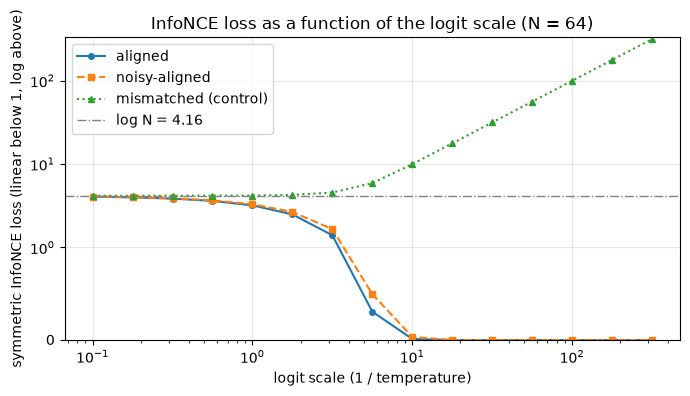

In [ ]:
t.manual_seed(0)
N, d = 64, 32
z_img = F.normalize(t.randn(N, d), dim=-1)
conditions = {
    "aligned": z_img,
    "noisy-aligned": F.normalize(z_img + 0.5 * F.normalize(t.randn(N, d), dim=-1), dim=-1),
    "mismatched (control)": z_img.roll(1, dims=0),
}
scales = np.logspace(-1, 2.5, 15)
curves = {
    name: np.array([clip_loss(similarity_logits(z_img, z_txt, s)).item() for s in scales])
    for name, z_txt in conditions.items()
}
utils.plot_loss_vs_scale(scales, curves, N, "InfoNCE loss as a function of the logit scale (N = 64)")

for s in [1, 10, 100]:
    row = {name: f"{clip_loss(similarity_logits(z_img, z_txt, s)).item():8.3f}" for name, z_txt in conditions.items()}
    print(f"scale {s:>3}: " + "   ".join(f"{name}: {v}" for name, v in row.items()))

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">scale   1: aligned:    3.194   noisy-aligned:    3.294   mismatched (control):    4.190
scale  10: aligned:    0.012   noisy-aligned:    0.034   mismatched (control):    9.969
scale 100: aligned:    0.000   noisy-aligned:    0.000   mismatched (control):   99.566</pre>

</details>

<details>
<summary>Help - how should I interpret this plot?</summary>

**Small scale: everything is stuck near $\log N$.** At a scale of 0.1 the logits are all within $\pm 0.1$ of each other, the softmax is nearly uniform, and every condition has a
loss of about $\log 64 = 4.16$, whether the embeddings are perfect or not. With cosines confined to $[-1, 1]$, a small scale simply can't express confidence: even perfectly aligned
embeddings still have a loss of 3.19 at a scale of 1. This is why the scale (the inverse temperature) is a learned parameter: it controls how sharply the softmax can separate the
right caption from the rest.

**Large scale: the conditions separate completely.** Aligned embeddings go to (almost) zero loss, 0.012 at a scale of 10 and 0.000 at 100, and the noisy-aligned ones follow soon
after (0.034 at scale 10), since the right caption is still the nearest one. The mismatched control does the opposite: its loss *grows* with the scale, to 9.97 at scale 10 and 99.6
at scale 100, which is far *worse* than the $\log N$ of knowing nothing. A wrong pairing of perfectly good embeddings isn't "at chance": a sharp softmax is *confidently wrong*, and
the cross-entropy punishes a confident mistake in proportion to the logit gap.

Two things to take away. First, $\log N$ means "uninformative", but a model can do much worse than uninformative. Second, the scale is what lets the loss tell good embeddings from
bad ones, which is why trained CLIPs end up at high scales: the better the encoders, the more a sharper softmax pays off.
</details>

## The sigmoid loss: SigLIP

SigLIP's loss (Zhai et al., 2023, [*Sigmoid Loss for Language Image Pre-Training*](https://arxiv.org/abs/2303.15343)) throws away the softmax. It treats each of the $N^2$ entries of $S$ as its own binary classification problem, "does this image-caption pair match?", with label $y_{ij} = +1$ on the diagonal and $y_{ij} = -1$ everywhere else, and the probability of a match given by a sigmoid, $P(\text{match}) = \sigma(S_{ij})$:

$$
\mathcal{L}_{\text{SigLIP}} = -\frac{1}{N} \sum_{i=1}^{N} \sum_{j=1}^{N} \log \sigma\!\left(y_{ij}\, S_{ij}\right), \qquad y_{ij} = \begin{cases} +1 & i = j \\ -1 & i \neq j
\end{cases}
$$

(The sum runs over all $N^2$ pairs and is divided by the batch size $N$, as in the paper.) Because $-\log \sigma(x) = \text{softplus}(-x)$, it splits into two terms:

$$
\mathcal{L}_{\text{SigLIP}} = \underbrace{\frac{1}{N} \sum_{i} \text{softplus}(-S_{ii})}_{\text{positive term: pull matches up}} \;+\; \underbrace{\frac{1}{N} \sum_{i \neq j}
\text{softplus}(S_{ij})}_{\text{negative term: push non-matches down}}
$$

There are three differences from InfoNCE which we'll look at in turn. **First**, there's no normalisation across a row, so each pair is judged on its own: a pair's loss doesn't
depend on what the other $N - 1$ captions look like. This also removes the need for a global view of the batch (you no longer need to gather all the logits on one device to compute
a softmax), which is the efficiency argument of the paper. **Second**, there's a **bias** $b$, which we'll see is essential. **Third**, it's heavily *imbalanced*: there are $N$
positives and $N^2 - N$ negatives in each batch, so with a batch of 1,000 pairs, 99.9% of the terms are negatives.

### Exercise - implement `siglip_loss_terms`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement `siglip_loss_terms`, which takes the `(N, N)` logit matrix (scale and bias already applied, matches on the diagonal) and returns the two terms above as a pair
`(positive_term, negative_term)` of scalar tensors, each already divided by $N$. The full loss is their sum, and we've written `siglip_loss` for you below.

Use `F.softplus` or `F.logsigmoid` rather than writing `log(1 + exp(x))` yourself: for the large logits we'll meet (like $-10$ or $+100$), the naive version overflows or loses all
precision.

In [ ]:
def siglip_loss_terms(logits: Float[Tensor, "n n"]) -> tuple[Float[Tensor, ""], Float[Tensor, ""]]:
    """Returns (positive_term, negative_term) of the sigmoid loss, each divided by the batch size N."""
    raise NotImplementedError()


def siglip_loss(logits: Float[Tensor, "n n"]) -> Float[Tensor, ""]:
    """The pairwise sigmoid loss: positive term plus negative term."""
    positive_term, negative_term = siglip_loss_terms(logits)
    return positive_term + negative_term


tests.test_siglip_loss_terms(siglip_loss_terms)

<details>
<summary>Hint</summary>

`logits[eye]` with a boolean identity mask gives the diagonal; `logits[~eye]` gives all the off-diagonal entries. The positive term is `softplus(-diagonal)` summed, the negative
term is `softplus(off_diagonal)` summed, and both are divided by $N$.
</details>


<details><summary>Solution</summary>

```python
def siglip_loss_terms(logits: Float[Tensor, "n n"]) -> tuple[Float[Tensor, ""], Float[Tensor, ""]]:
    """Returns (positive_term, negative_term) of the sigmoid loss, each divided by the batch size N."""
    n = logits.shape[0]
    eye = t.eye(n, dtype=t.bool, device=logits.device)
    positive_term = F.softplus(-logits[eye]).sum() / n
    negative_term = F.softplus(logits[~eye]).sum() / n
    return positive_term, negative_term


def siglip_loss(logits: Float[Tensor, "n n"]) -> Float[Tensor, ""]:
    """The pairwise sigmoid loss: positive term plus negative term."""
    positive_term, negative_term = siglip_loss_terms(logits)
    return positive_term + negative_term
```
</details>

## Why does SigLIP need a bias? Initialisation

Let's look at the sigmoid loss at **initialisation**, when the embeddings are essentially random and so all the cosines are about zero, meaning $S_{ij} \approx b$ for every pair.
Then every pair has the same logit, and the two terms are

$$
\mathcal{L}_{pos} \approx \text{softplus}(-b), \qquad \mathcal{L}_{neg} \approx (N - 1)\,\text{softplus}(b).
$$

With $b = 0$ this is $\log 2 \approx 0.69$ for the positives but $(N-1)\log 2$ for the negatives: the negative term grows *linearly* with the batch size and swamps the positives.
The first thing a model would learn is "everything is a non-match", which is a very poor start. The SigLIP paper's fix is to initialise the bias at $b = -10$ (and the logit scale
at $s = 10$): then $\text{softplus}(b)$ is tiny and the many negatives start off already "correct", while the few positives start with a large loss and dominate the gradient.

Let's check this with your function, for random embeddings and a sweep of batch sizes, comparing the paper's initialisation against a CLIP-style one ($s = 1/0.07 \approx 14.3$, $b
= 0$).


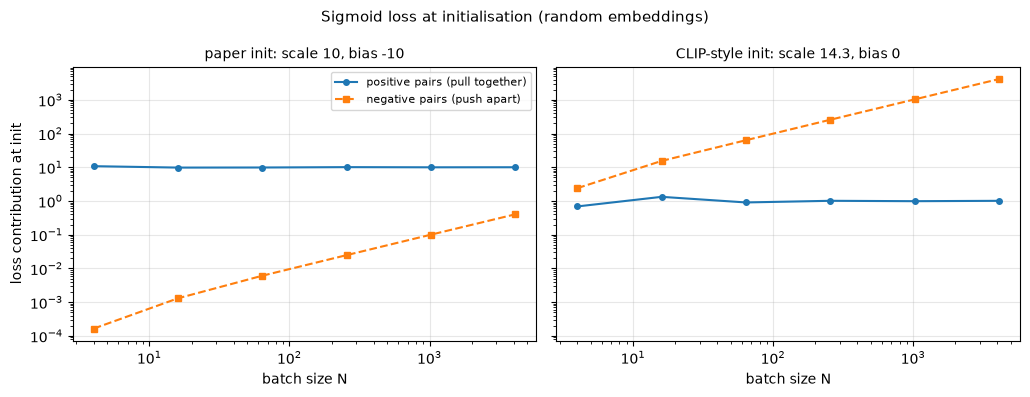

In [ ]:
t.manual_seed(0)
batch_sizes = [4, 16, 64, 256, 1024, 4096]
inits = {"paper init: scale 10, bias -10": (10.0, -10.0), "CLIP-style init: scale 14.3, bias 0": (1 / 0.07, 0.0)}
terms = {}
for name, (scale, bias) in inits.items():
    pos, neg = [], []
    for n in batch_sizes:
        z = F.normalize(t.randn(n, 64), dim=-1), F.normalize(t.randn(n, 64), dim=-1)
        p, q = siglip_loss_terms(similarity_logits(*z, scale, bias))
        pos.append(p.item())
        neg.append(q.item())
    terms[name] = (pos, neg)
    print(f"{name}\n  positive term: " + ", ".join(f"{v:.3g}" for v in pos) + "\n  negative term: " + ", ".join(f"{v:.3g}" for v in neg))
utils.plot_siglip_init_terms(batch_sizes, terms, "Sigmoid loss at initialisation (random embeddings)")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">paper init: scale 10, bias -10
  positive term: 10.8, 9.78, 9.84, 10.1, 9.97, 10
  negative term: 0.000165, 0.0013, 0.00608, 0.0248, 0.1, 0.403
CLIP-style init: scale 14.3, bias 0
  positive term: 0.689, 1.33, 0.905, 1.01, 0.987, 1.01
  negative term: 2.4, 15.4, 63.4, 256, 1.03e+03, 4.12e+03</pre>

</details>

<details>
<summary>Help - how should I interpret this plot?</summary>

**Paper initialisation (left).** The positive term is about 10 at every batch size: each of the $N$ positives has $\text{softplus}(10) \approx 10$, and we divide by $N$. The
negative term is tiny and grows linearly with $N$, from 0.0002 at $N=4$ to 0.4 at $N=4096$. So for any batch size we could try here the loss at initialisation is dominated by the
positives, which is what we want: the gradient says "pull the matching pairs together" and barely mentions the negatives. (The two terms would cross at $N \approx 2 \times 10^5$.)

**CLIP-style initialisation (right).** The positive term is about 1, but the negative term grows from 2.4 at $N=4$ to 4,120 at $N=4096$: four thousand times larger. The first
updates would be spent pushing *all* pairs apart (lowering every logit), and the gradient on the $N$ positives is a rounding error next to the gradient on the $N^2 - N$ negatives.
The model can recover, but it starts from the "everything is a non-match" solution. In Part 2 we'll measure how much that costs.
</details>

## Gradients: what each loss pushes on

The two losses can behave very differently even when they agree on what a "good" solution looks like, and the difference is clearest in the gradient with respect to the logits
$S_{ij}$.

For the sigmoid loss, each pair is an independent binary cross-entropy, and the gradient of $-\log\sigma(y z)$ with respect to $z$ is $\sigma(z) - \mathbb{1}[y = +1]$. So

$$
\frac{\partial \mathcal{L}_{\text{SigLIP}}}{\partial S_{ij}} = \frac{1}{N}\left(\sigma(S_{ij}) - \delta_{ij}\right).
$$

For InfoNCE, take the image-to-text half. The gradient of a row's cross-entropy with respect to its logits is the familiar "softmax minus one-hot", $p_{ij} - \delta_{ij}$, where
$p_{ij} = \text{softmax}_j(S_{i\cdot})$. The text-to-image half contributes the same with the *column* softmax $q_{ij} = \text{softmax}_i(S_{\cdot j})$, so for the symmetric loss

$$
\frac{\partial \mathcal{L}_{\text{CLIP}}}{\partial S_{ij}} = \frac{1}{2N}\left(p_{ij} + q_{ij} - 2\,\delta_{ij}\right).
$$

Because the same logits $S_{ij}$ also feed the other loss's gradient, you can check your formulas against PyTorch's autograd, which is what the tests do.

### Exercise - implement both gradients by hand

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement `clip_loss_grad` and `siglip_loss_grad`, each of which takes the `(N, N)` logit matrix and returns the `(N, N)` matrix of $\partial \mathcal{L} / \partial S_{ij}$ using
the formulas above, *without* calling `.backward()`. The test compares both against autograd applied to your `clip_loss` and `siglip_loss`.

In [ ]:
def clip_loss_grad(logits: Float[Tensor, "n n"]) -> Float[Tensor, "n n"]:
    """Gradient of `clip_loss` with respect to the logit matrix, computed by hand."""
    raise NotImplementedError()


def siglip_loss_grad(logits: Float[Tensor, "n n"]) -> Float[Tensor, "n n"]:
    """Gradient of `siglip_loss` with respect to the logit matrix, computed by hand."""
    raise NotImplementedError()


tests.test_loss_gradients(clip_loss_grad, siglip_loss_grad, clip_loss, siglip_loss)

<details>
<summary>Hint</summary>

`logits.softmax(dim=1)` normalises each row and `logits.softmax(dim=0)` normalises each column. The identity matrix is `t.eye(n, device=logits.device)`. Don't forget the
$\frac{1}{2N}$ for CLIP and the $\frac{1}{N}$ for SigLIP.
</details>


<details><summary>Solution</summary>

```python
def clip_loss_grad(logits: Float[Tensor, "n n"]) -> Float[Tensor, "n n"]:
    """Gradient of `clip_loss` with respect to the logit matrix, computed by hand."""
    n = logits.shape[0]
    row_softmax = logits.softmax(dim=1)
    column_softmax = logits.softmax(dim=0)
    return (row_softmax + column_softmax - 2 * t.eye(n, device=logits.device)) / (2 * n)


def siglip_loss_grad(logits: Float[Tensor, "n n"]) -> Float[Tensor, "n n"]:
    """Gradient of `siglip_loss` with respect to the logit matrix, computed by hand."""
    n = logits.shape[0]
    return (logits.sigmoid() - t.eye(n, device=logits.device)) / n
```
</details>

Now let's use the gradients to find a deep difference between the two losses. Shift every logit in a batch by the same constant, $S \to S + c$, and look at the loss and the total
gradient.

In [ ]:
t.manual_seed(1)
logits = 3 * F.normalize(t.randn(8, 16), dim=-1) @ F.normalize(t.randn(8, 16), dim=-1).T
for shift in [0.0, 5.0, -5.0]:
    shifted = logits + shift
    print(
        f"shift {shift:+.0f}:  CLIP loss {clip_loss(shifted).item():.4f}  (sum of gradient entries {clip_loss_grad(shifted).sum().item():+.1e})"
        f"   SigLIP loss {siglip_loss(shifted).item():.4f}  (sum of gradient entries {siglip_loss_grad(shifted).sum().item():+.4f})"
    )

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">shift +0:  CLIP loss 2.4281  (sum of gradient entries -5.6e-09)   SigLIP loss 6.0125  (sum of gradient entries +2.8507)
shift +5:  CLIP loss 2.4281  (sum of gradient entries -5.6e-09)   SigLIP loss 34.5036  (sum of gradient entries +6.9180)
shift -5:  CLIP loss 2.4281  (sum of gradient entries -1.5e-08)   SigLIP loss 5.1575  (sum of gradient entries -0.9291)</pre>

</details>

<details>
<summary>Question - why is the CLIP loss unchanged by the shift, and why does that mean SigLIP needs a bias?</summary>

**CLIP.** Every softmax depends only on *differences* between the entries of a row: $\text{softmax}(S_{i\cdot} + c) = \text{softmax}(S_{i\cdot})$. So adding a constant to every
logit changes nothing, not the loss (2.4281 in all three rows) and not the gradient, whose entries sum to zero (up to $10^{-8}$) however you shift. The loss is perfectly flat along
the direction "add the same number everywhere", and a bias term would have nothing to do: it would be unidentifiable.

**SigLIP.** Each logit is judged on its *absolute* value, since $\sigma(S_{ij})$ is a probability. Shifting by $+5$ turns a loss of 6.0 into 34.5 (every negative now looks like a
likely match) and shifting by $-5$ makes it 5.2. The sum of the gradient entries isn't zero, and changes sign with the shift: at $+5$ the loss wants every logit lower (+6.9), at
$-5$ it wants them higher ($-0.93$). So there's a best global offset, and the bias $b$ is the learnable parameter that finds it. That absolute parameterization gives a
model-assigned pairwise match probability, unlike a softmax over candidates. Whether it estimates actual match frequencies is a separate calibration question; Part 3 compares the
readouts without measuring calibration.
</details>

## False negatives: when two captions in a batch are the same

Both losses assume that every off-diagonal pair is a genuine *non*-match. On web data that's nearly true: two random images almost never have the same caption. But it's easy to
break it. If your dataset has 100 distinct captions and you draw a batch of 64 with replacement, then two images in the batch will often share a caption, and the pair (image $i$,
caption $j$) is labelled as a negative even though caption $j$ describes image $i$ perfectly. These are **false negatives**. They put a floor under the loss (no model can
distinguish two identical captions) and, worse, they teach the model to push apart things that mean the same thing.

CLIP's data pipeline filtered and deduplicated for this reason. We'll need to deal with it ourselves in Part 2, since our toy world has far fewer distinct captions than the
internet. First, a measurement.

### Exercise - measure the false-negative rate

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Implement `false_negative_fraction`, which takes the caption ids of a batch (shape `(N,)`, one integer per caption, identical text means identical id) and returns the fraction of
items $i$ for which *at least one other* item $j \neq i$ in the batch has the same caption, i.e. the fraction of rows of the logit matrix that contain a false negative.

In [ ]:
def false_negative_fraction(caption_ids: Int[Tensor, " n"]) -> float:
    """Fraction of items in the batch whose caption is shared by at least one other item in the batch."""
    raise NotImplementedError()


tests.test_false_negative_fraction(false_negative_fraction)

<details>
<summary>Hint</summary>

Compare every id with every other id using broadcasting: `ids[:, None] == ids[None, :]` is an `(N, N)` boolean matrix. Remove the diagonal (every item matches itself), then ask
which rows still contain a `True`.
</details>


<details><summary>Solution</summary>

```python
def false_negative_fraction(caption_ids: Int[Tensor, " n"]) -> float:
    """Fraction of items in the batch whose caption is shared by at least one other item in the batch."""
    same = caption_ids[:, None] == caption_ids[None, :]
    same = same & ~t.eye(len(caption_ids), dtype=t.bool, device=caption_ids.device)
    return same.any(dim=1).float().mean().item()
```
</details>

In [ ]:
generator = t.Generator().manual_seed(0)
for n_distinct in [100, 1000, 100_000]:
    rates = [false_negative_fraction(t.randint(0, n_distinct, (64,), generator=generator)) for _ in range(500)]
    print(f"batch of 64 drawn with replacement from {n_distinct:>7,} distinct captions: {np.mean(rates):6.1%} of rows have a false negative")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">batch of 64 drawn with replacement from     100 distinct captions:  47.1% of rows have a false negative
batch of 64 drawn with replacement from   1,000 distinct captions:   6.3% of rows have a false negative
batch of 64 drawn with replacement from 100,000 distinct captions:   0.1% of rows have a false negative</pre>

</details>

With 100 distinct captions, about half of all rows are contaminated, but with a realistically large caption space the problem all but disappears. In Part 2 we'll avoid it by
construction.

## Summary of 1️⃣

- Both losses act on one `(N, N)` matrix of scaled cosine similarities with the matching pairs on the diagonal. InfoNCE (CLIP) turns each row and column into a softmax classification problem; the sigmoid loss (SigLIP) turns each entry into an independent binary classification.
- Softmax losses are **shift-invariant**: adding a constant to all logits changes nothing, because only differences within a row matter. The sigmoid loss isn't, since it cares about the *absolute* value of each logit. That's why SigLIP carries a learnable bias, and why its output parameterizes an independent match probability. This does not establish empirical calibration.
- With $N$ positives and $N^2 - N$ negatives, the sigmoid loss is badly imbalanced at initialisation. The negative term grows linearly with the batch size unless the bias starts very negative: the paper's $b = -10$ gives the positives a large loss and the negatives almost none.
- Everything above assumes that off-diagonal pairs really are non-matches. In a small dataset with repeated captions that's false for a large fraction of rows, so we'll sample batches with no repeated captions.

Now we know what the losses do on hand-built embeddings. Let's find out whether they can train an image encoder and a text encoder from scratch.

# 2️⃣ A Tiny CLIP from Scratch

> ##### Learning Objectives
>
> - Implement a patch embedding, multi-head self-attention (causal and bidirectional), end-of-text pooling and a dual encoder
> - Write the contrastive training loop, including the learnable temperature and its clamp
> - Evaluate with image-to-text and text-to-image retrieval, on seen and held-out combinations
> - Use two different "random caption" controls (one that must fail, one that teaches you something), and an untrained baseline
> - Compare the softmax and sigmoid losses at equal budget, and test what the SigLIP bias initialisation is doing

## A world of coloured shapes

To train a CLIP in a few minutes, we need a world which is small enough for a tiny model but still has *structure* to learn: attributes that combine, so that we can ask whether the
model has learned them separately or only memorised whole pictures. We'll use 32×32 images, each showing one coloured shape in one quadrant:

| attribute | values | count |
|---|---|---|
| colour | red, green, blue, yellow, purple, orange | 6 |
| shape | circle, square, triangle, star, heart | 5 |
| position | top left, top right, bottom left, bottom right | 4 |

That's $6 \times 5 \times 4 = 120$ **classes**, and each class has exactly one caption, such as `"a green star in the top left"`. Within a class, images vary: the shape's size,
exact position, shade of colour, the background brightness, and pixel noise are all randomised.

The one design decision that matters is a **held-out set**. We choose six (colour, shape) *combinations*, for instance `green star` and `blue triangle`, and never show the model
any image or caption containing them, in any position. Every colour and every shape still appears in other combinations, so a model which has learned "green" and "star" as separate
concepts could in principle recognise a green star on first sight. A model which has memorised 96 pictures can't. Out of the 120 classes, 96 are for training and 24 are held out.

In [ ]:
COLOURS = list(utils.COLOUR_RGB)
SHAPES = ["circle", "square", "triangle", "star", "heart"]
POSITIONS = list(utils.QUADRANT_CENTRES)
CLASSES = list(itertools.product(COLOURS, SHAPES, POSITIONS))  # (colour, shape, position); the class index is the list index
HELD_OUT_COMBOS = {("red", "heart"), ("green", "star"), ("blue", "triangle"), ("yellow", "circle"), ("purple", "square"), ("orange", "heart")}


def caption_of(cls: tuple[str, str, str]) -> str:
    colour, shape, position = cls
    return f"a {colour} {shape} in the {position}"


CAPTIONS = [caption_of(cls) for cls in CLASSES]
held_out_mask = t.tensor([(colour, shape) in HELD_OUT_COMBOS for colour, shape, _ in CLASSES])
train_classes = (~held_out_mask).nonzero().squeeze(-1)  # 96 classes


def render_world(n_variants: int, seed: int) -> Float[Tensor, "variant class 3 32 32"]:
    """Render `n_variants` random images of every class, as float tensors in [0, 1]."""
    rng = np.random.default_rng(seed)
    images = np.stack(
        [[utils.render_tiny(shape, colour, position, rng) for colour, shape, position in CLASSES] for _ in range(n_variants)]
    )
    return t.tensor(images).permute(0, 1, 4, 2, 3).float() / 255


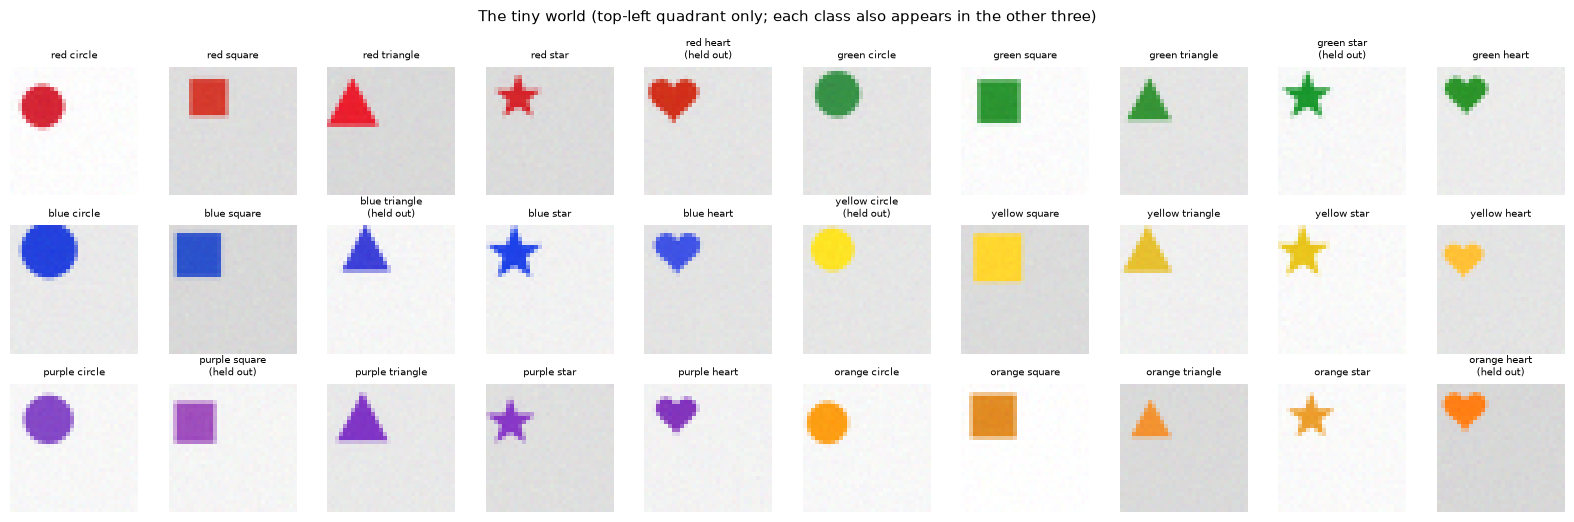

In [ ]:
train_images = render_world(24, seed=0).to(device)  # 24 random images of each of the 120 classes (the 24 held-out classes are never sampled)
test_images = render_world(1, seed=1)[0].to(device)  # one fresh image per class, for evaluation
print(f"{len(CLASSES)} classes, {len(train_classes)} for training, {int(held_out_mask.sum())} held out")
print(f"train_images: {tuple(train_images.shape)}, test_images: {tuple(test_images.shape)}")
print(f"example caption: {CAPTIONS[0]!r}")

# one image per (colour, shape) combination, all in the top-left quadrant
top_left = [i for i, (_, _, position) in enumerate(CLASSES) if position == "top left"]
utils.show_image_grid(
    (test_images[top_left].permute(0, 2, 3, 1).cpu().numpy() * 255).astype(np.uint8),
    [f"{CLASSES[i][0]} {CLASSES[i][1]}" + ("\n(held out)" if held_out_mask[i] else "") for i in top_left],
    ncols=10,
    title="The tiny world (top-left quadrant only; each class also appears in the other three)",
)

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">120 classes, 96 for training, 24 held out
train_images: (24, 120, 3, 32, 32), test_images: (120, 3, 32, 32)
example caption: 'a red circle in the top left'</pre>

</details>

## Tokenising captions

Real CLIP uses a byte-pair encoding with a 49,408-token vocabulary. Ours has 25 words, so a word-level vocabulary will do. Every caption becomes a sequence of ids with the same
structure as CLIP's:

```
<bos>  a  green  star  in  the  top  left  <eos>  <pad>
```

There's a beginning-of-text token, the words, an end-of-text token, and padding up to a fixed length. The `<eos>` token matters: CLIP's text tower reads out its sentence embedding
from the hidden state *at the EOS position*, as we'll see. Our vocabulary also contains the word `and`, which we'll need in Part 4 for captions about two objects.

### Exercise - implement `tokenize_captions`

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Implement `tokenize_captions`. It takes a list of captions, the vocabulary (a list of words, whose index is the id), and `max_len`, and returns a `(n_captions, max_len)` tensor of
ids: `<bos>`, then the id of each whitespace-separated word, then `<eos>`, then `<pad>` up to `max_len`. The three special tokens have ids 0 (`<pad>`), 1 (`<bos>`) and 2 (`<eos>`)
in our vocabulary. An unknown word should raise a `KeyError` rather than being silently dropped.

In [ ]:
VOCAB = ["<pad>", "<bos>", "<eos>", "a", "in", "the", "and"] + COLOURS + SHAPES + ["top", "bottom", "left", "right"]
PAD_ID, BOS_ID, EOS_ID = 0, 1, 2
MAX_LEN = 10


def tokenize_captions(captions: list[str], vocab: list[str], max_len: int) -> Int[Tensor, "n max_len"]:
    """<bos> + word ids + <eos>, right-padded with <pad> (id 0) to max_len."""
    raise NotImplementedError()


tests.test_tokenize_captions(tokenize_captions, VOCAB, MAX_LEN)

<details>
<summary>Hint</summary>

Build a dictionary `{word: id}` from the vocabulary list, start from a `(n, max_len)` tensor filled with the pad id, and write each caption's ids into the start of its row.
</details>


<details><summary>Solution</summary>

```python
VOCAB = ["<pad>", "<bos>", "<eos>", "a", "in", "the", "and"] + COLOURS + SHAPES + ["top", "bottom", "left", "right"]
PAD_ID, BOS_ID, EOS_ID = 0, 1, 2
MAX_LEN = 10


def tokenize_captions(captions: list[str], vocab: list[str], max_len: int) -> Int[Tensor, "n max_len"]:
    """<bos> + word ids + <eos>, right-padded with <pad> (id 0) to max_len."""
    word_to_id = {word: i for i, word in enumerate(vocab)}
    ids = t.full((len(captions), max_len), PAD_ID, dtype=t.long)
    for row, caption in enumerate(captions):
        tokens = [BOS_ID] + [word_to_id[word] for word in caption.split()] + [EOS_ID]
        ids[row, : len(tokens)] = t.tensor(tokens)
    return ids
```
</details>

In [ ]:
CAPTION_IDS = tokenize_captions(CAPTIONS, VOCAB, MAX_LEN).to(device)
print(CAPTIONS[0], "->", CAPTION_IDS[0].tolist())
print(" ".join(VOCAB[i] for i in CAPTION_IDS[0].tolist()))

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">a red circle in the top left -&gt; [1, 3, 7, 13, 4, 5, 18, 20, 2, 0]
&lt;bos&gt; a red circle in the top left &lt;eos&gt; &lt;pad&gt;</pre>

</details>

## Sampling batches without false negatives

In Part 1 we saw that a batch drawn with replacement from a small caption set is full of false negatives. Our world has only 96 training captions, so the fix is to sample the
batch's *classes* without replacement: a batch of 64 contains 64 *different* captions, each paired with a randomly chosen image of that class. Then no off-diagonal pair is a false
negative.

### Exercise - implement `sample_batch`

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Implement `sample_batch`. It takes the rendered images (shape `(variant, class, 3, 32, 32)`), the 1D tensor of class indices that may be used (`train_classes`), a batch size, and a
CPU `t.Generator`. It returns `(images, class_ids)`: `class_ids` is `batch_size` **distinct** classes chosen at random from the allowed ones, and `images[b]` is a randomly chosen
variant of class `class_ids[b]`. Use the generator for *all* randomness, so that runs are reproducible, and put `class_ids` on the same device as the images.

In [ ]:
def sample_batch(
    images: Float[Tensor, "variant class 3 32 32"],
    allowed_classes: Int[Tensor, " n_allowed"],
    batch_size: int,
    generator: t.Generator,
) -> tuple[Float[Tensor, "batch 3 32 32"], Int[Tensor, " batch"]]:
    """A batch of `batch_size` images of distinct, randomly chosen classes (and their class indices)."""
    raise NotImplementedError()


tests.test_sample_batch(sample_batch)

<details>
<summary>Hint</summary>

`t.randperm(n, generator=generator)[:batch_size]` picks `batch_size` distinct indices into `allowed_classes`. A second call with `t.randint(0, n_variants, (batch_size,),
generator=generator)` picks the variants, and `images[variants, class_ids]` gathers one image per (variant, class) pair. Generators on the CPU produce CPU tensors, so move indices
to the images' device before indexing.
</details>


<details><summary>Solution</summary>

```python
def sample_batch(
    images: Float[Tensor, "variant class 3 32 32"],
    allowed_classes: Int[Tensor, " n_allowed"],
    batch_size: int,
    generator: t.Generator,
) -> tuple[Float[Tensor, "batch 3 32 32"], Int[Tensor, " batch"]]:
    """A batch of `batch_size` images of distinct, randomly chosen classes (and their class indices)."""
    chosen = allowed_classes[t.randperm(len(allowed_classes), generator=generator)[:batch_size]]
    variants = t.randint(0, images.shape[0], (batch_size,), generator=generator)
    class_ids = chosen.to(images.device)
    return images[variants.to(images.device), class_ids], class_ids
```
</details>

In [ ]:
generator = t.Generator().manual_seed(0)
iid = [false_negative_fraction(train_classes[t.randint(0, len(train_classes), (64,), generator=generator)]) for _ in range(200)]
unique = [false_negative_fraction(sample_batch(train_images, train_classes, 64, generator)[1]) for _ in range(200)]
print(f"false-negative rows, batch of 64, classes drawn with replacement: {np.mean(iid):.1%}")
print(f"false-negative rows, batch of 64, `sample_batch`:                 {np.mean(unique):.1%}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">false-negative rows, batch of 64, classes drawn with replacement: 48.1%
false-negative rows, batch of 64, `sample_batch`:                 0.0%</pre>

</details>

## The architecture

CLIP's architecture is two transformers and two linear maps. Ours is the same, only smaller (width 64, two layers, four heads each):

```
image  (3×32×32) ─ patchify ─► 16 patches ─ Linear ─► tokens ─ [CLS] + pos ─► ViT blocks ─ LN ─► [CLS] ─ Linear ─► u ┐
                                                                                                                   ├─ normalise ─► scale · û·v̂ ─► loss
caption (ids) ─ token emb + pos ─► *causal* blocks ─ LN ─► hidden state at <eos> ─ Linear ─► v ───────────────────────┘
```

Both towers use the same pre-layernorm transformer block; they differ in three ways.

1. **The image tower is a Vision Transformer** (Dosovitskiy et al., 2021). The image is cut into non-overlapping $p \times p$ patches, each patch is flattened
   and linearly embedded as one token, a learned `[CLS]` token is prepended, learned position embeddings are added, and the sequence goes through bidirectional
   blocks. The final `[CLS]` hidden state is the image's summary. Our 32×32 images with $p=8$ give 16 patches, and 17 tokens with the `[CLS]`. The real CLIP
   ViT-B/32 uses $p=32$ on 224×224 images, which gives 49 patches.
2. **The text tower is a causal transformer**, with the same attention mask as GPT-2. Its summary of the whole caption is the hidden state at the `<eos>` token, which is the one position that has attended to every word.
3. **Linear projections** map each tower's width to the shared embedding dimension.

The pieces you'll write: `patchify` (the one genuinely new piece of image plumbing), self-attention with an optional causal mask, the two forward passes, and the dual encoder that
ties them to your loss from Part 1.

### Exercise - implement `patchify`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement `patchify`. It takes a batch of images of shape `(batch, 3, H, W)` and a patch size $p$ (which divides $H$ and $W$) and returns `(batch, (H/p) * (W/p), 3 * p * p)`. The
patches should be ordered row-major (left to right, then top to bottom), and each patch is flattened in `(channel, row, column)` order. In other words, the result should be the
same as `F.unfold(images, p, stride=p).transpose(1, 2)`, and that's what the test compares it against. Write it with `reshape` and `permute` (or `einops.rearrange`) so that you can
see what's happening.

In [ ]:
def patchify(images: Float[Tensor, "batch channel height width"], patch_size: int) -> Float[Tensor, "batch n_patches patch_dim"]:
    """Cut images into non-overlapping patches and flatten each one: (B, C, H, W) -> (B, (H/p)*(W/p), C*p*p)."""
    raise NotImplementedError()


tests.test_patchify(patchify)

<details>
<summary>Hint</summary>

Reshape `(B, C, H, W)` into `(B, C, H/p, p, W/p, p)`, so that each spatial axis is split into "which patch" and "where inside the patch". Then permute to put the two "which patch"
axes (`H/p`, `W/p`) next to each other after the batch, followed by the channel and the two within-patch axes, and finally reshape to merge them: `(B, H/p * W/p, C * p * p)`.
</details>

<details>
<summary>Help - my test fails with right shapes but wrong values.</summary>

The usual mistake is the order of the last three axes. After the permutation, the order must be `(batch, patch_row, patch_col, channel, row_in_patch, col_in_patch)`: the flattened
patch is `channel`-major. If you put the channel axis last, each patch is flattened as `(row, col, channel)`, which is a different (equally valid, but not matching the test)
layout.
</details>


<details><summary>Solution</summary>

```python
def patchify(images: Float[Tensor, "batch channel height width"], patch_size: int) -> Float[Tensor, "batch n_patches patch_dim"]:
    """Cut images into non-overlapping patches and flatten each one: (B, C, H, W) -> (B, (H/p)*(W/p), C*p*p)."""
    b, c, h, w = images.shape
    p = patch_size
    patches = images.reshape(b, c, h // p, p, w // p, p)  # split each spatial axis into (patch index, offset within patch)
    patches = patches.permute(0, 2, 4, 1, 3, 5)  # (batch, patch row, patch col, channel, row in patch, col in patch)
    return patches.reshape(b, (h // p) * (w // p), c * p * p)
```
</details>

### Exercise - implement multi-head self-attention

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

You've implemented attention in [1.1]; here it is again with one extra option. Complete the `forward` method of `SelfAttention`. The layer has one linear map `qkv` that produces
queries, keys and values together, and one output projection `out`:

1. `self.qkv(x)` has shape `(batch, seq, 3 * d_model)`. Reshape it to `(batch, seq, 3, n_heads, head_dim)` and split off $Q$, $K$, $V$ (the factor 3 is the *slowest* of the last three axes), each of shape `(batch, n_heads, seq, head_dim)` after moving the head axis forward.
2. The attention scores are $QK^T / \sqrt{\text{head\_dim}}$ per head. If `self.causal`, position $i$ may only attend to positions $j \leq i$: set the scores for $j > i$ to $-\infty$ before the softmax.
3. Multiply the softmaxed scores by $V$, merge the heads back into `d_model`, and apply `self.out`.

The test compares your output with `F.scaled_dot_product_attention` computed from the same weights.

In [ ]:
class SelfAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int, causal: bool):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads, self.causal = n_heads, causal
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.out = nn.Linear(d_model, d_model)

    def forward(self, x: Float[Tensor, "batch seq d_model"]) -> Float[Tensor, "batch seq d_model"]:
        raise NotImplementedError()


tests.test_self_attention(SelfAttention)

<details>
<summary>Hint</summary>

After `reshape(batch, seq, 3, n_heads, head_dim)`, calling `.permute(2, 0, 3, 1, 4)` gives a tensor of shape `(3, batch, n_heads, seq, head_dim)` which you can unpack into `q, k,
v`. For the mask, `t.ones(seq, seq, dtype=t.bool).triu(diagonal=1)` is `True` exactly where $j > i$, so `scores.masked_fill(mask, float("-inf"))` blanks out the future. To merge
heads at the end, `transpose(1, 2)` brings `seq` before `n_heads`, and a reshape merges the last two axes.
</details>


<details><summary>Solution</summary>

```python
class SelfAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int, causal: bool):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads, self.causal = n_heads, causal
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.out = nn.Linear(d_model, d_model)

    def forward(self, x: Float[Tensor, "batch seq d_model"]) -> Float[Tensor, "batch seq d_model"]:
        batch, seq, d_model = x.shape
        head_dim = d_model // self.n_heads
        qkv = self.qkv(x).reshape(batch, seq, 3, self.n_heads, head_dim)
        q, k, v = qkv.permute(2, 0, 3, 1, 4)  # each: (batch, n_heads, seq, head_dim)
        scores = q @ k.transpose(-1, -2) / math.sqrt(head_dim)
        if self.causal:
            future = t.ones(seq, seq, dtype=t.bool, device=x.device).triu(diagonal=1)
            scores = scores.masked_fill(future, float("-inf"))
        mixed = scores.softmax(dim=-1) @ v  # (batch, n_heads, seq, head_dim)
        return self.out(mixed.transpose(1, 2).reshape(batch, seq, d_model))
```
</details>

The transformer block itself is standard (a pre-layernorm residual attention layer followed by a residual MLP with a 4× hidden layer), so we've written it for you:

In [ ]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model: int, n_heads: int, causal: bool):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = SelfAttention(d_model, n_heads, causal)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(), nn.Linear(4 * d_model, d_model))

    def forward(self, x: Float[Tensor, "batch seq d_model"]) -> Float[Tensor, "batch seq d_model"]:
        x = x + self.attn(self.ln1(x))
        return x + self.mlp(self.ln2(x))

### Exercise - implement the text encoder

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Complete `TextEncoder.forward`. It takes token ids `(batch, seq)` and should:

1. sum the token embeddings and the (learned) position embeddings for the first `seq` positions,
2. run the blocks (which are causal),
3. apply `ln_final`,
4. return, for each caption, the hidden state **at its `<eos>` position**, shape `(batch, d_model)`.

Every caption has exactly one `<eos>` token (id 2). Because the attention is causal, the hidden state at `<eos>` depends only on the tokens up to and including it, so whatever
padding follows has no influence. The test uses exactly that fact: encoding a caption with padding must give the same vector as encoding it without.

In [ ]:
class TextEncoder(nn.Module):
    def __init__(self, vocab_size: int, d_model: int, n_layers: int, n_heads: int, max_len: int):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, d_model)
        self.pos_embedding = nn.Parameter(0.02 * t.randn(max_len, d_model))
        self.blocks = nn.ModuleList([TransformerBlock(d_model, n_heads, causal=True) for _ in range(n_layers)])
        self.ln_final = nn.LayerNorm(d_model)

    def forward(self, ids: Int[Tensor, "batch seq"]) -> Float[Tensor, "batch d_model"]:
        raise NotImplementedError()


tests.test_text_encoder(TextEncoder, EOS_ID)

<details>
<summary>Hint</summary>

`(ids == EOS_ID).int().argmax(dim=-1)` finds the position of the `<eos>` in each row (there's exactly one `True` per row, and `argmax` returns its index). Then `x[t.arange(batch),
positions]` picks one vector per row.
</details>


<details><summary>Solution</summary>

```python
class TextEncoder(nn.Module):
    def __init__(self, vocab_size: int, d_model: int, n_layers: int, n_heads: int, max_len: int):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, d_model)
        self.pos_embedding = nn.Parameter(0.02 * t.randn(max_len, d_model))
        self.blocks = nn.ModuleList([TransformerBlock(d_model, n_heads, causal=True) for _ in range(n_layers)])
        self.ln_final = nn.LayerNorm(d_model)

    def forward(self, ids: Int[Tensor, "batch seq"]) -> Float[Tensor, "batch d_model"]:
        x = self.token_embedding(ids) + self.pos_embedding[: ids.shape[1]]
        for block in self.blocks:
            x = block(x)
        x = self.ln_final(x)
        eos_position = (ids == EOS_ID).int().argmax(dim=-1)  # position of the (only) <eos> in each caption
        return x[t.arange(len(ids), device=ids.device), eos_position]
```
</details>

### Exercise - implement the image encoder

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Complete `ImageEncoder.forward`. It takes images `(batch, 3, 32, 32)` and should:

1. cut them into patches with your `patchify` and embed each with `patch_embed`,
2. prepend the learned `cls_token` (shape `(1, 1, d_model)`, expand it over the batch),
3. add `pos_embedding` (shape `(1, n_patches + 1, d_model)`),
4. run the (bidirectional) blocks and apply `ln_final`,
5. return the hidden state of the `[CLS]` token, shape `(batch, d_model)`.

In [ ]:
class ImageEncoder(nn.Module):
    def __init__(self, d_model: int, n_layers: int, n_heads: int, image_size: int = 32, patch_size: int = 8):
        super().__init__()
        self.patch_size = patch_size
        n_patches = (image_size // patch_size) ** 2
        self.patch_embed = nn.Linear(3 * patch_size**2, d_model)
        self.cls_token = nn.Parameter(t.zeros(1, 1, d_model))
        self.pos_embedding = nn.Parameter(0.02 * t.randn(1, n_patches + 1, d_model))
        self.blocks = nn.ModuleList([TransformerBlock(d_model, n_heads, causal=False) for _ in range(n_layers)])
        self.ln_final = nn.LayerNorm(d_model)

    def forward(self, images: Float[Tensor, "batch 3 height width"]) -> Float[Tensor, "batch d_model"]:
        raise NotImplementedError()


tests.test_image_encoder(ImageEncoder, patchify)

<details>
<summary>Hint</summary>

`self.cls_token.expand(batch, -1, -1)` gives one copy per image without copying memory; `t.cat([cls, tokens], dim=1)` puts it first in the sequence. The position embedding `(1,
n_patches + 1, d_model)` broadcasts over the batch.
</details>


<details><summary>Solution</summary>

```python
class ImageEncoder(nn.Module):
    def __init__(self, d_model: int, n_layers: int, n_heads: int, image_size: int = 32, patch_size: int = 8):
        super().__init__()
        self.patch_size = patch_size
        n_patches = (image_size // patch_size) ** 2
        self.patch_embed = nn.Linear(3 * patch_size**2, d_model)
        self.cls_token = nn.Parameter(t.zeros(1, 1, d_model))
        self.pos_embedding = nn.Parameter(0.02 * t.randn(1, n_patches + 1, d_model))
        self.blocks = nn.ModuleList([TransformerBlock(d_model, n_heads, causal=False) for _ in range(n_layers)])
        self.ln_final = nn.LayerNorm(d_model)

    def forward(self, images: Float[Tensor, "batch 3 height width"]) -> Float[Tensor, "batch d_model"]:
        tokens = self.patch_embed(patchify(images, self.patch_size))
        x = t.cat([self.cls_token.expand(len(images), -1, -1), tokens], dim=1) + self.pos_embedding
        for block in self.blocks:
            x = block(x)
        return self.ln_final(x)[:, 0]
```
</details>

### Exercise - assemble the dual encoder

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 10 minutes on this exercise.
> ```

Complete `TinyCLIP`. The constructor builds both towers, two bias-free linear projections to the shared embedding space, and the two scalars of Part 1: a `logit_scale` parameter
holding $\log s$ (so $s$ stays positive), and for SigLIP a `logit_bias` parameter. Implement:

- `encode_image(images)`: image tower, then `image_proj`. Returns the raw (not normalised) embedding `(batch, d_embed)`.
- `encode_text(ids)`: text tower, then `text_proj`.
- `forward(images, ids)`: the `(batch, batch)` logit matrix, computed with your `similarity_logits` from Part 1 using `self.logit_scale.exp()` and (if present) `self.logit_bias`.

The initial scale and bias depend on the loss. CLIP starts at a temperature of 0.07 (a scale of about 14.3); the SigLIP paper starts at a scale of 10 and a bias of $-10$. We've set
these up in the constructor, with `scale_init` and `bias_init` arguments so that you can change them later.

In [ ]:
class TinyCLIP(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        d_model: int = 64,
        d_embed: int = 32,
        n_layers: int = 2,
        n_heads: int = 4,
        max_len: int = MAX_LEN,
        siglip: bool = False,
        scale_init: float | None = None,
        bias_init: float = -10.0,
    ):
        super().__init__()
        self.image_encoder = ImageEncoder(d_model, n_layers, n_heads)
        self.text_encoder = TextEncoder(vocab_size, d_model, n_layers, n_heads, max_len)
        self.image_proj = nn.Linear(d_model, d_embed, bias=False)
        self.text_proj = nn.Linear(d_model, d_embed, bias=False)
        if scale_init is None:
            scale_init = 10.0 if siglip else 1 / 0.07
        self.logit_scale = nn.Parameter(t.tensor(math.log(scale_init)))
        if siglip:
            self.logit_bias = nn.Parameter(t.tensor(float(bias_init)))
        else:
            self.register_parameter("logit_bias", None)

    def encode_image(self, images: Float[Tensor, "batch 3 32 32"]) -> Float[Tensor, "batch d_embed"]:
        raise NotImplementedError()

    def encode_text(self, ids: Int[Tensor, "batch seq"]) -> Float[Tensor, "batch d_embed"]:
        raise NotImplementedError()

    def forward(self, images: Float[Tensor, "batch 3 32 32"], ids: Int[Tensor, "batch seq"]) -> Float[Tensor, "batch batch"]:
        raise NotImplementedError()


tests.test_tiny_clip(TinyCLIP, VOCAB, similarity_logits)

<details>
<summary>Hint</summary>

`forward` is two calls and a call to `similarity_logits`: the image embeddings are `self.encode_image(images)`, the text embeddings `self.encode_text(ids)`, the scale is
`self.logit_scale.exp()`, and the bias is `self.logit_bias` if it exists (a CLIP model has `self.logit_bias is None`; use 0 then).
</details>


<details><summary>Solution</summary>

```python
class TinyCLIP(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        d_model: int = 64,
        d_embed: int = 32,
        n_layers: int = 2,
        n_heads: int = 4,
        max_len: int = MAX_LEN,
        siglip: bool = False,
        scale_init: float | None = None,
        bias_init: float = -10.0,
    ):
        super().__init__()
        self.image_encoder = ImageEncoder(d_model, n_layers, n_heads)
        self.text_encoder = TextEncoder(vocab_size, d_model, n_layers, n_heads, max_len)
        self.image_proj = nn.Linear(d_model, d_embed, bias=False)
        self.text_proj = nn.Linear(d_model, d_embed, bias=False)
        if scale_init is None:
            scale_init = 10.0 if siglip else 1 / 0.07
        self.logit_scale = nn.Parameter(t.tensor(math.log(scale_init)))
        if siglip:
            self.logit_bias = nn.Parameter(t.tensor(float(bias_init)))
        else:
            self.register_parameter("logit_bias", None)

    def encode_image(self, images: Float[Tensor, "batch 3 32 32"]) -> Float[Tensor, "batch d_embed"]:
        return self.image_proj(self.image_encoder(images))

    def encode_text(self, ids: Int[Tensor, "batch seq"]) -> Float[Tensor, "batch d_embed"]:
        return self.text_proj(self.text_encoder(ids))

    def forward(self, images: Float[Tensor, "batch 3 32 32"], ids: Int[Tensor, "batch seq"]) -> Float[Tensor, "batch batch"]:
        bias = 0.0 if self.logit_bias is None else self.logit_bias
        return similarity_logits(self.encode_image(images), self.encode_text(ids), self.logit_scale.exp(), bias)
```
</details>

In [ ]:
t.manual_seed(0)
model = TinyCLIP(len(VOCAB)).to(device)
n_image = sum(p.numel() for p in model.image_encoder.parameters())
n_text = sum(p.numel() for p in model.text_encoder.parameters())
print(f"image tower: {n_image:,} parameters, text tower: {n_text:,} parameters, projections + scale: {sum(p.numel() for p in model.parameters()) - n_image - n_text:,}")
logits = model(train_images[0, :4], CAPTION_IDS[:4])
print("logits for 4 images x 4 captions:", tuple(logits.shape), " initial scale:", round(model.logit_scale.exp().item(), 2))
del model

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">image tower: 113,600 parameters, text tower: 102,144 parameters, projections + scale: 4,097
logits for 4 images x 4 captions: (4, 4)  initial scale: 14.29</pre>

</details>

## Retrieval metrics

How do we know whether the model works? The standard evaluation for a dual encoder is **retrieval**. Embed every test image and every caption, form the similarity matrix, and ask:

- **image-to-text R@1**: for each image, is the highest-scoring caption the right one?
- **text-to-image R@1**: for each caption, is the highest-scoring image the right one?

Chance is $1/120$ for both. Because several images (or, later, many CIFAR photos) can belong to the same class, we define "right" by *class*: an image-to-text retrieval is correct
when the retrieved caption belongs to the image's class, and a text-to-image retrieval is correct when the retrieved image belongs to the caption's class.

### Exercise - implement `retrieval_metrics`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `retrieval_metrics`. It takes a similarity matrix `sim` of shape `(n_images, n_captions)`, the class of each image `(n_images,)`, and the class of each caption
`(n_captions,)`, and returns `{"image_to_text": ..., "text_to_image": ...}`, the two R@1 values as floats. It's fine for the matrix not to be square (200 images against 10
captions, say).

In [ ]:
def retrieval_metrics(
    sim: Float[Tensor, "n_images n_captions"],
    image_classes: Int[Tensor, " n_images"],
    caption_classes: Int[Tensor, " n_captions"],
) -> dict[str, float]:
    """Image-to-text and text-to-image recall@1, where 'correct' means the retrieved item has the right class."""
    raise NotImplementedError()


tests.test_retrieval_metrics(retrieval_metrics)

<details>
<summary>Hint</summary>

`sim.argmax(dim=1)` is the index of the best caption for each image; `caption_classes[that]` is its class; compare with `image_classes`. For the other direction use
`argmax(dim=0)`.
</details>


<details><summary>Solution</summary>

```python
def retrieval_metrics(
    sim: Float[Tensor, "n_images n_captions"],
    image_classes: Int[Tensor, " n_images"],
    caption_classes: Int[Tensor, " n_captions"],
) -> dict[str, float]:
    """Image-to-text and text-to-image recall@1, where 'correct' means the retrieved item has the right class."""
    best_caption = sim.argmax(dim=1)  # for each image
    best_image = sim.argmax(dim=0)  # for each caption
    image_to_text = (caption_classes[best_caption] == image_classes).float().mean().item()
    text_to_image = (image_classes[best_image] == caption_classes).float().mean().item()
    return {"image_to_text": image_to_text, "text_to_image": text_to_image}
```
</details>

## Training

Now the training loop. You'll write `train_tiny_clip`, which will also be used (with a different world, loss and control) in several experiments, so it takes all of those as
arguments. In outline, for each step it:

1. samples a batch of distinct classes with `sample_batch`,
2. decides which *captions* to pair with those images (this is where the control goes, see below),
3. computes the logit matrix with `model(images, caption_ids)`,
4. computes the loss: `clip_loss` for `loss_name="clip"` or `siglip_loss` for `"siglip"`,
5. takes an AdamW step (weight decay 0.01) with a one-cycle learning-rate schedule (10% warmup, then cosine decay),
6. clamps the learnable logit scale so that it never exceeds 100, as CLIP does (`model.logit_scale.clamp_(0, math.log(100))` under `t.no_grad()`).

**The controls.** The whole point of a retrieval matrix is that image $i$ and caption $i$ *belong together*. So the natural question is: *what if they don't?* We'll train with
three different pairing rules:

- `"paired"`: the real captions.
- `"shuffled"`: every image gets the caption of a random image from the same batch (a uniformly random permutation of the batch, redrawn at every step). The images and captions are still perfectly good; only the pairing is wrong, and it's different every time. There's no consistent signal to learn, so this model **should fail**, with retrieval at chance.
- `"permuted"`: a *fixed* random permutation of the classes, chosen once: every red circle in the top left always gets (say) the caption "a purple heart in the bottom right". This is also a "random caption" control, but a very different one: the labelling is wrong, yet consistent. We'll see in a moment what happens.

Implement the pairing rule as `make_control_pairs` first, since the training loop needs it.

### Exercise - implement `make_control_pairs`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `make_control_pairs`. It takes the class ids of a batch of distinct classes, a `mode` string and a CPU generator, and returns the class ids whose captions should be
paired with the images (so `captions[result[b]]` is paired with image `b`):

- `"paired"`: the identity (return the class ids unchanged).
- `"shuffled"`: a uniformly random permutation of the batch's class ids (draw it with the generator). Note that it may occasionally leave an image with its own caption: that's fine, it's what "random" means.
- `"permuted"`: return `fixed_perm[class_ids]`, where `fixed_perm` is a tensor mapping every class to the (wrong) class whose caption it gets.

Raise a `ValueError` for any other mode.

In [ ]:
def make_control_pairs(
    class_ids: Int[Tensor, " batch"], mode: str, generator: t.Generator, fixed_perm: Int[Tensor, " n_classes"] | None = None
) -> Int[Tensor, " batch"]:
    """Class ids whose captions are paired with the batch's images, under the chosen pairing rule."""
    raise NotImplementedError()


tests.test_make_control_pairs(make_control_pairs)

<details>
<summary>Hint</summary>

For `"shuffled"`, index the class ids with `t.randperm(N, generator=generator)` (move the permutation to the class ids' device).
</details>


<details><summary>Solution</summary>

```python
def make_control_pairs(
    class_ids: Int[Tensor, " batch"], mode: str, generator: t.Generator, fixed_perm: Int[Tensor, " n_classes"] | None = None
) -> Int[Tensor, " batch"]:
    """Class ids whose captions are paired with the batch's images, under the chosen pairing rule."""
    if mode == "paired":
        return class_ids
    if mode == "shuffled":
        return class_ids[t.randperm(len(class_ids), generator=generator).to(class_ids.device)]
    if mode == "permuted":
        assert fixed_perm is not None, "mode='permuted' needs fixed_perm"
        return fixed_perm.to(class_ids.device)[class_ids]
    raise ValueError(f"Unknown pairing mode {mode!r}")
```
</details>

### Exercise - implement `train_tiny_clip`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 20-25 minutes on this exercise.
> ```

Implement `train_tiny_clip`, following the outline above. Make all random choices with a single `t.Generator().manual_seed(seed)` (it's handed to `sample_batch` and
`make_control_pairs`). It returns a dict with `"loss"` (one float per step) and, if `eval_fn` is given, `"eval_steps"` and `"eval"`: every `eval_every` steps (and after the last
step) call `eval_fn(model)`, which returns a float, and record it.

The defaults (2,000 steps, batch size 64, learning rate 5e-4) take roughly 10-40 seconds per run on a GPU, depending on how busy it is. The model is so small that a recent
multi-core CPU is about as fast. The learning rate matters more than you'd expect, especially for the sigmoid loss: we'll come back to that.

In [ ]:
def train_tiny_clip(
    model: TinyCLIP,
    images: Float[Tensor, "variant class 3 32 32"],
    caption_ids: Int[Tensor, "class seq"],
    train_classes: Int[Tensor, " n_train"],
    loss_name: str = "clip",
    control: str = "paired",
    fixed_perm: Int[Tensor, " n_classes"] | None = None,
    steps: int = 2000,
    batch_size: int = 64,
    lr: float = 5e-4,
    seed: int = 0,
    eval_fn: Callable[[TinyCLIP], float] | None = None,
    eval_every: int = 100,
) -> dict[str, list]:
    """Train `model` in place with the CLIP or SigLIP loss. Returns the per-step losses (and periodic evaluations)."""
    raise NotImplementedError()


tests.test_train_tiny_clip(train_tiny_clip, TinyCLIP, tokenize_captions, VOCAB, MAX_LEN)

<details>
<summary>Hint</summary>

The loop body is: `batch_images, class_ids = sample_batch(...)`, `caption_classes = make_control_pairs(class_ids, control, generator, fixed_perm)`, `logits = model(batch_images,
caption_ids[caption_classes])`, `loss = loss_fn(logits)`, then `zero_grad`, `backward`, `step`, `scheduler.step()`, and the clamp. `t.optim.lr_scheduler.OneCycleLR(optimizer,
max_lr=lr, total_steps=steps, pct_start=0.1)` is the learning-rate schedule.
</details>

<details>
<summary>Help - I get "one of the variables needed for gradient computation has been modified by an inplace operation".</summary>

Do the logit-scale clamp *after* `optimizer.step()` and inside `with t.no_grad():`, using the in-place `clamp_`. If you clamp before the backward pass, you modify a tensor which
the graph still needs.
</details>


<details><summary>Solution</summary>

```python
def train_tiny_clip(
    model: TinyCLIP,
    images: Float[Tensor, "variant class 3 32 32"],
    caption_ids: Int[Tensor, "class seq"],
    train_classes: Int[Tensor, " n_train"],
    loss_name: str = "clip",
    control: str = "paired",
    fixed_perm: Int[Tensor, " n_classes"] | None = None,
    steps: int = 2000,
    batch_size: int = 64,
    lr: float = 5e-4,
    seed: int = 0,
    eval_fn: Callable[[TinyCLIP], float] | None = None,
    eval_every: int = 100,
) -> dict[str, list]:
    """Train `model` in place with the CLIP or SigLIP loss. Returns the per-step losses (and periodic evaluations)."""
    loss_fn = {"clip": clip_loss, "siglip": siglip_loss}[loss_name]
    generator = t.Generator().manual_seed(seed)
    optimizer = t.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    scheduler = t.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, total_steps=steps, pct_start=0.1)
    history: dict[str, list] = {"loss": [], "eval_steps": [], "eval": []}
    model.train()
    for step in tqdm(range(steps), leave=False):
        batch_images, class_ids = sample_batch(images, train_classes, batch_size, generator)
        caption_classes = make_control_pairs(class_ids, control, generator, fixed_perm)
        loss = loss_fn(model(batch_images, caption_ids[caption_classes]))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        with t.no_grad():
            model.logit_scale.clamp_(0, math.log(100))
        history["loss"].append(loss.item())
        if eval_fn is not None and ((step + 1) % eval_every == 0 or step == steps - 1):
            model.eval()
            history["eval_steps"].append(step + 1)
            history["eval"].append(eval_fn(model))
            model.train()
    model.eval()
    return history
```
</details>

We need two bits of plumbing: one function that embeds all test images and captions, and one that turns the model into the numbers we care about: retrieval on all 120 classes, on
the 96 seen classes, and on the 24 held-out ones (the image-to-text direction, with all 120 captions as candidates).

In [ ]:
@t.no_grad()
def embed_all(model: TinyCLIP, images: Tensor, caption_ids: Tensor) -> tuple[Tensor, Tensor]:
    """Raw image embeddings of all images and raw text embeddings of all captions (model in eval mode)."""
    was_training = model.training
    model.eval()
    out = model.encode_image(images), model.encode_text(caption_ids)
    model.train(was_training)
    return out


def evaluate_tiny(model: TinyCLIP, images: Tensor, caption_ids: Tensor, held_out: Tensor) -> dict[str, float]:
    """Retrieval of the 120 test images against all 120 captions, split into seen and held-out classes."""
    image_emb, text_emb = embed_all(model, images, caption_ids)
    sim = similarity_logits(image_emb, text_emb, 1.0)  # plain cosine similarity
    classes = t.arange(len(images), device=sim.device)
    held_out = held_out.to(sim.device)
    overall = retrieval_metrics(sim, classes, classes)
    seen = retrieval_metrics(sim[~held_out], classes[~held_out], classes)
    heldout = retrieval_metrics(sim[held_out], classes[held_out], classes)
    return {
        "i2t": overall["image_to_text"],
        "t2i": overall["text_to_image"],
        "i2t_seen": seen["image_to_text"],
        "i2t_held_out": heldout["image_to_text"],
    }

## Training the tiny CLIP, and its controls

Time to train. We train three models with identical architecture, seeds, batch size and learning-rate schedule, which differ only in the pairing rule: **paired** (the real thing),
**shuffled** (random captions, different every step), and, for the comparison in the heatmaps, an **untrained** model with the same initialisation as the first. During training we
evaluate on the 120 fresh test images every 100 steps.

In [ ]:
def fresh_model(seed: int = 0, **kwargs) -> TinyCLIP:
    t.manual_seed(seed)
    return TinyCLIP(len(VOCAB), **kwargs).to(device)


eval_i2t = lambda m: evaluate_tiny(m, test_images, CAPTION_IDS, held_out_mask)["i2t"]
runs: dict[str, tuple[TinyCLIP, dict]] = {}

for name, control in [("CLIP loss, paired captions", "paired"), ("CLIP loss, shuffled captions (control)", "shuffled")]:
    m = fresh_model()
    runs[name] = (m, train_tiny_clip(m, train_images, CAPTION_IDS, train_classes, "clip", control, eval_fn=eval_i2t))
    r = evaluate_tiny(m, test_images, CAPTION_IDS, held_out_mask)
    print(f"{name:<42} final loss {np.mean(runs[name][1]['loss'][-50:]):.3f}   i2t R@1 {r['i2t']:.3f}   t2i R@1 {r['t2i']:.3f}")
untrained = fresh_model()
r = evaluate_tiny(untrained, test_images, CAPTION_IDS, held_out_mask)
print(f"{'untrained (control)':<42} {'':>18}   i2t R@1 {r['i2t']:.3f}   t2i R@1 {r['t2i']:.3f}")
print(f"chance: {1 / len(CLASSES):.3f}")

<details>
<summary>Expected output</summary>

The exact numbers vary with hardware and seeds, but you should see something like:

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">CLIP loss, paired captions                 final loss 0.018   i2t R@1 0.942   t2i R@1 0.967
CLIP loss, shuffled captions (control)     final loss 4.159   i2t R@1 0.000   t2i R@1 0.017
untrained (control)                                             i2t R@1 0.008   t2i R@1 0.008
chance: 0.008</pre>

</details>

## The signature result: the retrieval matrix

Now let's *look* at what the three models have learned. For each model we form the $120 \times 120$ similarity matrix between the 120 test images (rows) and the 120 captions
(columns), both ordered by class index. A model which has learned the task has a bright diagonal: each image is most similar to its own caption. All three panels share one colour
scale, and held-out classes are marked with a red tick on the left.


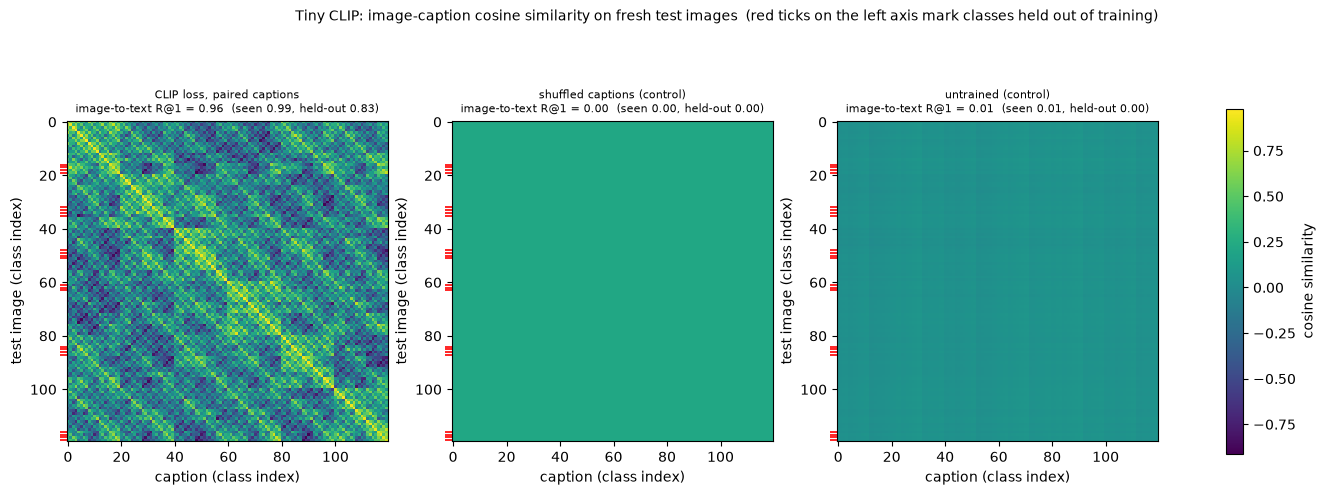

In [ ]:
sims, metrics = {}, {}
for name, m in [
    ("CLIP loss, paired captions", runs["CLIP loss, paired captions"][0]),
    ("shuffled captions (control)", runs["CLIP loss, shuffled captions (control)"][0]),
    ("untrained (control)", untrained),
]:
    image_emb, text_emb = embed_all(m, test_images, CAPTION_IDS)
    sims[name] = similarity_logits(image_emb, text_emb, 1.0).cpu().numpy()
    r = evaluate_tiny(m, test_images, CAPTION_IDS, held_out_mask)
    metrics[name] = f"image-to-text R@1 = {r['i2t']:.2f}  (seen {r['i2t_seen']:.2f}, held-out {r['i2t_held_out']:.2f})"
utils.plot_retrieval_heatmaps(sims, held_out_mask.numpy(), metrics, title="Tiny CLIP: image-caption cosine similarity on fresh test images")

<details>
<summary>Help - how should I interpret these heatmaps?</summary>

**Left: the trained model.** There's a bright diagonal band: each test image is most similar to its own caption (image-to-text R@1 = 0.94: 1.00 on the 96 seen classes and 0.71 on
the 24 held-out ones; chance is 0.008). The checkered pattern around it tells you *what* the model confuses. Classes are ordered colour-major, then shape, then position, so the
bright off-diagonal stripes belong to captions that share a colour, a shape or a position with the true one. Similarity is high between captions that share words, so the model has
learned attributes, not 120 unrelated labels.

**Middle: the shuffled-caption control.** It is flat. The model trained on randomly paired captions ends at a loss of 4.159 = $\log 64$ (it learned that it can't know) and the
whole matrix is a single constant: all images have collapsed to one embedding, and all captions to another. R@1 is 0.00, which is chance (0.008 means one image out of 120).

**Right: the untrained model.** Also flat, with cosines close to zero and faint horizontal banding: a random network gives each image a slightly different but meaningless
embedding. R@1 = 0.01.

**Held-out classes (red ticks).** Their rows also have a bright diagonal entry, but a less sharp one: 17 of the 24 combinations the model has never seen (a green star, a blue
triangle, ...) are retrieved correctly from all 120 captions, including the 96 it was trained on. So the tiny CLIP is partly *compositional*, and not merely memorising. The "Try it
yourself" section below shows one of the failures.

All three panels share one colour scale, so the difference between the trained model and its controls isn't an artefact of rescaling.
</details>

## A consistent wrong labelling is not a control

The `"shuffled"` control fails, as it should: nothing to learn, chance retrieval, and a flat similarity matrix. But we defined a second kind of wrong pairing, `"permuted"`, which
relabels every class *consistently*. Think about what a model trained on it would learn, and then test your prediction. We train it with the same settings, and evaluate it twice:
against the true captions (the same evaluation as before), and against the *relabelled* captions it was actually trained on. To see the second evaluation, we draw the same
similarity matrix twice: once with the columns in true class order, and once with the columns re-ordered so that column $c$ holds the caption which the model was taught to
associate with class $c$.


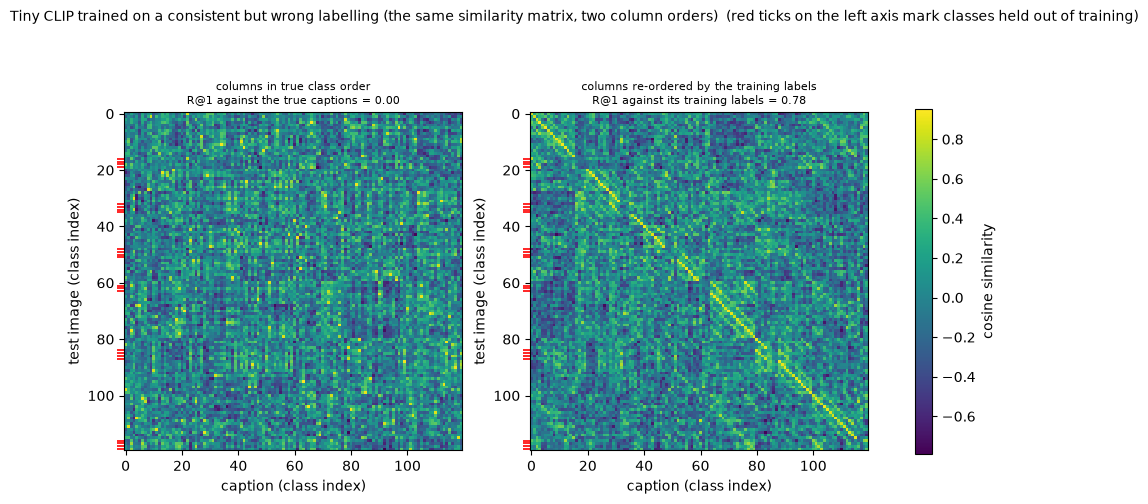

In [ ]:
fixed_perm = t.randperm(len(CLASSES), generator=t.Generator().manual_seed(123))
m_perm = fresh_model()
hist_perm = train_tiny_clip(m_perm, train_images, CAPTION_IDS, train_classes, "clip", "permuted", fixed_perm=fixed_perm, eval_fn=eval_i2t)
image_emb, text_emb = embed_all(m_perm, test_images, CAPTION_IDS)
sim = similarity_logits(image_emb, text_emb, 1.0)
classes = t.arange(len(CLASSES), device=device)
true_pairing = retrieval_metrics(sim, classes, classes)["image_to_text"]
# the caption this model was taught to associate with class c is caption fixed_perm[c]
learned_pairing = retrieval_metrics(sim, fixed_perm.to(device), classes)["image_to_text"]
print(f"final training loss: {np.mean(hist_perm['loss'][-50:]):.3f}")
print(f"image-to-text R@1 against the TRUE captions:               {true_pairing:.3f}")
print(f"image-to-text R@1 against the captions it was TRAINED on:  {learned_pairing:.3f}")
utils.plot_retrieval_heatmaps(
    {
        "columns in true class order": sim.cpu().numpy(),
        "columns re-ordered by the training labels": sim[:, fixed_perm.to(device)].cpu().numpy(),
    },
    held_out_mask.numpy(),
    {
        "columns in true class order": f"R@1 against the true captions = {true_pairing:.2f}",
        "columns re-ordered by the training labels": f"R@1 against its training labels = {learned_pairing:.2f}",
    },
    title="Tiny CLIP trained on a consistent but wrong labelling (the same similarity matrix, two column orders)",
)

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">final training loss: 0.004
image-to-text R@1 against the TRUE captions:               0.000
image-to-text R@1 against the captions it was TRAINED on:  0.792</pre>

</details>

<details>
<summary>Question - what does this tell us about what a "random caption" baseline can and can't rule out?</summary>

The permuted model learned its (wrong) task *perfectly*: a final loss of 0.004, as low as the paired model's. Against the true captions its R@1 is 0.000, which is what a "random
caption" control would give, but against the relabelled captions it was trained on the R@1 is 0.792, which is 95 of 120 classes, i.e. essentially all of the 96 it saw in training
(and none of the 24 held-out ones, whose relabelled captions it never saw). In the right panel, the bright diagonal appears as soon as the columns are put in the order of its
training labels.

So a *consistent* random labelling is not a null control: it is a different but equally learnable dataset. The image tower learned what a red circle in the top left looks like, the
text tower learned which sentence to put next to that, and nothing in the loss cares whether the sentence is the "right" one. Two lessons:

- A control that is *fresh at every step* (the `"shuffled"` pairing) tests whether the pairing carries information. A fixed relabelling doesn't: it carries exactly as much information as the real one.
- High retrieval accuracy by itself can't tell you that a model understands English, since it is reachable with captions that are arbitrary tokens. What
  distinguishes the paired model from the permuted one is the **held-out combinations**: the paired model retrieves 0.71 of them by composing the meaning of the
  words, and the permuted model gets none, because composing arbitrary labels is impossible. A test where the answer depends on meaning is what you need.
</details>

## Training with the sigmoid loss

Now swap the loss. We train four more models with the same architecture, schedule and seed: SigLIP loss with the paper's initialisation (scale 10, bias $-10$), SigLIP loss with
random captions (the control), and SigLIP loss with a **CLIP-style initialisation** (scale 14.3, bias 0), once for the same 2,000 steps and once for 6,000. The last two test the
story from Part 1 about why the bias starts at $-10$. Then we plot the evaluation curves of all of them, together with the CLIP runs, on one set of axes.


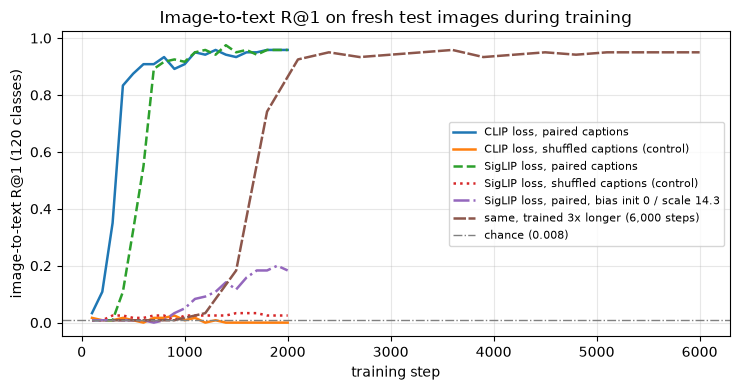

In [ ]:
for name, control, steps, kwargs in [
    ("SigLIP loss, paired captions", "paired", 2000, dict(siglip=True)),
    ("SigLIP loss, shuffled captions (control)", "shuffled", 2000, dict(siglip=True)),
    ("SigLIP loss, paired, bias init 0 / scale 14.3", "paired", 2000, dict(siglip=True, scale_init=1 / 0.07, bias_init=0.0)),
    ("same, trained 3x longer (6,000 steps)", "paired", 6000, dict(siglip=True, scale_init=1 / 0.07, bias_init=0.0)),
]:
    m = fresh_model(**kwargs)
    runs[name] = (m, train_tiny_clip(m, train_images, CAPTION_IDS, train_classes, "siglip", control, steps=steps, eval_fn=eval_i2t, eval_every=steps // 20))
    r = evaluate_tiny(m, test_images, CAPTION_IDS, held_out_mask)
    bias = f"{m.logit_bias.item():+.2f}"
    print(f"{name:<48} final loss {np.mean(runs[name][1]['loss'][-50:]):.3f}   i2t R@1 {r['i2t']:.3f} (held-out {r['i2t_held_out']:.3f})   scale {m.logit_scale.exp().item():.1f}  bias {bias}")
for name in ["CLIP loss, paired captions", "CLIP loss, shuffled captions (control)"]:
    m = runs[name][0]
    r = evaluate_tiny(m, test_images, CAPTION_IDS, held_out_mask)
    print(f"{name:<48} final loss {np.mean(runs[name][1]['loss'][-50:]):.3f}   i2t R@1 {r['i2t']:.3f} (held-out {r['i2t_held_out']:.3f})   scale {m.logit_scale.exp().item():.1f}")

utils.plot_training_curves(
    {name: (h["eval_steps"], h["eval"]) for name, (m, h) in runs.items()},
    "Image-to-text R@1 on fresh test images during training",
    "image-to-text R@1 (120 classes)",
    chance=1 / len(CLASSES),
)

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">SigLIP loss, paired captions                     final loss 0.433   i2t R@1 0.958 (held-out 0.792)   scale 12.3  bias -9.99
SigLIP loss, shuffled captions (control)         final loss 5.151   i2t R@1 0.025 (held-out 0.000)   scale 9.9  bias -9.95
SigLIP loss, paired, bias init 0 / scale 14.3    final loss 2.890   i2t R@1 0.175 (held-out 0.125)   scale 14.5  bias -0.00
same, trained 3x longer (6,000 steps)            final loss 0.119   i2t R@1 0.942 (held-out 0.875)   scale 31.4  bias -0.07
CLIP loss, paired captions                       final loss 0.018   i2t R@1 0.942 (held-out 0.708)   scale 18.9
CLIP loss, shuffled captions (control)           final loss 4.159   i2t R@1 0.000 (held-out 0.000)   scale 14.0</pre>

</details>

<details>
<summary>Help - how should I interpret this plot?</summary>

**Both losses learn the task, at about the same level.** The CLIP-loss model's retrieval jumps between steps 300 and 400 and plateaus around 0.94. The sigmoid-loss model takes off
more slowly (between steps 300 and 700) but reaches a similar plateau (0.96 at the end; 0.79 on held-out classes, against 0.71 for CLIP), so at this scale neither loss has an
accuracy advantage and the main difference is *speed*.

**Both controls stay at chance (0.008) throughout.** The CLIP control sits at a loss of $\log 64 = 4.159$. The SigLIP control sits at a loss of **5.151**, which is not $\log 64$
and deserves an explanation: if the model can't tell the pairs apart it can at best give every pair the same logit, and with one positive and 63 negatives per row the best constant
probability is $1/64$. That gives $\text{softplus}(-z) + 63\,\text{softplus}(z)$ at $z = -\log 63$, which is $\log 64 + 63 \log(1 + 1/63) = 4.159 + 0.992 = 5.151$ (the Bonus asks
you to derive this).

**The initialisation is about speed.** The CLIP-style initialisation (scale 14.3, bias 0) is *much* slower: after 2,000 steps it has an R@1 of only 0.175, against 0.96 for the
paper's initialisation; the loss is 2.89, nowhere near zero. Whether this is "stuck" or "slow" is something we can test: in the run with three times as many steps it does get there
(R@1 0.94, held-out 0.88), after a long delay of about 1,000 steps in which nothing seems to happen. Notice how it got there: the bias is still at $-0.07$ (it barely moves at this
learning rate) and instead the logit scale grew from 14.3 to 31. The model solved the imbalance of Part 1 by making the logits *larger* rather than shifting them. The $-10$ bias
initialisation doesn't make the task possible; it makes it fast.

The learned parameters at the end of the 2,000-step runs: CLIP's scale grew from 14.3 to 18.9; SigLIP's moved from 10 to 12.3 and its bias stayed at $-9.99$. Compare these with the
real models in Part 3.
</details>

## Try it yourself - ask the tiny CLIP

The function below renders a fresh image of any (colour, shape, position) you choose, embeds it, and shows the model's five best captions with their cosine similarities. Try:

- A **seen** combination, to check that the picture of success from the heatmap holds up on a new image: `("red", "circle", "top left")`.
- A **held-out** combination, such as `("green", "star", "top left")` or `("blue", "triangle", "bottom right")`. Does it find the exact caption? If not, which attribute does it get wrong: colour, shape or position? Is it always the same one?
- Different positions of the *same* combination: does position matter more or less than colour?
- Other models from the `runs` dictionary, e.g. the SigLIP-loss model (`runs["SigLIP loss, paired captions"][0]`), and the controls: what do they say about a clean picture of a red circle?


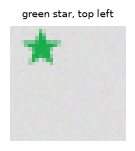

In [ ]:
@t.no_grad()
def ask_tiny_clip(model: TinyCLIP, colour: str, shape: str, position: str, seed: int = 123, k: int = 5) -> None:
    """Render a fresh image of the given class, show it, and print the model's top-k captions."""
    rng = np.random.default_rng(seed)
    image = utils.render_tiny(shape, colour, position, rng)
    pixels = t.tensor(image).permute(2, 0, 1).float().div(255)[None].to(device)
    image_emb, text_emb = embed_all(model, pixels, CAPTION_IDS)
    cosines = similarity_logits(image_emb, text_emb, 1.0)[0]
    plt.figure(figsize=(1.5, 1.5))
    plt.imshow(image, interpolation="nearest")
    plt.axis("off")
    plt.title(f"{colour} {shape}, {position}", fontsize=7)
    plt.show()
    top = cosines.topk(k)
    for value, idx in zip(top.values.tolist(), top.indices.tolist()):
        held = "  (held-out class)" if held_out_mask[idx] else ""
        print(f"  {value:+.3f}  {CAPTIONS[idx]!r}{held}")


ask_tiny_clip(runs["CLIP loss, paired captions"][0], "green", "star", "top left")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">  +0.892  'a green triangle in the top left'
  +0.880  'a blue star in the top left'
  +0.821  'a green star in the top left'  (held-out class)
  +0.802  'a blue triangle in the top left'  (held-out class)
  +0.628  'a yellow star in the top left'</pre>

</details>

The model doesn't retrieve `'a green star in the top left'`, even though it's one of the candidates. Its two best answers each get one attribute wrong: `'a green triangle'` (right
colour, wrong shape, +0.892) and `'a blue star'` (right shape, wrong colour, +0.880). The true caption is third, at +0.821. So for this unseen combination the model has the
position right and *both* colour and shape partly right, since it's found captions which share one attribute but failed to pick the one that shares both. This is what the 0.71
held-out score looks like from the inside: 7 of the 24 unseen combinations fail, and this is one way of failing. Try `("blue", "triangle", "bottom right")` and other combinations,
and see whether the failure is always an error in one attribute.

## Summary of 2️⃣

- A 220,000-parameter dual encoder, built from a patchify function, two small transformers and your loss, learns to match images and captions from scratch in about 2,000 steps: image-to-text R@1 is 0.94 over 120 classes (chance 0.008), and the retrieval matrix shows a clean diagonal.
- **Controls.** Training on shuffled captions collapses the model (loss $\log 64$, a flat matrix, R@1 0.00); an untrained model is at chance. A *consistent* wrong labelling is learned perfectly (0.79 against its own labels, 0.00 against the true ones), so only a control that is fresh at every step is a null.
- Generalisation is partial: seen classes are retrieved perfectly (1.00), unseen colour-shape combinations only 0.71 of the time. The model composes attributes, but unreliably.
- The sigmoid loss reaches the same accuracy (0.96), but learns more slowly, and its initialisation matters: with scale 14.3 and bias 0 it reaches R@1 0.175 in 2,000 steps, against 0.96 with the paper's initialisation (it does get there in 6,000 steps).
- Batches must not contain repeated captions: 48% of rows would otherwise contain a false negative.

That's the machinery. Now let's see what the real thing looks like.

# 3️⃣ The Real CLIP and SigLIP

> ##### Learning Objectives
>
> - Reproduce a checkpoint's official logits from its embeddings, learned scale and (for SigLIP) bias
> - Measure zero-shot classification and retrieval on real images, with shuffled-caption and noise-image controls
> - Compare softmax and sigmoid confidence on out-of-domain captions and on noise, and see which loss lets a model abstain
> - Apply the checkpoint to your own images

## Two checkpoints

We'll use two pretrained dual encoders, both loaded through 🤗 Transformers:

- **CLIP ViT-B/32** (`openai/clip-vit-base-patch32`), from Radford et al. (2021), [*Learning Transferable Visual Models From Natural Language Supervision*](https://arxiv.org/abs/2103.00020): trained with the softmax InfoNCE loss on 400 million web image-text pairs.
- **SigLIP base** (`google/siglip-base-patch16-224`), from Zhai et al. (2023), [*Sigmoid Loss for Language Image Pre-Training*](https://arxiv.org/abs/2303.15343): the same recipe with the sigmoid loss, trained on the WebLI dataset.

Both are ViT-B-sized dual encoders, and they have exactly the structure of the tiny model you've just built, with a vision transformer, a text transformer, and two linear
projections into a shared space. We'll load them behind a small helper from `utils.py` which does the plumbing (tokenisation, resizing and normalisation, batching) and returns the
*raw* embeddings plus the learned logit scale and bias. Everything after that is your code.

In [ ]:
pairs = {kind: utils.load_pretrained(kind, device) for kind in ["CLIP", "SigLIP"]}
for kind, pair in pairs.items():
    vision, text = pair.model.vision_model, pair.model.text_model
    n_vision = sum(p.numel() for p in vision.parameters()) / 1e6
    n_text = sum(p.numel() for p in text.parameters()) / 1e6
    cfg = pair.model.config.vision_config
    dim = pair.embed_texts(["a photo"]).shape[-1]
    bias = "none" if pair.logit_bias is None else f"{pair.logit_bias:.2f}"
    print(f"{kind:<7} {pair.name:<34} vision tower {n_vision:5.1f}M, text tower {n_text:5.1f}M, patch {cfg.patch_size}, image {cfg.image_size}px, embedding dim {dim}, logit scale {pair.logit_scale:6.2f}, logit bias {bias}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">CLIP    openai/clip-vit-base-patch32       vision tower  87.5M, text tower  63.2M, patch 32, image 224px, embedding dim 512, logit scale 100.00, logit bias none
SigLIP  google/siglip-base-patch16-224     vision tower  92.9M, text tower 110.3M, patch 16, image 224px, embedding dim 768, logit scale 117.33, logit bias -12.93</pre>

</details>

Two numbers to remember. CLIP's logit scale is exactly **100**: it has hit the clamp you implemented in `train_tiny_clip` (the temperature the model wanted was lower than 0.01).
SigLIP's learned scale is about **117** (it started at 10) and its bias about **-12.9** (it started at -10).

## Checking your code against the checkpoints

Before using the models for anything, let's check that the formulas from Part 1 really are what the checkpoints compute. The 🤗 models return their own `logits_per_image`, with the
scale (and for SigLIP the bias) already applied. Embed a few images and captions yourself, push them through *your* `similarity_logits` with the checkpoint's own scale and bias,
and compare.

Our test images are a **sample of CIFAR-10** (Krizhevsky, 2009): 200 real photographs, 20 from each of 10 classes, only 32×32 pixels each. That's a harsh test, since the models
were trained on large clean web images and will see our tiny pictures upsampled to 224×224, but it's cheap and standard. Here are two per class.


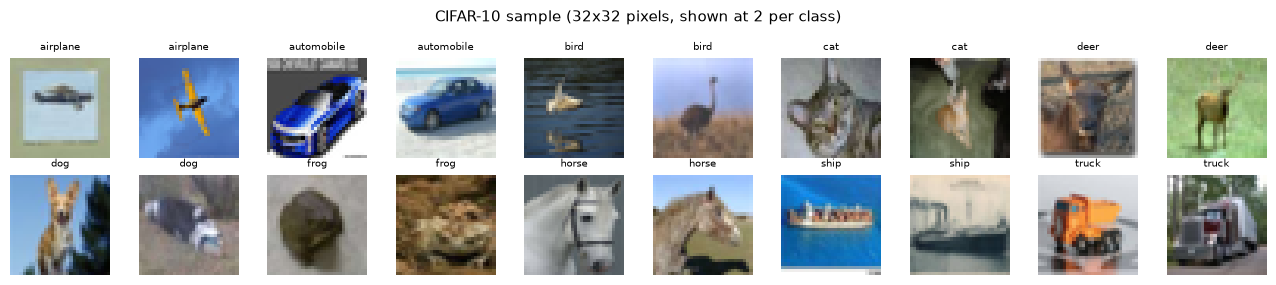

In [ ]:
cifar_images, cifar_labels = utils.load_cifar10_sample()  # uint8 [200, 32, 32, 3], int [200]
pil_images = utils.to_pil(cifar_images)
labels = t.tensor(cifar_labels)
class_names = utils.CIFAR10_CLASSES
class_ids = t.arange(len(class_names))

utils.show_image_grid(
    np.concatenate([cifar_images[labels == c][:2] for c in range(10)]),
    [class_names[c] for c in range(10) for _ in range(2)],
    ncols=10,
    scale=1.3,
    title="CIFAR-10 sample (32x32 pixels, shown at 2 per class)",
)

In [ ]:
def captions_for(names: list[str], template: str = "a photo of a {}") -> list[str]:
    return [template.format(name) for name in names]


check_images, check_texts = pil_images[::40], captions_for(class_names[:5])
for kind, pair in pairs.items():
    ours = similarity_logits(
        pair.embed_images(check_images), pair.embed_texts(check_texts), pair.logit_scale, 0.0 if pair.logit_bias is None else pair.logit_bias
    )
    official = pair.official_logits(check_images, check_texts)
    print(f"{kind:<7} max |ours - official| over {ours.numel()} logits: {(ours - official).abs().max().item():.2e}   (logits range from {official.min():.1f} to {official.max():.1f})")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">CLIP    max |ours - official| over 25 logits: 9.54e-06   (logits range from 17.4 to 25.7)
SigLIP  max |ours - official| over 25 logits: 1.91e-06   (logits range from -15.3 to -1.9)</pre>

</details>

The differences are at the level of floating-point noise, so a SigLIP logit really is `scale · cos + bias` of the two towers' embeddings, and a CLIP logit is `100 · cos`. (If you
got a large difference, the usual culprits are forgetting that `logit_scale` is already exponentiated, or forgetting the bias for SigLIP.)

## From logits to probabilities

A logit matrix is not yet a probabilistic readout. The two losses suggest different rules for mapping logits to model-assigned probabilities. Neither rule alone justifies saying an
image is 91% likely to be a cat: that empirical interpretation also needs calibration evidence.

- **CLIP / softmax**: the model was trained to pick one caption out of the batch, so its natural reading is a distribution over the *candidate captions*: $P(\text{caption } j \mid \text{image } i) = \text{softmax}_j(S_{ij})$. The probabilities of one image sum to 1 *by construction*, whatever the candidates are.
- **SigLIP / sigmoid**: the model was trained to answer a yes/no question for each pair, so its natural reading is $P(\text{match}) = \sigma(S_{ij})$, **independently for each caption**. Nothing forces these to sum to 1.

### Exercise - implement `zero_shot_probabilities`

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5 minutes on this exercise.
> ```

Implement `zero_shot_probabilities`, which takes the logit matrix `(n_images, n_texts)` and a `kind`, either `"softmax"` (normalise each row over the texts) or `"sigmoid"` (squash
each entry independently), and returns the probability matrix. Raise a `ValueError` for any other `kind`.

In [ ]:
def zero_shot_probabilities(logits: Float[Tensor, "n_images n_texts"], kind: str) -> Float[Tensor, "n_images n_texts"]:
    """'softmax': each row sums to 1 over the candidate texts (CLIP). 'sigmoid': each pair on its own (SigLIP)."""
    raise NotImplementedError()


tests.test_zero_shot_probabilities(zero_shot_probabilities)

<details><summary>Solution</summary>

```python
def zero_shot_probabilities(logits: Float[Tensor, "n_images n_texts"], kind: str) -> Float[Tensor, "n_images n_texts"]:
    """'softmax': each row sums to 1 over the candidate texts (CLIP). 'sigmoid': each pair on its own (SigLIP)."""
    if kind == "softmax":
        return logits.softmax(dim=-1)
    if kind == "sigmoid":
        return logits.sigmoid()
    raise ValueError(f"Unknown kind {kind!r}")
```
</details>

## Zero-shot retrieval on real photographs, with controls

Now the real measurement. For each model, we embed the 200 CIFAR images and the ten captions `"a photo of a {class}"`, form the logit matrix, and ask for image-to-text and
text-to-image R@1 using the function you wrote in Part 2. We also draw the same kind of picture as in Part 2, but at the level of classes: the $10 \times 10$ matrix whose entry
$(c, j)$ is the *mean cosine similarity* between the images of class $c$ and caption $j$.

Two controls, each with the same pipeline:

- **Shuffled labels.** The same images and captions, but each image is assigned to a random class (a random permutation of the 200 labels). The class-mean matrix has to be flat, and R@1 has to fall to chance (0.10).
- **Noise images.** 200 images of uniform random pixels, with the CIFAR labels attached. These contain no objects at all, so nothing should be recognised.


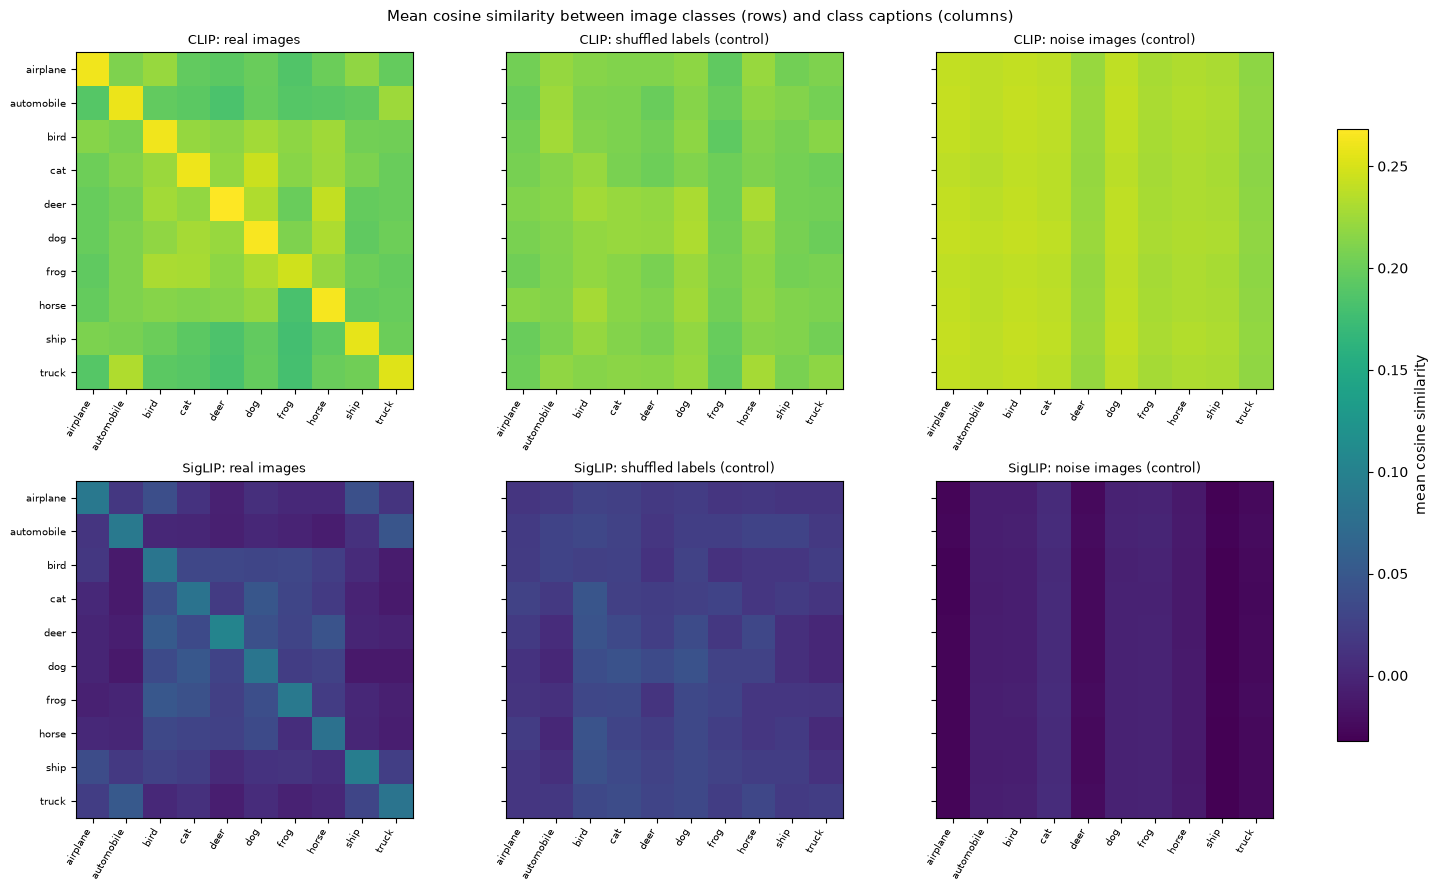

In [ ]:
def class_means(sim: Tensor, image_labels: Tensor, n_classes: int = 10) -> Tensor:
    """Mean of each row-block of `sim`, grouped by image label: [n_images, n_texts] -> [n_classes, n_texts]."""
    return t.stack([sim[image_labels == c].mean(0) for c in range(n_classes)])


rng = np.random.default_rng(0)
noise_images = utils.to_pil(rng.integers(0, 256, size=cifar_images.shape, dtype=np.uint8))
shuffled_labels = labels[t.randperm(len(labels), generator=t.Generator().manual_seed(0))]

text_emb, image_emb, noise_emb = {}, {}, {}
for kind, pair in pairs.items():
    text_emb[kind] = pair.embed_texts(captions_for(class_names))
    image_emb[kind] = pair.embed_images(pil_images)
    noise_emb[kind] = pair.embed_images(noise_images)

mats, rows = {}, []
for kind in pairs:
    for condition, emb, lab in [("real images", image_emb[kind], labels), ("shuffled labels (control)", image_emb[kind], shuffled_labels), ("noise images (control)", noise_emb[kind], labels)]:
        cos = similarity_logits(emb, text_emb[kind], 1.0)
        mats[f"{kind}: {condition}"] = class_means(cos, lab).numpy()
        r = retrieval_metrics(cos, lab, class_ids)
        rows.append({"model": kind, "condition": condition, "image-to-text R@1": r["image_to_text"], "text-to-image R@1": r["text_to_image"]})
utils.plot_class_heatmaps(mats, class_names, captions_for(class_names, "{}"), "Mean cosine similarity between image classes (rows) and class captions (columns)")
display(pd.DataFrame(rows).set_index(["model", "condition"]).round(3))

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">                                  image-to-text R@1  text-to-image R@1
model  condition
CLIP   real images                            0.880                1.0
       shuffled labels (control)              0.135                0.2
       noise images (control)                 0.100                0.1
SigLIP real images                            0.905                1.0
       shuffled labels (control)              0.140                0.0
       noise images (control)                 0.100                0.0</pre>
</details>

<details>
<summary>Help - how should I interpret these heatmaps and this table?</summary>

**Real images.** Both models show a strong diagonal: the mean cosine between an image and its own class caption is higher than with any other class's caption. R@1 is 0.88 for CLIP
and 0.905 for SigLIP (chance 0.10), and for text-to-image, the top-scoring image for each of the ten class captions has the right class (1.0) for both. The confusions are between
semantically close classes: animals with animals (cat/dog, deer/horse) and vehicles with vehicles (automobile/truck, airplane/ship), which is a good sign that the models are using
meaning, not a low-level shortcut.

Notice the *scale* of the cosines: CLIP's matched cosines are about 0.25 and SigLIP's about 0.05 to 0.09 (the colour scale is shared across all six panels). The two models use very
different parts of the cosine range, and their logit scale and bias compensate (CLIP: $100 \cos$; SigLIP: $117 \cos - 12.9$). Even CLIP's best cell is a cosine of 0.27: matched
image-caption pairs are *not* close to 1. We'll see why in Part 4.

**Controls.** With the image labels shuffled, the class-mean matrix is almost the same in every row, and R@1 falls to 0.135 and 0.14 (chance is 0.10; with 200 images, differences
of 0.02 are noise). With noise images the matrix is again flat across rows, and R@1 is 0.10: that is exactly what you'd get if every noise image picked the *same* caption (20 of
the 200 images belong to any one class). The noise panel isn't blank, however: it has *column* structure, meaning that some captions are more similar to every image than others.
Hold on to that caption-specific bias: it comes back, with consequences, in the binding test.
</details>

## Your losses on real data

Let's use the losses on the real models. Take one image from each of the ten classes (so that every caption is different, as in Part 2) and form the $10 \times 10$ logit matrix
with each model's own scale and bias. Then compute the loss it was trained with, and compare it with the same batch when the pairing is **wrong** (captions shifted by one place). A
trained model should have a small loss on the first and a very large loss on the second: the matching pairs get high logits, and a shifted pairing makes the model confidently
wrong.

In [ ]:
first_of_class = t.stack([(labels == c).nonzero()[0, 0] for c in range(10)])
for kind, pair in pairs.items():
    bias = 0.0 if pair.logit_bias is None else pair.logit_bias
    logits = similarity_logits(image_emb[kind][first_of_class], text_emb[kind], pair.logit_scale, bias)
    wrong = logits.roll(1, dims=1)  # image i is now scored against caption i-1, the pairing on the diagonal is wrong
    if kind == "CLIP":
        print(f"CLIP   (N=10, log N = {math.log(10):.2f}):  InfoNCE loss with correct pairing {clip_loss(logits):7.3f},  with shifted pairing {clip_loss(wrong):7.3f}")
    else:
        pos, neg = siglip_loss_terms(logits)
        wpos, wneg = siglip_loss_terms(wrong)
        print(f"SigLIP (N=10):             sigmoid loss with correct pairing {pos + neg:7.3f} (positive {pos:.3f} + negative {neg:.3f}),  with shifted pairing {wpos + wneg:7.3f} (positive {wpos:.3f} + negative {wneg:.3f})")
    print(f"       the model's own logits as probabilities for image 0 (a {class_names[0]}):", ", ".join(f"{p:.2f}" for p in zero_shot_probabilities(logits, "softmax" if kind == "CLIP" else "sigmoid")[0, :4].tolist()), "...")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">CLIP   (N=10, log N = 2.30):  InfoNCE loss with correct pairing   0.237,  with shifted pairing   5.004
       the model's own logits as probabilities for image 0 (a airplane): 0.60, 0.29, 0.02, 0.00 ...
SigLIP (N=10):             sigmoid loss with correct pairing   3.115 (positive 3.113 + negative 0.002),  with shifted pairing  11.367 (positive 11.276 + negative 0.091)
       the model's own logits as probabilities for image 0 (a airplane): 0.13, 0.00, 0.00, 0.00 ...</pre>

</details>

**CLIP.** On a batch of ten different images the InfoNCE loss is 0.237, far below $\log 10 = 2.30$, so the model is almost sure which caption goes with which image. With the
pairing shifted, the loss is 5.0, more than twice $\log N$: the same "confidently wrong" effect as in Part 1. For image 0 (an airplane), the probabilities are 0.60 for `a photo of
a airplane` and 0.29 for `a photo of a automobile`.

**SigLIP.** The loss on the *correct* pairing is 3.115, almost all positive term (3.113; the negative term is 0.002). The correct pairs get logits well below zero on average: for
image 0, the sigmoid match score for `a photo of a airplane` is 0.13. SigLIP ranks the right caption first frequently (R@1 0.905), yet its absolute scores for correct pairs are
often below 0.5. These are 32×32 CIFAR photographs enlarged to 224 pixels; distribution shift is a plausible contributor, but this experiment does not identify its cause or measure
calibration. With the shifted pairing the loss is 11.4. Ranking, threshold selection and probability calibration are separate questions: a low score does not mean that only 13% of
comparable pairs really match.

## What does the loss do to the output? Softmax versus sigmoid on things that aren't there

In Part 1 we found that the softmax loss is shift-invariant and the sigmoid loss is not. Here we compare their candidate-normalized and independent pairwise readouts on real
models. This is a score-separation experiment, not a calibration test. We ask both models three questions and record the **largest model-assigned probability** over the captions
for every image:

1. real CIFAR images with their ten correct class captions (the model *should* be confident);
2. the same real images, but with ten captions about something else entirely: `"a photo of a piano"`, `"... a guitar"`, `"... a violin"`, and so on (the model *should* find nothing to be confident about);
3. noise images with the ten correct captions (nothing to recognise).

We read out CLIP with a softmax, SigLIP with a softmax (so we can separate the effect of the *model* from the effect of the *readout*), and SigLIP with a sigmoid. **Predict** which
readouts can tell condition 1 from conditions 2 and 3.


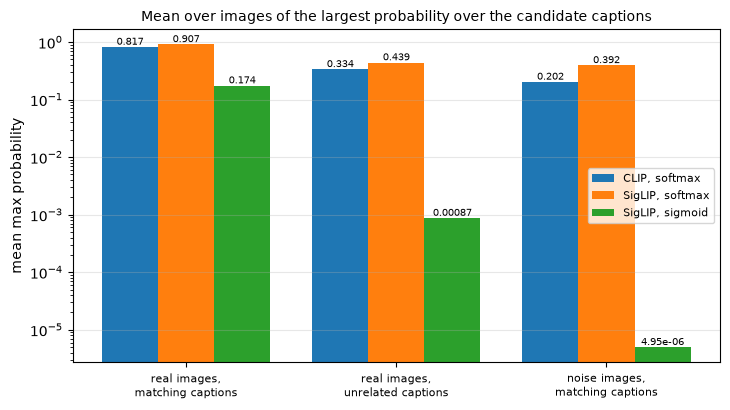

In [ ]:
instruments = ["piano", "guitar", "violin", "trumpet", "drum", "flute", "harp", "saxophone", "cello", "banjo"]
instrument_emb = {kind: pair.embed_texts(captions_for(instruments)) for kind, pair in pairs.items()}


def max_probability(kind: str, images: Tensor, texts: Tensor, readout: str) -> float:
    pair = pairs[kind]
    bias = 0.0 if pair.logit_bias is None else pair.logit_bias
    probs = zero_shot_probabilities(similarity_logits(images, texts, pair.logit_scale, bias), readout)
    return probs.max(dim=-1).values.mean().item()


readouts = {"CLIP, softmax": ("CLIP", "softmax"), "SigLIP, softmax": ("SigLIP", "softmax"), "SigLIP, sigmoid": ("SigLIP", "sigmoid")}
conditions = {
    "real images,\nmatching captions": lambda k: (image_emb[k], text_emb[k]),
    "real images,\nunrelated captions": lambda k: (image_emb[k], instrument_emb[k]),
    "noise images,\nmatching captions": lambda k: (noise_emb[k], text_emb[k]),
}
confidence = {
    cond: {name: max_probability(kind, *get(kind), readout) for name, (kind, readout) in readouts.items()}
    for cond, get in conditions.items()
}
for cond, values in confidence.items():
    print(f"{cond.replace(chr(10), ' '):<36}" + "   ".join(f"{name}: {v:.3g}" for name, v in values.items()))
utils.plot_bars(confidence, "Mean over images of the largest probability over the candidate captions", "mean max probability", log=True)

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">real images, matching captions      CLIP, softmax: 0.817   SigLIP, softmax: 0.907   SigLIP, sigmoid: 0.174
real images, unrelated captions     CLIP, softmax: 0.334   SigLIP, softmax: 0.439   SigLIP, sigmoid: 0.000859
noise images, matching captions     CLIP, softmax: 0.202   SigLIP, softmax: 0.392   SigLIP, sigmoid: 4.95e-06</pre>

</details>

<details>
<summary>Help - how should I interpret this plot?</summary>

Read the three groups of bars from left to right.

- **Real images, matching captions.** CLIP's softmax puts on average 0.82 on its top caption, SigLIP's softmax 0.91, and SigLIP's largest sigmoid match score averages 0.17. That is a model score, not evidence that only 17% of the selected captions actually match; we have not measured its calibration.
- **Real images, unrelated captions.** The question "which of these ten musical instruments is this photo of a ship?" has no good answer. The softmax readouts
  still put 0.33 (CLIP) and 0.44 (SigLIP) of their probability on a single instrument, since the probabilities have to add up to 1 over the candidates. That is
  about *half* of what they put on the right answer when it's available. The sigmoid readout drops by a factor of 200, to 0.0009.
- **Noise images, matching captions.** Softmax: 0.20 (CLIP) and 0.39 (SigLIP) on the top class (for ten classes, spread evenly, it would be 0.10). Sigmoid: $5 \times 10^{-6}$.

So the softmax readouts tell "there's something here" from "there's nothing here" by a factor of 2 to 4, and the sigmoid readout by factors of 200 and 35,000. Notice that SigLIP's
*softmax* confidence is as uninformative as CLIP's: the difference isn't in the logits of the model, it's in the readout. The same logits passed through a softmax are forced to
name a winner. The sigmoid, which is the readout the loss actually trained, can say "none of them".

An honest caveat: CLIP's softmax isn't useless for this, since its confidence does fall from 0.82 to 0.33 to 0.20 and a threshold on it would do something. But the absolute level
(a third of its probability on a wrong instrument) isn't interpretable, and what it means depends on how many candidates you gave it.
</details>

## Try it yourself - classify your own picture

Here's a function that takes any picture and any list of labels and reports what both models say, as the softmax probability (CLIP and SigLIP) and the sigmoid probability (SigLIP
only). We've set it up with two photographs that come bundled with scikit-learn. Things to try:

- Change the **labels**. Include a label which is *not* in the picture, and one which is nothing like anything in the picture. How does each readout behave?
- Change the **prompt template**. `"a photo of a {}"` is the template from the CLIP paper, and prompt wording matters: try `"a blurry photo of a {}"`, `"{}"` (just the label), or `"a drawing of a {}"`.
- Use **your own image**: pass `Image.open("path/to/file.jpg")`. Use a picture of something you know the models can't have seen (a handwritten note, a diagram, a photo of your desk).
- Go back to the CIFAR images and see whether the template `"a low-resolution photo of a {}"` changes the *sigmoid* probabilities for the correct class (they were low earlier).


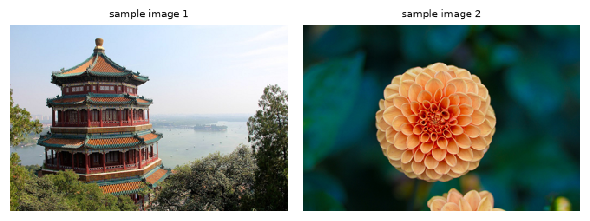

In [ ]:
def classify_image(image: Image.Image, labels: list[str], template: str = "a photo of a {}") -> None:
    """Print each model's probability for every label."""
    captions = captions_for(labels, template)
    rows = []
    for kind, pair in pairs.items():
        bias = 0.0 if pair.logit_bias is None else pair.logit_bias
        logits = similarity_logits(pair.embed_images([image]), pair.embed_texts(captions), pair.logit_scale, bias)
        softmax = zero_shot_probabilities(logits, "softmax")[0].tolist()
        sigmoid = zero_shot_probabilities(logits, "sigmoid")[0].tolist() if kind == "SigLIP" else [float("nan")] * len(labels)
        rows.append(pd.DataFrame({f"{kind} softmax": softmax, **({"SigLIP sigmoid": sigmoid} if kind == "SigLIP" else {})}, index=labels))
    display(pd.concat(rows, axis=1).round(4))


from sklearn.datasets import load_sample_images

temple, flower = [Image.fromarray(x) for x in load_sample_images().images]
utils.show_image_grid(np.stack([np.asarray(temple.resize((320, 214))), np.asarray(flower.resize((320, 214)))]), ["sample image 1", "sample image 2"], ncols=2, scale=3)
classify_image(temple, ["temple", "castle", "car", "cat", "dog", "pagoda", "piano"])
classify_image(flower, ["flower", "bee", "car", "cat", "dog", "garden", "piano"])

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">        CLIP softmax  SigLIP softmax  SigLIP sigmoid
temple        0.0122          0.0191          0.0443
castle        0.0049          0.0002          0.0004
car           0.0000          0.0000          0.0000
cat           0.0000          0.0000          0.0000
dog           0.0000          0.0000          0.0000
pagoda        0.9829          0.9808          0.7046
piano         0.0000          0.0000          0.0000
        CLIP softmax  SigLIP softmax  SigLIP sigmoid
flower        0.9931          0.9964          0.3778
bee           0.0008          0.0004          0.0002
car           0.0000          0.0000          0.0000
cat           0.0000          0.0000          0.0000
dog           0.0001          0.0000          0.0000
garden        0.0056          0.0032          0.0020
piano         0.0004          0.0000          0.0000</pre>
</details>

Both models put almost all of their softmax mass on `pagoda` (0.98) for the first image and very little on `temple` (0.01, 0.02), since `pagoda` is the better description of the
building. The sigmoid agrees with the ranking and adds an absolute level: `pagoda` is a 70% match and `temple` a 4% match (the picture is the Summer Palace in Beijing; "a photo of
a temple" is a plausible but not standard caption). For the flower, the softmax is 99% sure of `flower` but the sigmoid says only 38%, since the picture is a close-up of one dahlia
and `flower` is quite a generic description (try `dahlia`). The softmax said 0.99 because everything else on the list was worse, which is all a softmax can say.

## Summary of 3️⃣

- Your `similarity_logits` reproduces the checkpoints' official logits to $10^{-5}$: a CLIP logit is $100 \cos$, and a SigLIP logit is $117 \cos - 12.9$. The "architecture" of both is exactly the dual encoder you built.
- On real photographs, zero-shot retrieval gets 0.88 (CLIP) and 0.905 (SigLIP) image-to-text R@1; shuffled labels and noise images fall to chance, and the confusions are semantic.
- On a real batch the InfoNCE loss is 0.24 for the correct pairing and 5.0 for a shifted one; the sigmoid loss is 3.1 and 11.4. SigLIP ranks correctly but gives low *absolute* match probabilities to these small, blurry images.
- The two losses give outputs with different *meanings*. A softmax output always sums to 1 over the candidates, so even on unrelated captions or noise it keeps
  a third to a half of its probability on one of them (0.33 to 0.44). The independent sigmoid match scores can all be low: 0.0009 on unrelated captions and $5
  \times 10^{-6}$ on noise. This score separation does not by itself establish probability calibration or reliable abstention.
- Matched image-caption cosines are small (0.26 for CLIP, 0.09 for SigLIP) even when retrieval works. In the next part we'll see where the embeddings actually sit.

# 4️⃣ The Geometry of the Joint Space

> ##### Learning Objectives
>
> - Measure the modality gap and test, with a random-direction control, whether it matters for retrieval
> - Estimate attribute directions as differences of group means, and test that the image-derived and caption-derived directions agree
> - Steer an image embedding along an attribute direction and check the effect with norm-matched random and wrong-attribute controls
> - Partition the variance of text embeddings into additive factors, with a shuffled-label null
> - Score a model on Winoground-style binding tests, and check an architecture-versus-data explanation by training a tiny model on two-object scenes

## A factorial test set

To study the geometry of the joint space we need inputs whose attributes we know *exactly* and which cover every combination: a **factorial design**. We'll render images of one
coloured shape on a plain background at 224×224 (the models' native resolution), with every combination of

- **colour**: red, green, blue, yellow, purple, orange (6)
- **shape**: circle, square, triangle, star, heart (5)
- **pattern**: plain, striped, dotted (3)

That's 90 combinations, each rendered three times with random size, position and shade, giving 270 images, and one caption per combination: `"a red circle"`, `"a red striped
circle"`, `"a red dotted circle"`. This is the same kind of world as the tiny CLIP's, but now we're asking the *real* models about it.

Before looking inside, a behavioural baseline: how well do the models retrieve the exact caption out of all 90, and how well do they identify each attribute on its own (with
captions like `"a red shape"`, `"a circle"`, `"a striped shape"`)?


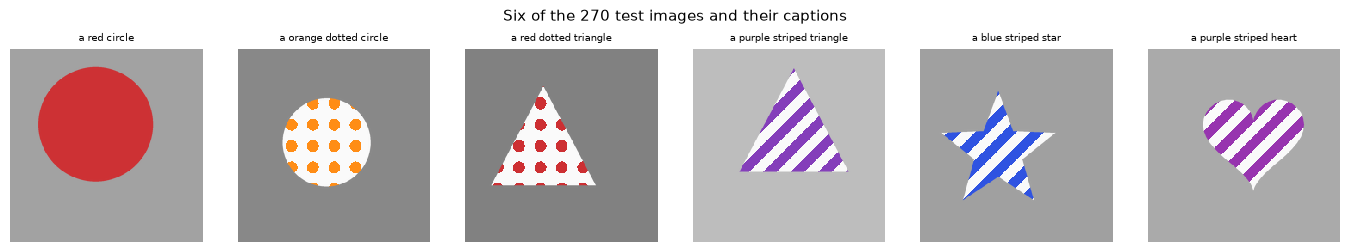

In [ ]:
PATTERNS = ["plain", "striped", "dotted"]
COMBOS = list(itertools.product(SHAPES, COLOURS, PATTERNS))  # (shape, colour, pattern); the combo index is the list index


def combo_caption(shape: str, colour: str, pattern: str) -> str:
    return f"a {colour} {shape}" if pattern == "plain" else f"a {colour} {pattern} {shape}"


rng = np.random.default_rng(0)
N_RENDERS = 3
factorial_images = [utils.render_large(shape, colour, rng, pattern) for _ in range(N_RENDERS) for shape, colour, pattern in COMBOS]
image_combo = t.arange(len(COMBOS)).repeat(N_RENDERS)  # combo index of each of the 270 images
attrs = {
    "shape": [c[0] for c in COMBOS],
    "colour": [c[1] for c in COMBOS],
    "pattern": [c[2] for c in COMBOS],
}
image_attrs = {name: [values[i] for i in image_combo.tolist()] for name, values in attrs.items()}

show = [0, 17, 38, 49, 61, 85]
utils.show_image_grid(
    np.stack([factorial_images[i] for i in show]),
    [combo_caption(*COMBOS[i]) for i in show],
    ncols=6,
    scale=2.3,
    title="Six of the 270 test images and their captions",
)

In [ ]:
fact = {}
for kind, pair in pairs.items():
    fact[kind] = {
        "image": pair.embed_images(utils.to_pil(factorial_images)),
        "text": pair.embed_texts([combo_caption(*c) for c in COMBOS]),
    }

rows = []
for kind, pair in pairs.items():
    row = {"model": kind}
    sim = similarity_logits(fact[kind]["image"], fact[kind]["text"], 1.0)
    row["90-way retrieval (colour+shape+pattern)"] = retrieval_metrics(sim, image_combo, t.arange(90))["image_to_text"]
    for attr, template in [("colour", "a {} shape"), ("shape", "a {}"), ("pattern", "a {} shape")]:
        values = {"colour": COLOURS, "shape": SHAPES, "pattern": PATTERNS}[attr]
        texts = pair.embed_texts([template.format(v) if v != "plain" else "a shape" for v in values])
        sim = similarity_logits(fact[kind]["image"], texts, 1.0)
        truth = t.tensor([values.index(v) for v in image_attrs[attr]])
        row[f"{attr} only ({len(values)}-way)"] = retrieval_metrics(sim, truth, t.arange(len(values)))["image_to_text"]
    rows.append(row)
display(pd.DataFrame(rows).set_index("model").round(3))
print(f"chance: 90-way {1 / 90:.3f}, colour {1 / 6:.3f}, shape {1 / 5:.3f}, pattern {1 / 3:.3f}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">        90-way retrieval (colour+shape+pattern)  colour only (6-way)  shape only (5-way)  pattern only (3-way)
model
CLIP                                      0.778                0.996               0.941                 0.678
SigLIP                                    0.978                1.000               1.000                 0.844
chance: 90-way 0.011, colour 0.167, shape 0.200, pattern 0.333</pre>
</details>

Both models handle this world, with a clear difference between them. SigLIP retrieves the exact caption out of 90 98% of the time (CLIP: 78%), with colour and shape essentially
perfect. The weak attribute for both is **pattern**: 68% for CLIP and 84% for SigLIP, against a chance level of 33%. This matters for the rest of the section: the models identify
colours and shapes essentially without error, so any failure we find below is not a failure to see the objects.

## The modality gap

If a dual encoder worked the way the loss suggests, the embedding of an image and of its caption would be nearly the *same vector*, with cosine similarity close to 1. They aren't. Liang et al. (2022, [*Mind the Gap: Understanding the Modality Gap in Multi-modal Contrastive Representation Learning*](https://arxiv.org/abs/2203.02053)) pointed out that in CLIP-like models the image embeddings and the text embeddings occupy two **separate, narrow cones** on the sphere, and that matched pairs are only as close as those two cones allow. They quantified the **modality gap** as the vector between the two clouds' centres,

$$
\Delta = \frac{1}{n}\sum_i \hat u_i - \frac{1}{m}\sum_j \hat v_j
$$

and found that it is already present at random initialisation (a "cone effect" of deep networks) and is preserved by contrastive training, since the temperature makes it a
good-enough place to sit.

### Exercise - measure the modality gap

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Implement `modality_gap`, which takes raw image embeddings `(n, d)` and raw text embeddings `(m, d)`, L2-normalises both, and returns the gap vector $\Delta$ (mean of the
normalised image embeddings minus mean of the normalised text embeddings) as a `(d,)` tensor.

In [ ]:
def modality_gap(image_emb: Float[Tensor, "n d"], text_emb: Float[Tensor, "m d"]) -> Float[Tensor, " d"]:
    """Mean of the normalised image embeddings minus mean of the normalised text embeddings."""
    raise NotImplementedError()


tests.test_modality_gap(modality_gap)

<details><summary>Solution</summary>

```python
def modality_gap(image_emb: Float[Tensor, "n d"], text_emb: Float[Tensor, "m d"]) -> Float[Tensor, " d"]:
    """Mean of the normalised image embeddings minus mean of the normalised text embeddings."""
    return F.normalize(image_emb, dim=-1).mean(dim=0) - F.normalize(text_emb, dim=-1).mean(dim=0)
```
</details>

Let's measure the gap in four models: the two real ones, and our tiny CLIP *before* and *after* training (on its 120 test images and 120 captions). The statistics:

- **gap norm** $\|\Delta\|$: the two unit vectors' centres can be at most 2 apart;
- **matched cosine**: the mean cosine similarity of an image with its own caption;
- **unmatched cosine**: the mean cosine similarity of an image with a *wrong* caption;
- **image-image** and **text-text** cosine: how tightly each cone is packed.


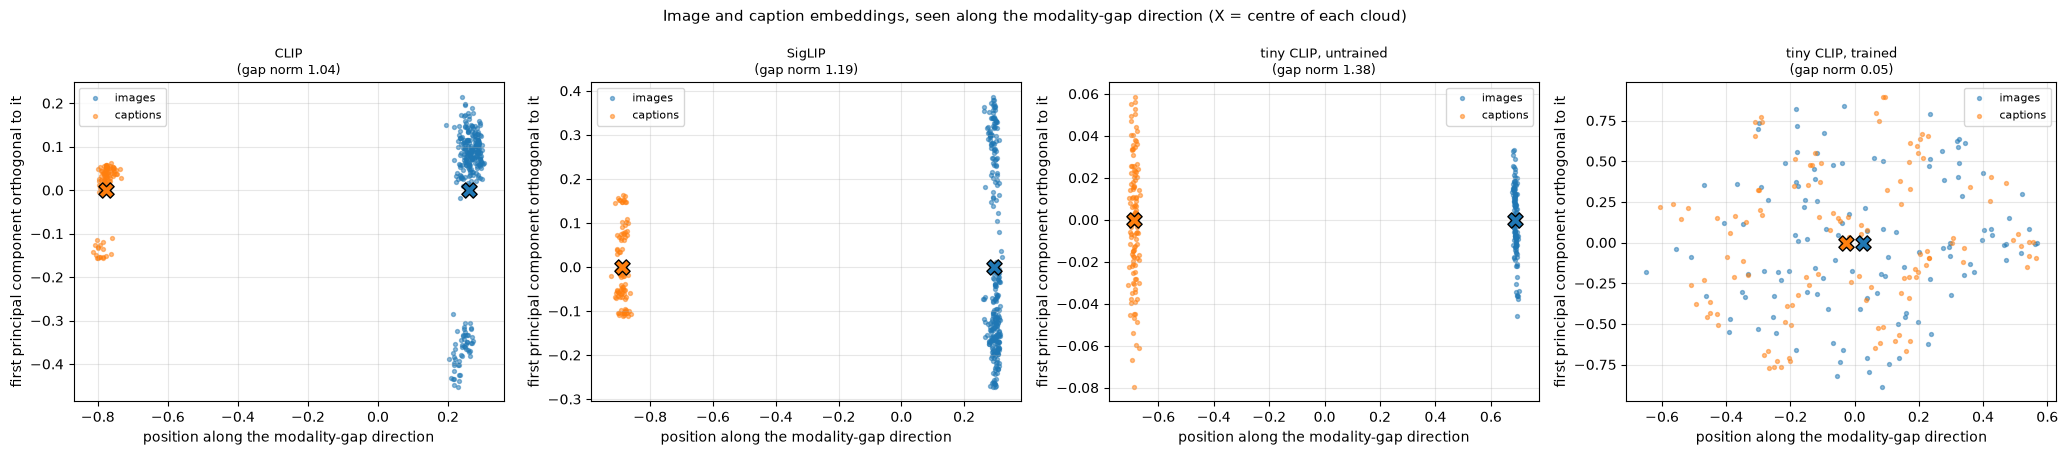

In [ ]:
def gap_stats(image_emb: Tensor, text_emb: Tensor, image_to_text: Tensor) -> dict[str, float]:
    """image_to_text[i] = index of image i's own caption."""
    ui, vt = F.normalize(image_emb, dim=-1), F.normalize(text_emb, dim=-1)
    cos = ui @ vt.T
    own = t.zeros_like(cos, dtype=t.bool)
    own[t.arange(len(ui)), image_to_text] = True
    n_i, n_t = len(ui), len(vt)
    return {
        "gap norm": modality_gap(image_emb, text_emb).norm().item(),
        "matched cos": cos[own].mean().item(),
        "unmatched cos": cos[~own].mean().item(),
        "image-image cos": ((ui @ ui.T).sum() - n_i).item() / (n_i * (n_i - 1)),
        "text-text cos": ((vt @ vt.T).sum() - n_t).item() / (n_t * (n_t - 1)),
    }


tiny_img_emb, tiny_txt_emb, gap_panels, gap_rows = {}, {}, {}, {}
for name, m in [("tiny CLIP, untrained", untrained), ("tiny CLIP, trained", runs["CLIP loss, paired captions"][0])]:
    tiny_img_emb[name], tiny_txt_emb[name] = [x.cpu() for x in embed_all(m, test_images, CAPTION_IDS)]
    gap_rows[name] = gap_stats(tiny_img_emb[name], tiny_txt_emb[name], t.arange(120))
    gap_panels[name] = (F.normalize(tiny_img_emb[name], dim=-1).numpy(), F.normalize(tiny_txt_emb[name], dim=-1).numpy())
for kind in pairs:
    gap_rows[kind] = gap_stats(fact[kind]["image"], fact[kind]["text"], image_combo)
    gap_panels[kind] = (F.normalize(fact[kind]["image"], dim=-1).numpy(), F.normalize(fact[kind]["text"], dim=-1).numpy())
display(pd.DataFrame(gap_rows).T.round(3))
utils.plot_modality_gap({k: gap_panels[k] for k in ["CLIP", "SigLIP", "tiny CLIP, untrained", "tiny CLIP, trained"]}, "Image and caption embeddings, seen along the modality-gap direction (X = centre of each cloud)")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">                      gap norm  matched cos  unmatched cos  image-image cos  text-text cos
tiny CLIP, untrained     1.376        0.051          0.051            0.998          0.997
tiny CLIP, trained       0.050        0.921         -0.007           -0.006         -0.007
CLIP                     1.037        0.343          0.260            0.814          0.780
SigLIP                   1.186        0.154          0.022            0.772          0.677</pre>
</details>

<details>
<summary>Help - how should I interpret this table and plot?</summary>

**The gap is large in both real models.** The centres of the two clouds are 1.04 (CLIP) and 1.19 (SigLIP) apart on unit spheres, where the largest possible distance is 2. In the
plot, the images (blue) and captions (orange) are cleanly separated along the gap direction, and that single direction (which has nothing to do with *what* the images show)
separates the two clouds completely. Both clouds are narrow: the average cosine between two images is 0.81 (CLIP) and 0.77 (SigLIP), and between two captions 0.78 and 0.68. (Two
random directions in a space of this dimension have a cosine of about 0.)

**This is why matched pairs look unimpressive.** CLIP's matched image-caption cosine is 0.34, against 0.26 for a mismatched pair; SigLIP's are 0.15 and 0.02. Retrieval depends on
the small *difference* between these (0.08 for CLIP, 0.13 for SigLIP), not on the matched cosine being large, and the scale and bias then turn that difference into a decision.

**The untrained tiny CLIP has the gap too, in the extreme.** Its gap norm is 1.38, and within each modality every pair of embeddings has a cosine of about 0.998: at initialisation
every image is mapped to essentially one point, and every caption to another. This is the "cone effect" of Liang et al.: a randomly initialised deep network concentrates its
outputs in a narrow cone, and the two towers' cones don't point the same way. Matched and unmatched cosines are the same (0.051).

**The trained tiny CLIP has no gap.** The gap norm is 0.05, the matched cosine is 0.92 (!) and the unmatched one $-0.007$, and both clouds are spread over the sphere (image-image
cosine $-0.006$). Its embeddings are nothing like the real models': images and captions share the same points. Training removed the gap, which is not what has been reported for
CLIP. What's different about our model? The next experiment tests one candidate.
</details>

### Where does the gap come from? The temperature

The trained tiny CLIP has no real gap, while both real models do. Liang et al. offer an explanation: the gap's size is controlled by the **temperature** of the contrastive loss. A
tiny CLIP whose logit scale settles at about 19 (a temperature of 0.05) is a very different model from CLIP's, whose scale sits at the clamp of 100 (a temperature of 0.01), so
let's test that directly. We train two tiny CLIPs with the logit scale **frozen**: one at CLIP's initial value (14.3), and one at CLIP's final value (100). Everything else is
identical to the first model you trained.


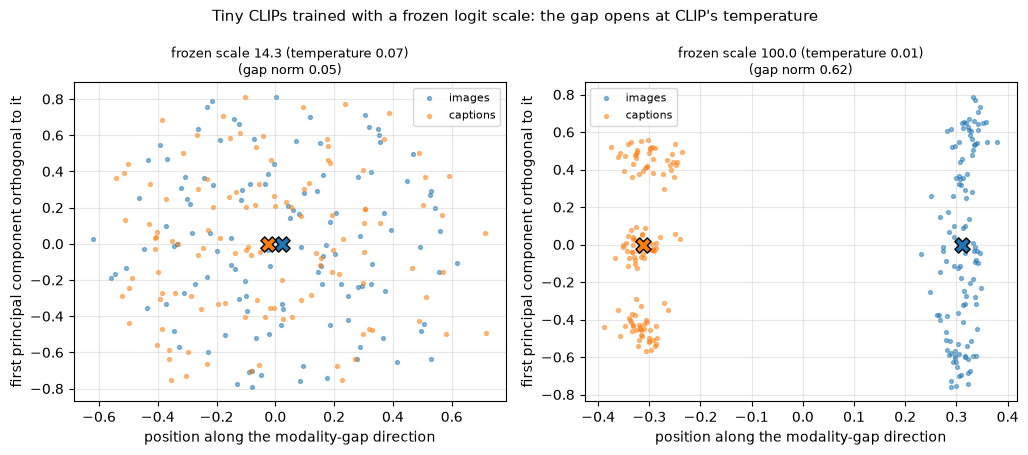

In [ ]:
temperature_models, temperature_panels = {}, {}
temperature_rows = {"learned scale (about 19)": gap_rows["tiny CLIP, trained"] | {"i2t R@1": evaluate_tiny(runs["CLIP loss, paired captions"][0], test_images, CAPTION_IDS, held_out_mask)["i2t"]}}
for scale in [1 / 0.07, 100.0]:
    m = fresh_model(scale_init=scale)
    m.logit_scale.requires_grad_(False)  # keep the temperature fixed during training
    train_tiny_clip(m, train_images, CAPTION_IDS, train_classes, "clip", "paired")
    img_e, txt_e = [x.cpu() for x in embed_all(m, test_images, CAPTION_IDS)]
    label = f"frozen scale {scale:.1f} (temperature {1 / scale:.2f})"
    temperature_rows[label] = gap_stats(img_e, txt_e, t.arange(120)) | {"i2t R@1": evaluate_tiny(m, test_images, CAPTION_IDS, held_out_mask)["i2t"]}
    temperature_panels[label] = (F.normalize(img_e, dim=-1).numpy(), F.normalize(txt_e, dim=-1).numpy())
display(pd.DataFrame(temperature_rows).T[["gap norm", "matched cos", "unmatched cos", "image-image cos", "text-text cos", "i2t R@1"]].round(3))
utils.plot_modality_gap(temperature_panels, "Tiny CLIPs trained with a frozen logit scale: the gap opens at CLIP's temperature")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">                                       gap norm  matched cos  unmatched cos  image-image cos  text-text cos  i2t R@1
learned scale (about 19)                  0.050        0.921         -0.007           -0.006         -0.007    0.942
frozen scale 14.3 (temperature 0.07)      0.044        0.931         -0.008           -0.007         -0.008    0.958
frozen scale 100.0 (temperature 0.01)     0.611        0.667          0.010            0.043          0.347    0.942</pre>
</details>

<details>
<summary>Help - how should I interpret this table and plot?</summary>

**Same architecture, same data, same steps and the same retrieval accuracy (0.94 to 0.96), but a very different geometry.** At a frozen scale of 14.3 the gap is 0.044 and the
matched cosine 0.93: captions and images land on the same points (left panel; the model with a learned scale, which ended at about 19, looks the same: gap 0.050). At CLIP's scale
of 100 the gap is 0.61, the matched cosine is only 0.67, and the plot shows two clouds far apart along the gap direction, with the captions packed into a few tight clusters (their
mean pairwise cosine is 0.35, against $-0.008$ at the lower scale) and the images spread more loosely on the other side.

This reproduces, on a small model, the temperature dependence that Liang et al. report. The arithmetic is suggestive: at a scale of 100 a matched cosine of 0.67 against 0.01 for an
unmatched pair is already a logit gap of 66, enough to make the loss essentially zero (it is 0.000 in this run) long before the two clouds meet. At a scale of 14.3 the same cosine
gap would be a logit gap of only 9, and the loss keeps rewarding matching pairs for coinciding.

Does the gap matter for retrieval? Not here: 0.942 against 0.958. It is a property of the geometry the loss *allows*, not something that retrieval needs. Real CLIP sits at the
clamp of 100, which is consistent with its large gap; SigLIP's scale is 117 with a bias of $-12.9$. Next we ask what happens to the real models when we move the clouds.
</details>

### Does the gap matter? A shift test, with a control

The gap is big, but is it *doing* anything? Here's a causal test. Shift every image embedding by $-\alpha\Delta$ (moving the image cloud towards the text cloud), re-normalise, and
redo the 90-way retrieval. If the gap is an obstacle to matching, closing it should help. As a **control**, shift by a *random* direction of exactly the same length: that tells us
whether any change is specific to the gap direction, or just what happens when you move embeddings by that much.

### Exercise - zero-shot accuracy after a shift

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `accuracy_after_shift`. It takes raw image embeddings `(n, d)`, raw text embeddings `(m, d)`, the index of each image's correct text `(n,)`, and a `shift` vector `(d,)`.
L2-normalise the image embeddings, **add** the shift to each, L2-normalise again, and return the fraction of images whose most similar text (by cosine similarity to the
L2-normalised text embeddings) is the correct one.

In [ ]:
def accuracy_after_shift(
    image_emb: Float[Tensor, "n d"], text_emb: Float[Tensor, "m d"], correct_text: Int[Tensor, " n"], shift: Float[Tensor, " d"]
) -> float:
    """Zero-shot top-1 accuracy after adding `shift` to the (normalised) image embeddings and re-normalising."""
    raise NotImplementedError()


tests.test_accuracy_after_shift(accuracy_after_shift)

<details>
<summary>Hint</summary>

Normalise the images, add `shift` (it broadcasts over the batch), normalise again, take the dot product with the normalised texts, then `argmax(dim=-1)`.
</details>


<details><summary>Solution</summary>

```python
def accuracy_after_shift(
    image_emb: Float[Tensor, "n d"], text_emb: Float[Tensor, "m d"], correct_text: Int[Tensor, " n"], shift: Float[Tensor, " d"]
) -> float:
    """Zero-shot top-1 accuracy after adding `shift` to the (normalised) image embeddings and re-normalising."""
    shifted = F.normalize(F.normalize(image_emb, dim=-1) + shift, dim=-1)
    predictions = (shifted @ F.normalize(text_emb, dim=-1).T).argmax(dim=-1)
    return (predictions == correct_text).float().mean().item()
```
</details>

In [ ]:
shift_rows = []
for kind in pairs:
    img, txt = fact[kind]["image"], fact[kind]["text"]
    gap = modality_gap(img, txt)
    row = {"model": kind, "no shift": accuracy_after_shift(img, txt, image_combo, t.zeros_like(gap))}
    for alpha in [0.5, 1.0]:
        row[f"close {alpha:.1f} of the gap"] = accuracy_after_shift(img, txt, image_combo, -alpha * gap)
    generator = t.Generator().manual_seed(0)
    random_accs = []
    for _ in range(20):
        direction = F.normalize(t.randn(gap.shape, generator=generator), dim=0)
        random_accs.append(accuracy_after_shift(img, txt, image_combo, direction * gap.norm()))
    row["random shift, same norm (mean of 20)"] = float(np.mean(random_accs))
    row["random shift, same norm (min..max)"] = f"{min(random_accs):.2f}..{max(random_accs):.2f}"
    shift_rows.append(row)
display(pd.DataFrame(shift_rows).set_index("model").round(3))

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">        no shift  close 0.5 of the gap  close 1.0 of the gap  random shift, same norm (mean of 20) random shift, same norm (min..max)
model
CLIP       0.778                 0.830                 0.678                                 0.426                         0.26..0.65
SigLIP     0.978                 0.989                 0.963                                 0.777                         0.51..0.97</pre>
</details>

<details>
<summary>Help - how should I interpret this table?</summary>

**Closing half of the gap helps; closing all of it hurts.** For CLIP, 90-way accuracy goes from 0.778 to 0.830 when we close half the gap, and falls to 0.678 when we close all of
it. SigLIP: 0.978, 0.989, 0.963. So the best gap isn't zero, which is a surprise if you think of the gap as an obstacle to matching.

**The control.** Shifting by the same *distance* in a random direction is much worse: CLIP falls to 0.43 on average (0.26 to 0.65 over 20 random directions) and SigLIP to 0.78
(0.51 to 0.97). So moving along the gap direction is cheap compared with moving along a typical direction. A sensible reading is that the gap lies along a direction on which the
captions barely differ from each other (every caption shares the large text-cone component), so shifting the images along it hardly changes *which* caption is nearest, whereas a
random direction of the same length swamps the small differences between captions on which retrieval depends. Notice the range for SigLIP, though: some random directions are almost
harmless (0.97). The control is a distribution, not a single number.

Overall, in these two models the gap is large, mostly irrelevant to which caption wins, and not obviously harmful. Removing it isn't the right fix.
</details>

## Attribute directions

The gap is a single global direction. What about the directions along which images *differ*? A very common picture of an embedding space is that attributes are **linear
directions**: there's a direction for "blue instead of red", and moving along it changes the colour and nothing else. The simplest way to estimate such a direction is a
**difference of means**. For colour pair $(a, b)$:

$$
d_{a \to b} = \underbrace{\text{mean}\left(\hat u_i : \text{colour}_i = b\right)}_{\text{all blue images, every shape and pattern}} - \underbrace{\text{mean}\left(\hat u_i :
\text{colour}_i = a\right)}_{\text{all red images}}
$$

Averaging over all the other attributes is what isolates colour: shapes and patterns appear equally often in both groups and cancel. We can do this in the image tower (using the
270 images) and **separately** in the text tower (using the 90 captions, averaging over shapes and patterns the same way). That gives two independently estimated directions,
$d^{img}_{a \to b}$ and $d^{txt}_{a \to b}$, one in each cone. Here's the question this section is built around: **do the two towers agree on what "blue instead of red" means?** If
they do, the cosine between $d^{img}$ and $d^{txt}$ will be large; if the towers each have their own private coordinate system, it will be about zero (which for $d = 512$ or $768$
means $\pm 0.04$).

### Exercise - implement `attribute_direction`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `attribute_direction`. It takes raw embeddings `(n, d)`, a list of `n` attribute values (strings, one per row), and two values `a` and `b`, and returns the difference of
means, `mean(normalised embeddings where value == b) - mean(normalised embeddings where value == a)`, shape `(d,)`. The embeddings are L2-normalised first so that both towers'
directions live on the same scale.

In [ ]:
def attribute_direction(emb: Float[Tensor, "n d"], values: list[str], a: str, b: str) -> Float[Tensor, " d"]:
    """Difference of means of the normalised embeddings: (rows with value b) minus (rows with value a)."""
    raise NotImplementedError()


tests.test_attribute_direction(attribute_direction)

<details>
<summary>Hint</summary>

Build two boolean masks over the rows (`values[i] == a` and `values[i] == b`), index the normalised embeddings with them, take the mean over the batch dimension of each, and
subtract.
</details>


<details><summary>Solution</summary>

```python
def attribute_direction(emb: Float[Tensor, "n d"], values: list[str], a: str, b: str) -> Float[Tensor, " d"]:
    """Difference of means of the normalised embeddings: (rows with value b) minus (rows with value a)."""
    emb = F.normalize(emb, dim=-1)
    is_a = t.tensor([v == a for v in values])
    is_b = t.tensor([v == b for v in values])
    return emb[is_b].mean(dim=0) - emb[is_a].mean(dim=0)
```
</details>

Now for every pair of values within an attribute (15 colour pairs, 10 shape pairs, 3 pattern pairs) we compute both directions and their cosine. We need two controls, both on the
same plot:

- **shuffled image labels**: the same procedure, but the image side uses attribute labels that have been randomly permuted over the 270 images. This keeps all the machinery (the means, the averaging) and destroys the meaning. The cosine with the real caption direction should drop to about zero.
- **a different attribute**: the cosine between the image direction for one *colour* pair and the caption direction for a *shape* pair. If the directions merely reflected some shared generic structure, this wouldn't be zero.


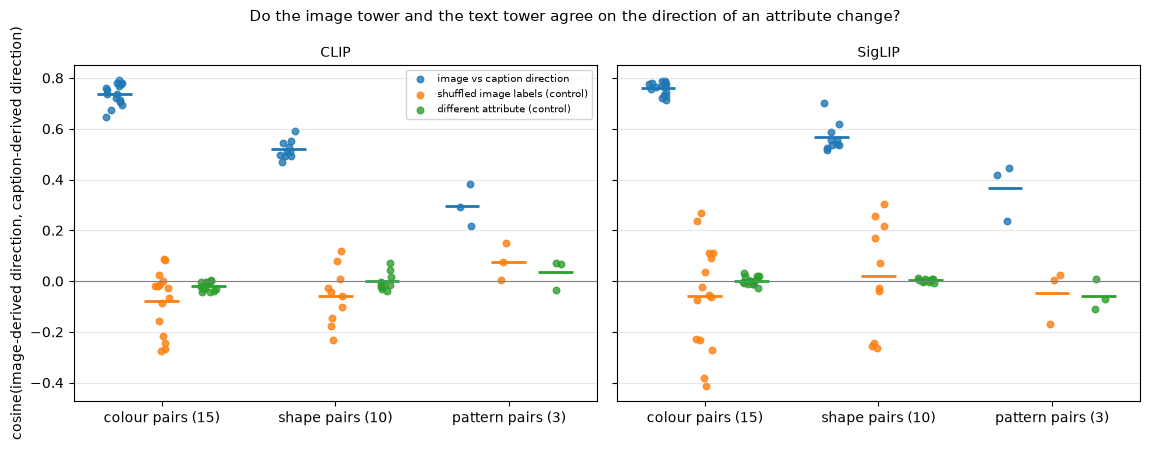

In [ ]:
def cosine(u: Tensor, v: Tensor) -> float:
    return F.cosine_similarity(u, v, dim=0).item()


values_of = {"colour": COLOURS, "shape": SHAPES, "pattern": PATTERNS}
generator = np.random.default_rng(0)
agreement: dict[str, dict[str, dict[str, list[float]]]] = {}
for kind in pairs:
    img, txt = fact[kind]["image"], fact[kind]["text"]
    agreement[kind] = {}
    for attr, values in values_of.items():
        other = "shape" if attr != "shape" else "colour"  # the 'different attribute' control uses the other attribute's pairs
        other_pairs = list(itertools.combinations(values_of[other], 2))
        shuffled = [image_attrs[attr][i] for i in generator.permutation(len(img))]
        real, shuffled_control, wrong_attr = [], [], []
        for k, (a, b) in enumerate(itertools.combinations(values, 2)):
            d_txt = attribute_direction(txt, attrs[attr], a, b)
            real.append(cosine(attribute_direction(img, image_attrs[attr], a, b), d_txt))
            shuffled_control.append(cosine(attribute_direction(img, shuffled, a, b), d_txt))
            c, d = other_pairs[k % len(other_pairs)]
            wrong_attr.append(cosine(attribute_direction(img, image_attrs[other], c, d), d_txt))
        agreement[kind][attr] = {"image vs caption direction": real, "shuffled image labels (control)": shuffled_control, "different attribute (control)": wrong_attr}
rows = [
    {"model": kind, "attribute": attr, **{k: f"{np.mean(v):+.2f} [{min(v):+.2f}, {max(v):+.2f}]" for k, v in series.items()}}
    for kind, per_attr in agreement.items()
    for attr, series in per_attr.items()
]
display(pd.DataFrame(rows).set_index(["model", "attribute"]))
utils.plot_direction_agreement(agreement, "Do the image tower and the text tower agree on the direction of an attribute change?")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">                 image vs caption direction shuffled image labels (control) different attribute (control)
model  attribute
CLIP   colour          +0.74 [+0.64, +0.79]            -0.08 [-0.27, +0.09]          -0.02 [-0.04, +0.00]
       shape           +0.52 [+0.47, +0.59]            -0.06 [-0.23, +0.12]          -0.00 [-0.04, +0.07]
       pattern         +0.30 [+0.22, +0.38]            +0.08 [+0.01, +0.15]          +0.03 [-0.03, +0.07]
SigLIP colour          +0.76 [+0.71, +0.79]            -0.06 [-0.41, +0.27]          +0.00 [-0.03, +0.03]
       shape           +0.57 [+0.52, +0.70]            +0.02 [-0.26, +0.30]          +0.00 [-0.01, +0.01]
       pattern         +0.37 [+0.24, +0.45]            -0.05 [-0.17, +0.02]          -0.06 [-0.11, +0.01]</pre>
</details>

<details>
<summary>Help - how should I interpret this table and plot?</summary>

**The towers agree.** The cosine between the image-derived and the caption-derived direction is +0.74 on average for colour pairs in CLIP and +0.76 in SigLIP (15 pairs each,
ranging from 0.64 to 0.79), 0.52 and 0.57 for shape pairs, and 0.30 and 0.37 for pattern pairs (3 pairs). These are large numbers in a space with hundreds of dimensions, where two
unrelated directions have a cosine of about $\pm 0.04$.

**The controls.** With shuffled image labels, the same procedure gives cosines averaging about 0 ($-0.08$ and $-0.06$ for colour pairs). Individual shuffled values can be sizeable
(down to $-0.41$ and up to $+0.30$), because a direction made from random subsets of images isn't an isotropic random vector: it lies in the subspace where the image embeddings
vary, which overlaps with the caption directions. They average out and none comes close to the real values. Across different attributes (the image direction for a colour pair
against the caption direction for a shape pair) the cosines are within $\pm 0.11$ of zero: different attributes are encoded in (nearly) orthogonal directions.

**The ordering colour > shape > pattern** follows the retrieval accuracies of the first table in this part (colour 0.996/1.0, shape 0.94/1.0, pattern 0.68/0.84): the better a model
is at an attribute, the more its two towers agree on its direction. The agreement is not perfect, even for colour, partly because each estimate is noisy (270 images, 90 captions)
and partly because of the modality gap: the two clouds sit in different places, and nothing forces the same displacement to be applied in both. Is 0.75 enough to *do* something?
That's the next question.
</details>

## Steering: moving an image embedding along a direction

A direction that two towers agree on should be *usable*. Take the embedding of a **red** shape, add $\alpha \cdot d_{\text{red} \to \text{blue}}$, re-normalise, and retrieve the
nearest of the 90 captions. If the direction means "blue instead of red", the nearest caption should become the *blue* caption with the **same shape and pattern**, and nothing else
should change. This is the editing-by-arithmetic trick that made word embeddings famous, done across modalities.

### Exercise - steer and retrieve

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `steer_and_retrieve`. It takes raw image embeddings `(n, d)`, a direction `(d,)`, a strength `alpha`, and raw text embeddings `(m, d)`; it L2-normalises the images, adds
`alpha * direction`, re-normalises, and returns for each image the index of the most cosine-similar text, shape `(n,)`.

In [ ]:
def steer_and_retrieve(
    image_emb: Float[Tensor, "n d"], direction: Float[Tensor, " d"], alpha: float, text_emb: Float[Tensor, "m d"]
) -> Int[Tensor, " n"]:
    """Index of the nearest text for each image after moving the image embedding by alpha * direction."""
    raise NotImplementedError()


tests.test_steer_and_retrieve(steer_and_retrieve)

<details>
<summary>Hint</summary>

This is `accuracy_after_shift` without the accuracy: the shift is `alpha * direction`, and you return the `argmax` rather than comparing it to anything.
</details>


<details><summary>Solution</summary>

```python
def steer_and_retrieve(
    image_emb: Float[Tensor, "n d"], direction: Float[Tensor, " d"], alpha: float, text_emb: Float[Tensor, "m d"]
) -> Int[Tensor, " n"]:
    """Index of the nearest text for each image after moving the image embedding by alpha * direction."""
    steered = F.normalize(F.normalize(image_emb, dim=-1) + alpha * direction, dim=-1)
    return (steered @ F.normalize(text_emb, dim=-1).T).argmax(dim=-1)
```
</details>

We steer all 45 red images (5 shapes × 3 patterns × 3 renders) towards blue, and count a **success** when the nearest caption is *exactly* the same-shape, same-pattern blue
caption. Strength $\alpha$ goes from 0 to 2.5; note that at $\alpha = 0$ the success rate is 0 by definition (the nearest caption is the red one). The curves:

- **image direction**: $d^{img}_{\text{red} \to \text{blue}}$ estimated from the images;
- **caption direction**: $d^{txt}_{\text{red} \to \text{blue}}$ estimated from the captions, applied to the image embeddings (the cross-modal version);
- **held-out shapes**: the image direction re-estimated from circles, squares and triangles *only*, applied to the red stars and hearts (never used to estimate it);
- **random direction**: a random direction with the same norm as the image direction (mean of 20 draws);
- **wrong attribute**: the circle $\to$ square shape direction, which has nothing to do with colour.


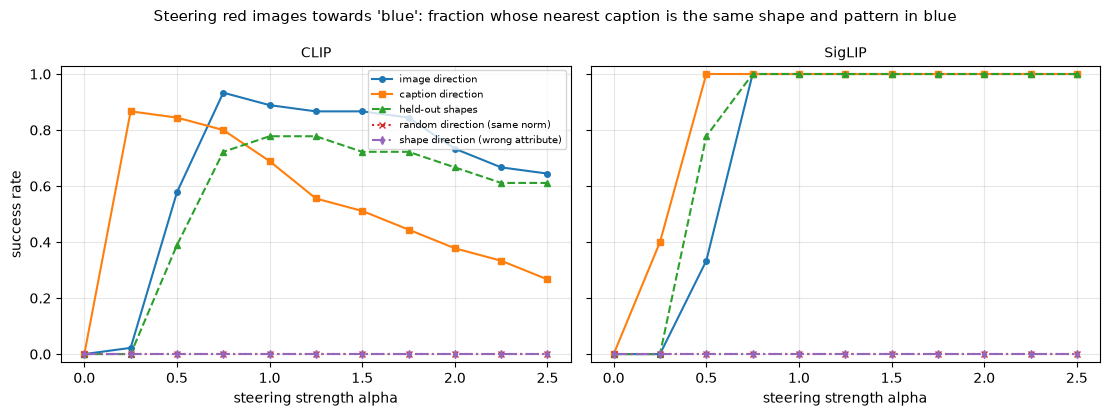

In [ ]:
alphas = [round(0.25 * k, 2) for k in range(11)]
red_images = [i for i, c in enumerate(image_attrs["colour"]) if c == "red"]
target = {i: COMBOS.index((image_attrs["shape"][i], "blue", image_attrs["pattern"][i])) for i in red_images}


def success_rate(kind: str, rows: list[int], direction: Tensor, alpha: float) -> float:
    pred = steer_and_retrieve(fact[kind]["image"][rows], direction, alpha, fact[kind]["text"])
    return (pred == t.tensor([target[i] for i in rows])).float().mean().item()


steering = {}
for kind in pairs:
    img, txt = fact[kind]["image"], fact[kind]["text"]
    d_img = attribute_direction(img, image_attrs["colour"], "red", "blue")
    d_txt = attribute_direction(txt, attrs["colour"], "red", "blue")
    train_rows = [i for i, s in enumerate(image_attrs["shape"]) if s in ("circle", "square", "triangle")]
    d_partial = attribute_direction(img[train_rows], [image_attrs["colour"][i] for i in train_rows], "red", "blue")
    d_shape = attribute_direction(img, image_attrs["shape"], "circle", "square")
    held_rows = [i for i in red_images if image_attrs["shape"][i] in ("star", "heart")]
    generator = t.Generator().manual_seed(0)
    random_dirs = [d_img.norm() * F.normalize(t.randn(d_img.shape, generator=generator), dim=0) for _ in range(20)]
    steering[kind] = {
        "image direction": (alphas, [success_rate(kind, red_images, d_img, a) for a in alphas]),
        "caption direction": (alphas, [success_rate(kind, red_images, d_txt, a) for a in alphas]),
        "held-out shapes": (alphas, [success_rate(kind, held_rows, d_partial, a) for a in alphas]),
        "random direction (same norm)": (alphas, [float(np.mean([success_rate(kind, red_images, r, a) for r in random_dirs])) for a in alphas]),
        "shape direction (wrong attribute)": (alphas, [success_rate(kind, red_images, d_shape, a) for a in alphas]),
    }
    best = {name: max(v) for name, (_, v) in steering[kind].items()}
    print(f"{kind:<7} |d_img| = {d_img.norm():.3f}, |d_txt| = {d_txt.norm():.3f}.  Best success over alpha: " + ", ".join(f"{n}: {v:.2f}" for n, v in best.items()))
utils.plot_steering_curves(steering, "Steering red images towards 'blue': fraction whose nearest caption is the same shape and pattern in blue", "success rate")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">CLIP    |d_img| = 0.251, |d_txt| = 0.457.  Best success over alpha: image direction: 0.91, caption direction: 0.87, held-out shapes: 0.78, random direction (same norm): 0.00, shape direction (wrong attribute): 0.00
SigLIP  |d_img| = 0.315, |d_txt| = 0.500.  Best success over alpha: image direction: 1.00, caption direction: 1.00, held-out shapes: 1.00, random direction (same norm): 0.00, shape direction (wrong attribute): 0.00</pre>

</details>

<details>
<summary>Help - how should I interpret this plot?</summary>

**SigLIP.** The image direction turns every red image into the exact blue caption with the same shape and pattern, for all $\alpha \ge 0.75$ up to 2.5; the
caption direction does the same from $\alpha = 0.5$. (At $\alpha = 1$ we add exactly the average red-to-blue difference.) **CLIP** behaves similarly but less
robustly. The image direction reaches 0.91 at $\alpha = 0.75$ and falls to 0.64 at 2.5. The caption direction (a longer vector: 0.457 against 0.251) peaks at
0.87 at $\alpha = 0.25$ and falls to 0.27 at 2.5. Success needs the *exact* caption, so once the shift is large enough to change the colour, any further push
starts changing other things as well (what does the retrieved caption look like at $\alpha = 2.5$? Print it and see).

**The controls fail where they should.** A random direction of the same norm gives 0.00 at every $\alpha$ for both models, and so does the shape direction (circle to square), which has nothing to do with colour. The effect is specific to the colour direction, and it isn't just "any large perturbation changes the nearest caption in the right way".

**Held-out shapes.** The direction estimated from circles, squares and triangles *only* works on red stars and hearts: 0.78 (CLIP) and 1.00 (SigLIP). The colour direction is shared across shapes, which is the practical meaning of "attributes are directions": colour is represented, to a good approximation, independently of the object it's applied to.
</details>

## Try it yourself - edit an image embedding

Now you can steer any image the way we steered the red ones. `steer_image` renders a *fresh* image (a new random seed, so it isn't one of the 270 used to estimate the direction),
moves it along the image direction from one colour to another, and prints the nearest caption at every strength. Try:

- other colour pairs and other shapes and patterns, e.g. `("star", "yellow", "purple", "striped")`;
- a pair of attributes which isn't a colour: you'll need to change which direction is used (`values_of`, `image_attrs` and `attribute_direction`) to `shape` or `pattern`. Does `plain` $\to$ `striped` work as well as `red` $\to$ `blue`? (Look back at the pattern row of the direction-agreement table first, and make a prediction.)
- much larger strengths: when does the caption stop making sense?


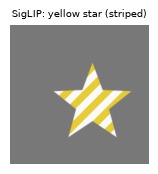

In [ ]:
@t.no_grad()
def steer_image(kind: str, shape: str, from_colour: str, to_colour: str, pattern: str = "plain", strengths=(0.0, 0.5, 1.0, 1.5, 3.0), seed: int = 7) -> None:
    pair = pairs[kind]
    image = utils.render_large(shape, from_colour, np.random.default_rng(seed), pattern)
    emb = pair.embed_images([Image.fromarray(image)])
    direction = attribute_direction(fact[kind]["image"], image_attrs["colour"], from_colour, to_colour)
    plt.figure(figsize=(1.8, 1.8))
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"{kind}: {from_colour} {shape} ({pattern})", fontsize=7)
    plt.show()
    captions = [combo_caption(*c) for c in COMBOS]
    for alpha in strengths:
        idx = steer_and_retrieve(emb, direction, alpha, fact[kind]["text"])[0].item()
        print(f"  alpha = {alpha:3.1f}  ->  {captions[idx]!r}")


steer_image("SigLIP", "star", "yellow", "purple", "striped")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">  alpha = 0.0  -&gt;  'a yellow striped star'
  alpha = 0.5  -&gt;  'a purple striped star'
  alpha = 1.0  -&gt;  'a purple striped star'
  alpha = 1.5  -&gt;  'a purple striped star'
  alpha = 3.0  -&gt;  'a purple striped star'</pre>

</details>

Even at $\alpha = 0.5$ (half of the average difference between yellow and purple images), the yellow striped star becomes `'a purple striped star'`, with shape and pattern intact,
and it stays that way up to $\alpha = 3$. This is a fresh image (a new random seed), not one of the 270 used to estimate the direction. Try much larger strengths, and other
attributes (SigLIP's pattern direction is weak: only 0.37 agreement between the towers).

## Language geometry: do captions add up?

The attribute directions above came from pictures of shapes. Let's test the same idea on language alone, in a more natural domain: clothing. We build every caption of the form

```
a {style} {colour} {material} {object}        e.g.  "a vintage red denim jacket"
```

from 4 styles (vintage, formal, casual, sporty), 6 colours (red, blue, green, black, white, yellow), 5 materials (denim, leather, wool, silk, cotton) and 6 objects (shirt, jacket,
dress, skirt, coat, hat): $4 \times 6 \times 5 \times 6 = 720$ captions, one for every combination. Embed all of them with each model's text tower.

If descriptions were embedded *additively*, so that each word's contribution just gets summed, the embedding of `"a vintage red denim jacket"` would be a base vector plus a
"vintage" vector plus a "red" vector plus a "denim" vector plus a "jacket" vector. How much of the variance of the 720 embeddings is explained by a purely additive model, and which
factor accounts for most of it?

Because the design is a full factorial (every combination appears exactly once), the variance partitions exactly. For each factor, the **between-group sum of squares** divided by
the total sum of squares is the fraction of variance that factor explains on its own (the $\eta^2$ of a one-way ANOVA), and since the factors are balanced these fractions add up to
the variance explained by the additive model. Whatever is left is **interaction**: variance that depends on the *combination* of attributes rather than on any one of them.

### Exercise - partition the variance

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement `variance_partition`. It takes raw embeddings `(n, d)` (L2-normalise them first) and a dict mapping each factor name to a list of `n` labels. It returns a dict with one
entry per factor, its $\eta^2$: the sum over groups of `group_size * ||group_mean - overall_mean||^2`, divided by the total sum of squares `sum_i ||x_i - overall_mean||^2`, plus an
entry `"interaction"` equal to `1 - sum(eta2 over factors)`.

In [ ]:
def variance_partition(emb: Float[Tensor, "n d"], factors: dict[str, list]) -> dict[str, float]:
    """eta-squared of each factor on the normalised embeddings, plus the leftover 'interaction' share."""
    raise NotImplementedError()


tests.test_variance_partition(variance_partition)

<details>
<summary>Hint</summary>

Centre the normalised embeddings once (`emb - emb.mean(0)`); then the group mean of the centred rows *is* `group_mean - overall_mean`. For each factor and each value, select the
rows with that label, take their mean, and add `len(group) * (mean**2).sum()`.
</details>


<details><summary>Solution</summary>

```python
def variance_partition(emb: Float[Tensor, "n d"], factors: dict[str, list]) -> dict[str, float]:
    """eta-squared of each factor on the normalised embeddings, plus the leftover 'interaction' share."""
    emb = F.normalize(emb, dim=-1)
    centred = emb - emb.mean(dim=0)
    total = (centred**2).sum()
    shares = {}
    for name, labels in factors.items():
        between = 0.0
        for value in sorted(set(labels)):
            group = centred[t.tensor([label == value for label in labels])]
            between += len(group) * (group.mean(dim=0) ** 2).sum()
        shares[name] = (between / total).item()
    shares["interaction"] = 1 - sum(shares.values())
    return shares
```
</details>


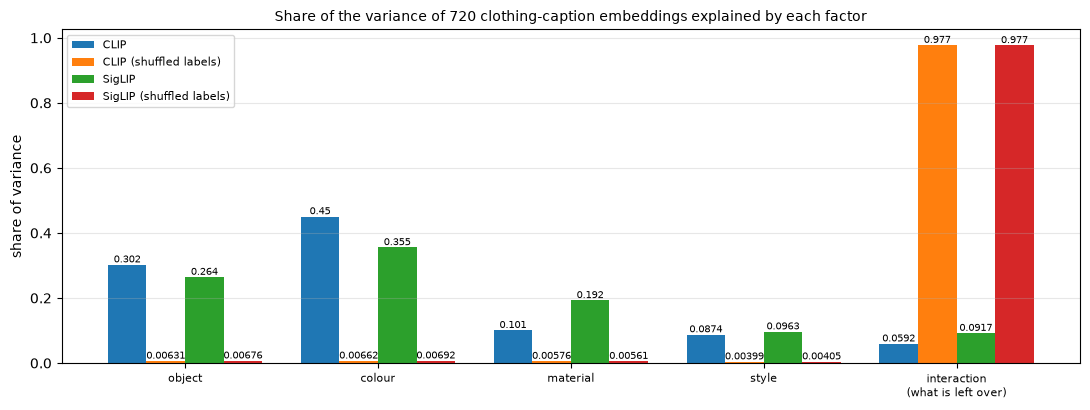

In [ ]:
OBJECTS = ["shirt", "jacket", "dress", "skirt", "coat", "hat"]
CLOTH_COLOURS = ["red", "blue", "green", "black", "white", "yellow"]
MATERIALS = ["denim", "leather", "wool", "silk", "cotton"]
STYLES = ["vintage", "formal", "casual", "sporty"]
clothes = list(itertools.product(OBJECTS, CLOTH_COLOURS, MATERIALS, STYLES))
cloth_captions = [f"a {style} {colour} {material} {obj}" for obj, colour, material, style in clothes]
cloth_factors = {
    "object": [c[0] for c in clothes],
    "colour": [c[1] for c in clothes],
    "material": [c[2] for c in clothes],
    "style": [c[3] for c in clothes],
}
print(len(cloth_captions), "captions, e.g.", cloth_captions[:2])

cloth_emb = {kind: pair.embed_texts(cloth_captions) for kind, pair in pairs.items()}
generator = np.random.default_rng(0)
partition = {}
for kind in pairs:
    real = variance_partition(cloth_emb[kind], cloth_factors)
    null = [
        variance_partition(cloth_emb[kind], {name: [labels[i] for i in generator.permutation(len(labels))] for name, labels in cloth_factors.items()})
        for _ in range(20)
    ]
    partition[kind] = real
    partition[f"{kind} (shuffled labels)"] = {k: float(np.mean([n[k] for n in null])) for k in real}
groups = {
    ("interaction\n(what is left over)" if factor == "interaction" else factor): {name: shares[factor] for name, shares in partition.items()}
    for factor in ["object", "colour", "material", "style", "interaction"]
}
display(pd.DataFrame(partition).round(3))
utils.plot_bars(groups, "Share of the variance of 720 clothing-caption embeddings explained by each factor", "share of variance")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">720 captions, e.g. ['a vintage red denim shirt', 'a formal red denim shirt']
              CLIP  CLIP (shuffled labels)  SigLIP  SigLIP (shuffled labels)
object       0.302                   0.006   0.264                     0.007
colour       0.450                   0.007   0.355                     0.007
material     0.101                   0.006   0.192                     0.006
style        0.087                   0.004   0.096                     0.004
interaction  0.059                   0.977   0.092                     0.977</pre>
</details>

<details>
<summary>Help - how should I interpret this table and plot?</summary>

**An additive model explains 91 to 94% of the variance of the 720 caption embeddings** (leftover interaction: 5.9% for CLIP and 9.2% for SigLIP). Each factor explains less than 1%
of the variance in the shuffled-label control. That is the chance level: with 720 captions the expected $\eta^2$ for a factor with $k$ values is about $(k-1)/719$, i.e. 0.7% for
six values and 0.4% for four. So the real shares are 40 to 100 times the chance level.

**Which factors?** Colour is the largest share (45% in CLIP and 36% in SigLIP), then object (30% and 26%), material (10% and 19%) and style (9% and 10%). In CLIP the colour word
moves a caption's embedding more than the object word does. That's a fact about what the training data rewards (colour words are very informative about how an image looks) and not
about English. SigLIP gives material twice the share it has in CLIP.

**The upshot.** To a good approximation, a caption's embedding is a *sum of per-word contributions*, with small interaction terms. Such an embedding can represent which attributes
a caption mentions, but not which of them go together. That's exactly the property which makes binding hard.
</details>

## Binding: which colour goes with which object?

Everything so far suggests a tidy picture: attributes are directions, captions add up, and the two towers agree. But an *additive* picture has a worrying consequence. If a
caption's embedding is a sum of contributions from its words, then

```
"a red circle and a blue square"      =      red + circle + blue + square      =      "a blue circle and a red square"
```

The two captions contain the same words, so a purely additive embedding can't tell them apart. Telling them apart requires **binding**: knowing that *red goes with the circle*. Whether models bind is tested by **Winoground** (Thrush et al., 2022, [*Winoground: Probing Vision and Language Models for Visio-Linguistic Compositionality*](https://arxiv.org/abs/2204.03162)), which gives a model two images and two captions made of the same words in a different order, and asks it to match them up correctly. Yuksekgonul et al. (2023, [*When and why vision-language models behave like bags-of-words*](https://arxiv.org/abs/2210.01936)) showed that CLIP-like models often can't, and argued that they behave like bags of words.

We'll build a synthetic Winoground. Each item consists of two images, each showing two different shapes side by side. The second image has the same two shapes as the first, with
their **colours swapped**:

| | image A | image B |
|---|---|---|
| left / right | red circle, blue square | blue circle, red square |
| the matching caption | `"a red circle and a blue square"` | `"a blue circle and a red square"` |

Both captions mention the same four words; only the binding differs. The scoring follows Winoground. Given the four image-caption scores $s_{AA}, s_{AB}, s_{BA}, s_{BB}$ (where
$s_{XY}$ is the similarity of image $X$ with caption $Y$), a model gets the **text score** if each image prefers its own caption ($s_{AA} > s_{AB}$ *and* $s_{BB} > s_{BA}$), the
**image score** if each caption prefers its own image ($s_{AA} > s_{BA}$ *and* $s_{BB} > s_{AB}$), and the **group score** only if it gets both. Random guessing gets the text and
image scores right a quarter of the time, and the group score one time in six.

### Exercise - implement the Winoground scores

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `winoground_scores`. It takes four tensors of shape `(n,)`, `s_aa`, `s_ab`, `s_ba`, `s_bb` (the score of image A with caption A, of image A with caption B, and so on, for
each of the $n$ items), and returns a dict with four floats:

- `"text"`: fraction of items with $s_{AA} > s_{AB}$ and $s_{BB} > s_{BA}$;
- `"image"`: fraction with $s_{AA} > s_{BA}$ and $s_{BB} > s_{AB}$;
- `"group"`: fraction where both of the above hold;
- `"pair_accuracy"`: the fraction of the $2n$ individual comparisons "does this image prefer its own caption over the swapped one?" that are right, i.e. the mean of $s_{AA} > s_{AB}$ and $s_{BB} > s_{BA}$ pooled over both images. Chance for this one is 0.5.

Ties count as failures (strict inequalities).

In [ ]:
def winoground_scores(
    s_aa: Float[Tensor, " n"], s_ab: Float[Tensor, " n"], s_ba: Float[Tensor, " n"], s_bb: Float[Tensor, " n"]
) -> dict[str, float]:
    """Winoground-style text, image and group scores, plus pooled pairwise accuracy. s_xy = score(image x, caption y)."""
    raise NotImplementedError()


tests.test_winoground_scores(winoground_scores)

<details>
<summary>Hint</summary>

Compute four boolean tensors: `s_aa > s_ab`, `s_bb > s_ba`, `s_aa > s_ba`, `s_bb > s_ab`. The text score is the mean of the AND of the first two, the image score the mean of the
AND of the last two, and the group score the mean of the AND of all four.
</details>


<details><summary>Solution</summary>

```python
def winoground_scores(
    s_aa: Float[Tensor, " n"], s_ab: Float[Tensor, " n"], s_ba: Float[Tensor, " n"], s_bb: Float[Tensor, " n"]
) -> dict[str, float]:
    """Winoground-style text, image and group scores, plus pooled pairwise accuracy. s_xy = score(image x, caption y)."""
    a_prefers_own, b_prefers_own = s_aa > s_ab, s_bb > s_ba  # each image prefers its own caption
    caption_a_prefers_own, caption_b_prefers_own = s_aa > s_ba, s_bb > s_ab  # each caption prefers its own image
    text = a_prefers_own & b_prefers_own
    image = caption_a_prefers_own & caption_b_prefers_own
    return {
        "text": text.float().mean().item(),
        "image": image.float().mean().item(),
        "group": (text & image).float().mean().item(),
        "pair_accuracy": 0.5 * (a_prefers_own.float().mean().item() + b_prefers_own.float().mean().item()),
    }
```
</details>

We generate 150 random items. As a **control** we add a caption which differs from the correct one by one *wrong colour word* (a colour that appears nowhere in the picture): `"a
green circle and a blue square"` for image A, where the circle is red. That is a much smaller change than swapping, in terms of the words changed, and the models should find it
easy: if they don't, the problem is the images or the format of our captions rather than binding.


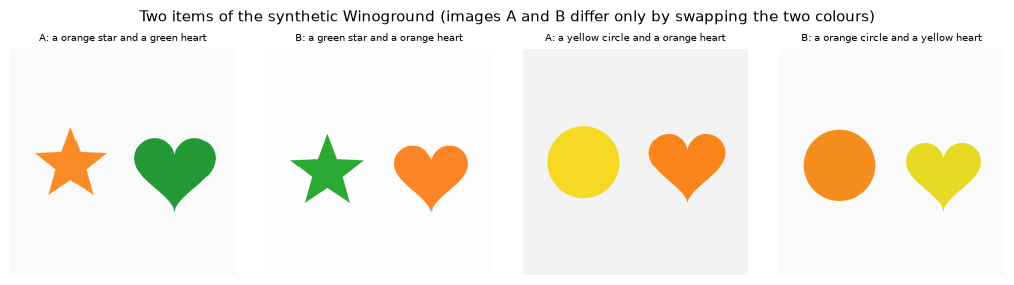

In [ ]:
rng = np.random.default_rng(0)
items = []
for _ in range(150):
    s1, s2 = rng.choice(SHAPES, 2, replace=False)
    c1, c2 = rng.choice(COLOURS, 2, replace=False)
    c3 = rng.choice([c for c in COLOURS if c not in (c1, c2)])
    items.append((str(s1), str(c1), str(s2), str(c2), str(c3)))
scene_a = [utils.render_large_pair((s1, c1), (s2, c2), rng) for s1, c1, s2, c2, _ in items]
scene_b = [utils.render_large_pair((s1, c2), (s2, c1), rng) for s1, c1, s2, c2, _ in items]
caption_a = [f"a {c1} {s1} and a {c2} {s2}" for s1, c1, s2, c2, _ in items]
caption_b = [f"a {c2} {s1} and a {c1} {s2}" for s1, c1, s2, c2, _ in items]
caption_c = [f"a {c3} {s1} and a {c2} {s2}" for s1, c1, s2, c2, c3 in items]  # control: a colour that isn't in the picture
utils.show_image_grid(
    np.stack([scene_a[0], scene_b[0], scene_a[1], scene_b[1]]),
    [f"A: {caption_a[0]}", f"B: {caption_b[0]}", f"A: {caption_a[1]}", f"B: {caption_b[1]}"],
    ncols=4,
    scale=2.6,
    title="Two items of the synthetic Winoground (images A and B differ only by swapping the two colours)",
)

In [ ]:
def binding_report(img_a: Tensor, img_b: Tensor, cap_a: Tensor, cap_b: Tensor, cap_c: Tensor) -> dict[str, float]:
    """Winoground scores for swapped colours, plus pairwise accuracy on the 'wrong colour word' control."""
    cos = lambda x, y: (F.normalize(x, dim=-1) * F.normalize(y, dim=-1)).sum(-1)
    scores = winoground_scores(cos(img_a, cap_a), cos(img_a, cap_b), cos(img_b, cap_a), cos(img_b, cap_b))
    # how often do the two images choose the SAME caption (i.e. the choice ignores the image)?
    scores["same_caption_for_both"] = ((cos(img_a, cap_a) > cos(img_a, cap_b)) == (cos(img_b, cap_a) > cos(img_b, cap_b))).float().mean().item()
    scores["control_accuracy"] = (cos(img_a, cap_a) > cos(img_a, cap_c)).float().mean().item()
    scores["caption_cos_swap"] = cos(cap_a, cap_b).mean().item()
    scores["caption_cos_wrong_colour"] = cos(cap_a, cap_c).mean().item()
    return scores


binding = {}
for kind, pair in pairs.items():
    binding[kind] = binding_report(
        pair.embed_images(utils.to_pil(scene_a)), pair.embed_images(utils.to_pil(scene_b)),
        pair.embed_texts(caption_a), pair.embed_texts(caption_b), pair.embed_texts(caption_c),
    )
display(pd.DataFrame(binding).T.rename(columns={
    "text": "text score", "image": "image score", "group": "group score", "pair_accuracy": "swap: pair accuracy", "same_caption_for_both": "both images pick the same caption",
    "control_accuracy": "wrong colour word: accuracy", "caption_cos_swap": "cos(caption A, swapped B)", "caption_cos_wrong_colour": "cos(caption A, wrong-colour C)",
}).round(3))
print("chance: text 0.25, image 0.25, group 0.167, pair accuracy 0.5")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">        text score  image score  group score  swap: pair accuracy  both images pick the same caption  wrong colour word: accuracy  cos(caption A, swapped B)  cos(caption A, wrong-colour C)
CLIP          0.12        0.060         0.02                0.527                              0.813                          1.0                      0.977                           0.893
SigLIP        0.18        0.127         0.04                0.553                              0.747                          1.0                      0.979                           0.844
chance: text 0.25, image 0.25, group 0.167, pair accuracy 0.5</pre>
</details>

<details>
<summary>Help - how should I interpret this table?</summary>

**Neither model binds.** Pooled over the 300 individual comparisons ("does this image prefer its own caption over the swapped one?"), the answer is right 52.7%
of the time for CLIP and 55.3% for SigLIP: coin flips. The Winoground scores are *below* chance: text score 0.12 and 0.18 (chance 0.25), image score 0.06 and
0.13, group score 0.02 and 0.04 (chance 0.167). That's not a bug, and it is more interesting than "at chance". The two swapped captions are almost the *same
vector* (cosine 0.977 and 0.979; compare 0.89 and 0.84 for a caption with one wrong colour word), so which one scores higher is decided mostly by
**caption-specific offsets that don't depend on the image**. In 81% (CLIP) and 75% (SigLIP) of the items the two images, which have opposite colours, choose the
*same* caption. If caption A beats caption B for both images, the model gets one of the two images wrong, and the text score (which needs both right) is zero
for that item. Winoground's chance levels assume two independent coin flips; a model whose preference ignores the image does worse than that.

**The control.** When the wrong caption has one *wrong colour word* (a colour that isn't in the picture) both models are right 100% of the time. It's the same
images and the same sentence structure, with a smaller change to the words. So the failure isn't about the images, the caption format, or the ability to read
colours. It's specific to *which* object has which colour. This matches the additive picture from the last section: swapping two words leaves the sum of the
words unchanged.
</details>

## Is it the architecture or the data? A tiny CLIP trained on two-object scenes

Both models fail at binding in a setting where they handle every single attribute well. Two explanations suggest themselves:

1. **Architecture / objective.** A dual encoder compresses an image into *one vector* and a caption into *one vector* and compares them with a dot product. Maybe that bottleneck can't represent "red goes with circle" in a way that a dot product can read out.
2. **Data.** On web data, captions rarely depend on binding. An image and a caption matching the *bag of attributes* is almost always enough to beat the other captions in a batch, so the model never needs to learn binding to reduce its loss.

We can test explanation 1 directly with the tiny CLIP and our training loop, because the tiny CLIP has *exactly* the dual-encoder bottleneck. Build a world of two-object scenes at
32×32 where every caption describes both objects, `"a red circle and a blue square"`, and train it with the ordinary loss. If the bottleneck makes binding impossible, the tiny CLIP
will fail too.

We construct the classes as ordered tuples (colour 1, shape 1, colour 2, shape 2) with the two colours different and the two shapes different: $30 \cdot 20 = 600$ of them. A class
and its **colour-swapped twin** (the same scene with the two colours exchanged) go together into either the training set or the test set, so that the test items are Winoground
pairs the model has *never seen either half of*: 80% of the pairs are for training and 20% for testing.

In [ ]:
TWO_CLASSES = [(c1, s1, c2, s2) for c1 in COLOURS for s1 in SHAPES for c2 in COLOURS for s2 in SHAPES if c1 != c2 and s1 != s2]
TWO_INDEX = {cls: i for i, cls in enumerate(TWO_CLASSES)}
swap_of = t.tensor([TWO_INDEX[(c2, s1, c1, s2)] for c1, s1, c2, s2 in TWO_CLASSES])  # colour-swapped twin of every class
wrong_colour_of = t.tensor([TWO_INDEX[([c for c in COLOURS if c not in (c1, c2)][0], s1, c2, s2)] for c1, s1, c2, s2 in TWO_CLASSES])
two_captions = [f"a {c1} {s1} and a {c2} {s2}" for c1, s1, c2, s2 in TWO_CLASSES]
two_caption_ids = tokenize_captions(two_captions, VOCAB, MAX_LEN).to(device)

twin_pairs = sorted({tuple(sorted((i, int(swap_of[i])))) for i in range(len(TWO_CLASSES))})  # 300 swap-closed pairs
order = np.random.default_rng(0).permutation(len(twin_pairs))
test_pairs = [twin_pairs[i] for i in order[: len(twin_pairs) // 5]]
train_pairs = [twin_pairs[i] for i in order[len(twin_pairs) // 5 :]]
two_train_classes = t.tensor(sorted(i for pair in train_pairs for i in pair))


def render_two_object_world(n_variants: int, seed: int) -> Tensor:
    rng = np.random.default_rng(seed)
    images = np.stack([[utils.render_tiny_pair((s1, c1), (s2, c2), rng) for c1, s1, c2, s2 in TWO_CLASSES] for _ in range(n_variants)])
    return t.tensor(images).permute(0, 1, 4, 2, 3).float() / 255


two_train_images = render_two_object_world(8, seed=0).to(device)
two_test_images = render_two_object_world(1, seed=1)[0].to(device)
print(f"{len(TWO_CLASSES)} classes in {len(twin_pairs)} swap pairs: {len(train_pairs)} pairs for training, {len(test_pairs)} held-out pairs for testing")
print("caption example:", two_captions[0], "<->", two_captions[int(swap_of[0])], "(swapped colours)")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">600 classes in 300 swap pairs: 240 pairs for training, 60 held-out pairs for testing
caption example: a red circle and a green square &lt;-&gt; a green circle and a red square (swapped colours)</pre>

</details>

In [ ]:
def tiny_binding(model: TinyCLIP, pairs_to_test: list[tuple[int, int]]) -> dict[str, float]:
    """Winoground scores of a tiny two-object model on the given (class A, swapped class B) pairs, with the wrong-colour control."""
    a = t.tensor([p[0] for p in pairs_to_test])
    b = swap_of[a]
    c = wrong_colour_of[a]
    img_a, _ = embed_all(model, two_test_images[a.to(device)], two_caption_ids[:1])
    img_b, _ = embed_all(model, two_test_images[b.to(device)], two_caption_ids[:1])
    _, cap_all = embed_all(model, two_test_images[:1], two_caption_ids)
    return binding_report(img_a, img_b, cap_all[a.to(device)], cap_all[b.to(device)], cap_all[c.to(device)])


two_runs = {}
for name, trained in [("tiny CLIP, trained on two-object scenes", True), ("tiny CLIP, untrained", False)]:
    m = fresh_model()
    if trained:
        hist = train_tiny_clip(m, two_train_images, two_caption_ids, two_train_classes, "clip", "paired", steps=2000)
        print(f"trained for 2000 steps, final loss {np.mean(hist['loss'][-50:]):.3f}")
    two_runs[name] = tiny_binding(m, test_pairs)
display(pd.DataFrame(two_runs).T.round(3))

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">trained for 2000 steps, final loss 0.081
                                          text  image  group  pair_accuracy  same_caption_for_both  control_accuracy  caption_cos_swap  caption_cos_wrong_colour
tiny CLIP, trained on two-object scenes  0.967  0.967  0.933          0.983                  0.033               1.0             0.679                     0.515
tiny CLIP, untrained                     0.000  0.000  0.000          0.500                  1.000               0.7             1.000                     0.998</pre>
</details>


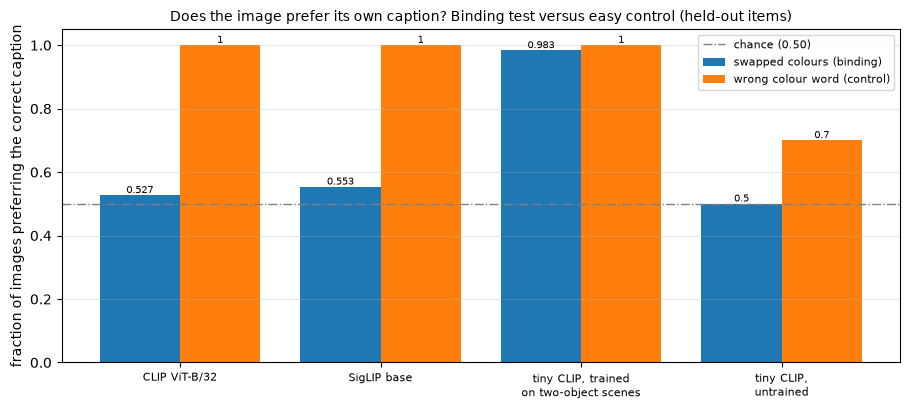

In [ ]:
summary = {
    "CLIP ViT-B/32": binding["CLIP"],
    "SigLIP base": binding["SigLIP"],
    "tiny CLIP, trained\non two-object scenes": two_runs["tiny CLIP, trained on two-object scenes"],
    "tiny CLIP,\nuntrained": two_runs["tiny CLIP, untrained"],
}
utils.plot_bars(
    {name: {"swapped colours (binding)": v["pair_accuracy"], "wrong colour word (control)": v["control_accuracy"]} for name, v in summary.items()},
    "Does the image prefer its own caption? Binding test versus easy control (held-out items)",
    "fraction of images preferring the correct caption",
    chance=0.5,
)

<details>
<summary>Help - how should I interpret this plot?</summary>

**The tiny model binds.** After 2,000 steps on 240 swap pairs it prefers its own caption on **98.3%** of the held-out pairs (neither image of which it ever saw), with a group score
of 0.933, against 0.02 to 0.04 for the real models. The wrong-colour-word control is at 1.0. Its swapped captions aren't nearly identical: their cosine is 0.68, against 0.98 for
the real models (and 0.52 for a wrong-colour caption). The untrained model is the degenerate case of the real ones, taken to the extreme: swapped captions have a cosine of 1.000,
and in 100% of the items both images choose the same caption, which gives pair accuracy of exactly 0.5 and a text score of 0.

**What this does and doesn't show.** It rules out the explanation that a dual encoder can't bind *by construction*. The one-vector-per-modality bottleneck, in a 220k-parameter pair
of transformers, can bind two colours to two shapes when the training data makes binding necessary: here every caption describes both objects, every colour-shape combination is
present, and so (plausibly) the other captions in a batch share objects and colours with the right one, and binding is the only way to tell them apart. It doesn't show that data is
the *whole* story for CLIP and SigLIP. They're trained on web data where captions rarely hinge on binding, at a vastly larger scale, and our toy tests the simplest case of two
objects in fixed positions. A fair summary: in this experiment binding failed when the training distribution didn't demand it and succeeded when it did, which is an explanation you
can test with hard negatives (see the Bonus).
</details>

## Summary of 4️⃣

- **The modality gap.** Images and captions occupy two separate narrow cones: the gap between their centres is about 1.0 to 1.2 (maximum 2), and matched pairs
  have cosines of only 0.15 to 0.34. The gap exists at random initialisation (cone effect, gap 1.38 in the untrained tiny CLIP), and whether it survives
  training depends on the temperature: in our tiny CLIP it disappears at a scale of 14 (gap 0.04) and persists at CLIP's scale of 100 (gap 0.61), with the same
  retrieval accuracy. In the real models, closing half the gap helps retrieval a little and closing it all hurts, whereas moving by the same distance in a
  random direction hurts much more.
- **Attributes are directions that the two towers share.** Colour, shape and pattern directions estimated independently from images and from captions have a
  cosine of +0.74/+0.76 (colour), 0.52/0.57 (shape), 0.30/0.37 (pattern), against about 0 for shuffled labels or different attributes. Adding the colour
  direction to an image embedding turns a red shape into its blue counterpart (SigLIP: 100% for $\alpha \ge 0.75$; CLIP: up to 91%), with random-direction and
  wrong-attribute controls at 0%, and a direction estimated from three shapes works on the other two.
- **Captions add up.** 91 to 94% of the variance of clothing-caption embeddings is explained by additive effects of object, colour, material and style (against under 1% per factor for shuffled labels), with colour the largest.
- **Binding fails, and it is a property of the training distribution rather than of the architecture.** Both real models are at chance on colour binding (pair
  accuracy 0.53/0.55, group score 0.02/0.04) while getting the easy control 100% right; their swapped captions have cosine 0.98 and both images usually pick the
  same caption. A tiny CLIP trained on two-object scenes binds on held-out pairs (0.98).

We've gone from a loss function to a picture of what the shared space looks like and doesn't represent. The later sections of this chapter build on these encoders: a
vision-language model sees through a CLIP-like image tower, and the failure modes we measured here (additive embeddings, the gap, binding) are the first things to check when it
misbehaves.

## What we did not show

- Our images are flat-coloured shapes with a few nuisance variations. Real photographs have clutter, occlusion, lighting and text, and we haven't tested the real models' geometry on them.
- We looked at two checkpoints, and each tiny model was trained from a single seed. Numbers such as 0.71 on held-out combinations, or 0.175 for the sigmoid loss with the CLIP-style initialisation, will move with the seed; the qualitative pattern is what we'd trust (the controls tell you how large a difference has to be before it means something).
- The temperature experiment varies one factor in one tiny setting. It reproduces the *direction* of the effect Liang et al. describe, and doesn't test their explanation of it.
- The binding test is about colours on two objects in fixed positions. It shows that these two models fail *this* test with the small caption change we made; it isn't a statement about all compositional reasoning. And the tiny CLIP's success tells you what is *possible* for the architecture when the data demands it, not why web-scale data doesn't.
- "Directions" are difference-of-means vectors. They show that attributes are linearly accessible and shared between the towers; they don't show that the models *use* a single direction internally.

# ☆ Bonus

## Hard negatives: the NegCLIP fix for binding

Yuksekgonul et al. (2023) proposed a cheap fix for bag-of-words behaviour: for every training pair, add a **hard-negative caption** made by swapping words in the real one (`"a red
circle and a blue square"` becomes `"a blue circle and a red square"`), and add it as an extra *column* to the image-to-text half of InfoNCE, so that each image must tell its
caption from its own word-swapped twin:

$$
S' = \left[\; S \;\middle|\; s\,\hat u_i \cdot \hat v^{\,\text{neg}}_i \;\right] \in \mathbb{R}^{N \times 2N}, \qquad \mathcal{L}_{i \to t}' = \text{cross-entropy}(S',
\text{labels} = 0, \dots, N-1).
$$

The text-to-image half is unchanged. Try this in the tiny two-object world:

- Implement `clip_loss_with_hard_negatives(logits, hard_negative_logits)`, and make a training loop (copy `train_tiny_clip`) in which each batch also embeds the colour-swapped twin of every caption (`swap_of`).
- **Predict** what happens to the held-out binding score in the setting where plain training *already* binds (the one we ran): can a hard negative help when the model already succeeds?
- Now make the problem harder, so that binding is no longer needed to reduce the loss: train on **only one member** of each swap pair (`train_pairs[k][0]`), so
  that the two members of a pair never co-occur. Does the plain model still bind on the held-out pairs? And with hard negatives? Beware: the swapped twin of a
  training image never appears as a *positive*, so the text tower could learn "swapped-looking captions are wrong" without looking at the image at all. How
  would you detect that? (Hint: evaluate with the image replaced by noise.)

## Batch size, temperature and the learning rate

- Sweep the batch size (8, 16, 32, 64, 96) at a fixed number of steps for both losses. The SigLIP paper reports that the sigmoid loss is at least on par with
  softmax, particularly at small batch sizes. In our exploratory runs of this tiny world the opposite happened at the smallest sizes: at a batch size of 16 the
  sigmoid model reached image-to-text R@1 of 0.57, 0.63 and 0.73 for three seeds, against 0.93, 0.86 and 0.92 for the softmax model, while at 32 the two were
  level (0.94 against 0.93, one seed). Check this yourself, and then find out what changes with the batch size for the sigmoid loss: its positive-to-negative
  ratio, the scale of its gradient, or both?
- The shuffled-caption control for SigLIP sat at a loss of 5.151, not at $\log 64 = 4.159$. Derive it: if the model can't tell pairs apart, the best it can do is give every pair the same logit $z$, and the loss is $\text{softplus}(-z) + (N-1)\,\text{softplus}(z)$. Minimise over $z$ and check that you get 5.151 for $N = 64$.
- The sigmoid loss was more fragile than InfoNCE in our exploratory runs when we raised the learning rate (the main runs use $5 \times 10^{-4}$). At $2 \times
  10^{-3}$ the SigLIP runs degraded (R@1 0.80 and 0.58 for two seeds, CLIP 0.96 and 0.97); at $5 \times 10^{-3}$ both SigLIP seeds ended at that same loss of
  5.151 with R@1 0.008 while CLIP still trained (0.96 and 0.98). Reproduce this, then look at the embeddings of a stuck model: what are the image-image cosines?
  Does a longer warmup help?
- Give the logit bias and scale their own, higher learning rate (as many CLIP reimplementations do for the temperature). Does the CLIP-style initialisation ($b = 0$) from Part 2 then catch up with the paper's without needing three times as many steps?

## SigLIP's scale and bias

Real CLIP sits at the clamp (scale 100) while SigLIP's learned scale is 117 with a bias of -12.9. Using `similarity_logits`, compute what *cosine similarity* corresponds to a 50%
match probability for SigLIP ($s\cos + b = 0$). Compare with the mean matched cosine you measured in Part 4. What does it say about how a typical correctly matched pair is scored?

## More attributes, and what the models don't know

- Extend the factorial test set with a size attribute (small/large) and with **counting** ("one star", "three stars"), and measure retrieval and the attribute directions for them. Which attributes have a direction on which the image and caption towers agree?
- Typographic attacks: render the *word* "circle" on an image of a square. Which does each model prefer, `"a square"` or `"a circle"`? Does it depend on the loss? (Goh et al., 2021, found CLIP neurons that respond to text and to its concept alike.)
- Position: use the same two-object scenes but swap the *positions* of the shapes (`"a circle to the left of a square"` against `"a square to the left of a circle"`), keeping the colours. Is spatial order harder or easier for the real models than colour binding?
- Probe for binding: train linear probes (with shuffled-label controls) to read "colour of the circle" from the image embeddings of the two-object scenes, and from the caption embeddings of their captions. When the real models fail the Winoground test, is the information missing from the embeddings, or present but not used by the dot product?

## Anomaly hunt

- In Part 4, closing *half* of the real models' modality gap helped retrieval (CLIP 0.78 to 0.83) while closing all of it hurt (0.68). Sweep the fraction finely in both models, and for both the factorial set and the CIFAR sample: is there a best fraction, and is it the same for the two models and the two datasets?
- In the held-out classes of the tiny CLIP, which attribute does the model get wrong when it fails (colour, shape or position)? Is it the same one for the CLIP and SigLIP runs?
- For CLIP, the steering success *falls* at large strengths. Print the retrieved caption at $\alpha = 2.5$ for the images that fail: which attribute breaks, and does it depend on the shape or pattern of the image?

## Further reading

- Radford et al. (2021), [*Learning Transferable Visual Models From Natural Language Supervision*](https://arxiv.org/abs/2103.00020). The CLIP paper: the loss, the batch size, the logit-scale clamp, zero-shot transfer.
- Zhai et al. (2023), [*Sigmoid Loss for Language Image Pre-Training*](https://arxiv.org/abs/2303.15343). The SigLIP paper, including the bias initialisation and the batch-size study.
- Tschannen et al. (2025), [*SigLIP 2*](https://arxiv.org/abs/2502.14786). Adds captioning, self-distillation and masked prediction losses on top of the sigmoid loss.
- van den Oord et al. (2018), [*Representation Learning with Contrastive Predictive Coding*](https://arxiv.org/abs/1807.03748). Where InfoNCE comes from; Zhang et al. (2020), [*ConVIRT*](https://arxiv.org/abs/2010.00747), the medical-imaging precursor of CLIP.
- Dosovitskiy et al. (2021), [*An Image is Worth 16x16 Words*](https://arxiv.org/abs/2010.11929). The vision transformer.
- Wang & Isola (2020), [*Understanding Contrastive Representation Learning through Alignment and Uniformity on the Hypersphere*](https://arxiv.org/abs/2005.10242). A cleaner theory of what InfoNCE optimises.
- Liang et al. (2022), [*Mind the Gap*](https://arxiv.org/abs/2203.02053). The modality gap and the cone effect.
- Thrush et al. (2022), [*Winoground*](https://arxiv.org/abs/2204.03162), and Yuksekgonul et al. (2023), [*When and why vision-language models behave like bags-of-words*](https://arxiv.org/abs/2210.01936). Compositionality benchmarks and the hard-negative fix.
- Goh et al. (2021), [*Multimodal Neurons in Artificial Neural Networks*](https://distill.pub/2021/multimodal-neurons/). An interpretability study of CLIP's units, including its typographic quirks.
- Cherti et al. (2023), [*Reproducible scaling laws for contrastive language-image learning*](https://arxiv.org/abs/2212.07143). How these models behave as data and compute grow (OpenCLIP).